# Эксперимент 2 — влияние архитектуры на детекцию task-relevant и task-irrelevant фичей

**PLAN.md, эксперимент 2.** *(Excessive architecture) + (task-irrelevant topology can be ignored).*
Датасеты те же, что в эксперименте 1: `simple_irrelevant` и `simple_relevant` — пара, в которой
окружность побитово одна и та же и различается только то, нужна ли она для решения задачи.
Переменная теперь — **размер сети**.

---

## Главная цель

Измерить, как архитектура — ширина и глубина — меняет детекцию task-relevant и task-irrelevant
фичей: появляется ли одиночный свидетель нерелевантной окружности, когда сети дают больше нейронов,
чем нужно для задачи, и что происходит с релевантной окружностью при минимуме и при избытке.

---

## Что делаем — коротко

**Шаг 0 (технический, не задача).** Минимальные решающие архитектуры и пул. Без него нет оси:
«избыточная архитектура» определена только относительно минимальной, а минимальная у двух датасетов
разная. Три подшага: трейдофф ширины и глубины (0.1), выбор пула (0.2), обучение (0.3).

Дальше — пять задач. Все читают один и тот же обученный пул; ширина и глубина суть оси внутри
каждой задачи, а не отдельные пункты.

**A. Task-irrelevant: производит ли избыточная архитектура свидетеля?**
Появляется ли детекция нерелевантной окружности с ростом числа нейронов, и растёт ли отрыв от пола.

**B. Task-relevant: что происходит при минимуме и при избытке.**
Остаётся ли одиночный свидетель на минимальной архитектуре, и держится ли доля свидетелей при
избытке.

**C. Свидетели по слоям.**
Продолжение уже померенного при 5x5 профиля вглубь, и сдвигается ли перелом с шириной.

**D. Ширина против глубины при равном бюджете нейронов.**
Одинаковое число нейронов, разная форма — чистый эффект расположения.

**E. Переобучение на избыточных архитектурах.**
Что происходит, если давать сети не только больше нейронов, чем нужно, но и больше времени, чем
нужно. Он же назначенный контроль конфаунда «ширина против длительности обучения».

**Перебора гиперпараметров критерия нет.** Конфигурация эксперимента 1 (`resolution = 200`,
`n_levels = 101`, `level_eps = "adaptive"`, `tau = 0.1`, `max_sample_points = 7000`) наследуется как
есть: бокс тот же, окружность та же, `N_A ~ 40` держится.

In [1]:
# ВАЖНО: до любого импорта torch. Обучение и оценка идут пулом процессов по
# одному потоку каждый; если родитель поднимет пул BLAS на 14-32 потока, воркеры
# будут драться за ядра и всё станет медленнее, а не быстрее.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# Корень репозитория как CWD, src/ в sys.path — соглашение слоя персистентности.
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "корень репозитория не найден"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))
print("CWD:", Path.cwd())

CWD: /home/serdabel/Desktop/proga/CL_neuron_level_sets


---

# Шаг 0 (технический). Минимальные решающие архитектуры и пул

Не задача эксперимента и не результат — без него просто нет оси. «Избыточная архитектура»
определена только относительно минимальной, а минимальная у двух датасетов разная.

## 0.1 Трейдофф ширины и глубины

Вопрос не «какая ширина нужна при глубине 1», а где вообще проходит граница решаемости в плоскости
(ширина, глубина): можно ли взять ширину 1–2 и добрать глубиной, и что посередине.

Для `simple_relevant` (диск r = 1 внутри окружности r = 1.5, разные классы) на это есть два
**аналитических** ответа, а не эмпирических.

**Ширина 1 не работает ни при какой глубине.** Если каждый скрытый слой шириной 1, то вся сеть есть
`phi(w·x + b)` для скалярной цепочки `phi`. Её линии уровня — прямые, а области решения —
объединения полос. Полоса, содержащая диск r = 1, обязана иметь полуширину >= 1 и потому захватывает
часть окружности r = 1.5.

**Ширина 2 не работает ни при какой глубине.** При ширине 2 отображение `x -> h_l` — композиция
обратимых аффинных отображений R^2 -> R^2 и покоординатного `tanh` (диффеоморфизма на `(-1, 1)`), то
есть **диффеоморфизм R^2 на открытое множество**. Выход — линейный функционал от `h_last`, значит
граница решения есть прообраз прямой при диффеоморфизме, а это всегда объединение дуг и **никогда
замкнутая кривая**. Замкнуть диск такая граница не может.

Из этого же довода следует то, что важнее для самого эксперимента:

> **Свидетель окружности требует ширины >= 3 и слоя >= 1.** Нейрон слоя l >= 1 при ширине 2 — это
> `tanh(строка · h_{l-1} + b)`, его линии уровня опять прообраз прямой при диффеоморфизме, то есть
> дуги. Замкнутых линий уровня в сети шириной 2 нет ни у одного нейрона, ни на каком слое. При
> ширине 3 образ первого слоя — двумерная поверхность в R^3, а плоскость может высечь из искривлённой
> поверхности замкнутую петлю; ровно на трёх это становится возможным. Слой 0 при любой ширине даёт
> прямые — это уже подтверждено данными эксперимента 1 (0 свидетелей из 250 на обоих датасетах).

То есть ячейки `w1`, `w2` и `d1` — **аналитически мёртвые**, и в них инструмент обязан вернуть ровно
ноль. Это бесплатный контроль валидности: ненулевой свидетель там означает сломанный инструмент, а не
найденный эффект.

Оговорка, которую надо проверить, а не постулировать: окружность в данных — 500 **точек**, а не
кривая, зазор между соседними ~ 0.019. Формально сеть шириной 2 может просочиться дугой в зазор.
Практически это вырожденное решение, и шаг 0 покажет, находит ли его градиентный спуск.

**Что делаем — лестничный поиск, а не полная сетка.** Нас интересует граница, а архитектуры заведомо
выше неё не сообщают ничего: они решают задачу по построению. Поэтому по каждой глубине d = 1…6 идём
от ширины 1 вверх и останавливаемся на первой ширине, где задачу решают >= 8 сидов из 10.

> **Порог 8/10 — это условие остановки лесенки, а не оценка границы.** Он превращает шумную
> биномиальную долю в бинарный ответ: при истинной вероятности успеха p = 0.9 и десяти сидах ячейка
> не проходит порог в 7 % случаев, а на шести глубинах хотя бы одна проваливается с вероятностью
> **0.35**. Именно так и появляется рваная граница, которой в природе нет. Выводы делаются по доле с
> доверительным интервалом (`capacity_probe.frontier_rates`), а не по «прошло / не прошло». Гейт — тот же, что в 0.3 (`target = 1.0`, `min_epochs = 0`,
`patience = 5`, потолок 300 эпох), сети крошечные, обучение ничего не сохраняет: это пробы, а не
члены ансамблей.

Записывается по каждому сиду не только «дошёл / не дошёл», но и `stopped_epoch` — потому что провал
имеет две разные причины, и их надо различать: решения нет в принципе (выразительность) или решение
есть, но градиентный спуск его не находит (оптимизация). Вторая узнаётся по тому, что часть сидов
доходит, а остальные упираются в потолок эпох.

Предсказание: для `simple_relevant` граница проходит по ширине 3 и почти не двигается с глубиной, для
`simple_irrelevant` минимум — один нейрон в одном слое.

Результат — `analysis/results/experiments/exp2_arch_sweep/step0_minimal_architectures.csv`
(по строке на (датасет, глубина)) и `step0_capacity_frontier.csv` (по строке на сид).

---

### Результат

Считалось дважды: сначала с бюджетом 300 эпох, потом с 3000. **Верны числа при 3000** — при 300
эпохах узкие и глубокие сети просто не успевали обучиться, и почти все странности первой таблицы
оказались этим.

#### Минимальная ширина равна 3 при любой глубине

`simple_relevant`, ширина 3, бюджет 3000 эпох — сколько сетей из 10 обучились до 100 % test accuracy
и удержали её 5 эпох подряд:

| глубина | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| дошло из 10 | 6 | 10 | 9 | 10 | 10 | 8 |
| ДИ 95 % | .31–.83 | .72–1.0 | .60–.98 | .72–1.0 | .72–1.0 | .49–.94 |
| медиана эпохи гейта | **2439** | 111 | 109 | 90 | 225 | 118 |

Пул по глубинам 2–6: **47/50 = 0.94**. Критерий однородности по глубинам: chi2 = 5.67, dof = 4,
**p = 0.22** — различия между глубинами неотличимы от биномиального шума. Поэтому вердикт:

> **Минимальная ширина для `simple_relevant` равна 3 при любой глубине; для `simple_irrelevant` — 1
> при любой глубине.** Трейдоффа между шириной и глубиной нет: граница решаемости — вертикальная
> прямая, а не лесенка.

Прежние (глубина, мин. ширина) = (3, 4) и (6, 4) были артефактом жёсткого порога, а не свойством
сети, и это не догадка: при p = 0.94 ячейка проваливает порог 8/10 в 1.9 % случаев, а хотя бы одна
из шести глубин — в 11 %.

#### Почему увеличение минимальной ширины с глубиной невозможно в принципе

Класс функций монотонен по глубине: `tanh(eps*x)/eps -> x` при `eps -> 0`, поэтому слой с малыми
весами приближает тождественное отображение сколь угодно точно, и сеть глубины d+1 приближает всё,
что приближает сеть глубины d той же ширины. Значит **минимальная ширина не может расти с глубиной**,
и любой такой рост в измерении — артефакт оценки. Это и было главным сигналом, что не так с порогом.

#### Ширина 3 — это n + 1, и это теорема, а не совпадение

Размерность входа n = 2, минимальная ширина 3 = n + 1. Совпадает с известной границей:

* **Johnson, ICLR 2019, «Deep, Skinny Neural Networks are not Universal Approximators».** Если все
  скрытые слои имеют ширину <= n, то **каждое множество уровня сети неограниченно**, при любой
  глубине. Это ровно тот довод про диффеоморфизм, что записан выше, только в общем виде и с
  доказательством.
* **Nguyen, Mukkamala, Hein, ICML 2018, «Neural networks should be wide enough to learn disconnected
  decision regions».** Сеть, у которой все ширины <= n, не может дать ограниченную или несвязную
  область решения.
* **Lu, Pu, Wang, Hu, Wang, NeurIPS 2017** и **Hanin, Sellke 2017**: ширина n + 1 достаточна для
  универсальной аппроксимации при неограниченной глубине, ширина n — нет.

Наша задача **требует** ограниченной области решения: диск внутри окружности, классы разные. Значит
ширина >= 3 необходима по теореме, а не по измерению. Измерение показало, что она же и достаточна:
ширина 1 и 2 дали **0 успехов на 180 сидах** (глубины 1–6 при 300 эпохах, плюс d = 7 и d = 10 при
3000), с потолком accuracy 0.665 при w1 и 0.895 при w2.

#### Глубина покупает не выразительность, а обучаемость

Медиана эпохи гейта при ширине 3: **2439** при d = 1 против 90–225 при d >= 2. Один добавочный слой
ускоряет обучение в двадцать раз, не меняя того, что сеть *может* представить. Это стандартная
картина: класс функций монотонен по глубине, а оптимизируемость — нет (канонический пример —
degradation problem у He et al. 2016, где более глубокая обычная сеть даёт **большую** ошибку на
обучении, что и мотивировало ResNet; механизм для tanh — насыщение и затухание градиента, Glorot,
Bengio 2010, и конечная глубина распространения сигнала в mean-field теории, Poole et al. 2016,
Schoenholz et al. 2017).

Отсюда же снимается моё прежнее утверждение, что глубина 1 — «отдельный режим, где решение находится,
но не удерживается». При 300 эпохах это выглядело так, потому что сеть была ещё далеко от сходимости
и accuracy колебалась. При 3000 эпохах глубина 1 сходится и удерживает: w3 — 6/10, w4 — 10/10.
Отдельного режима нет, есть одна ось — сколько эпох нужно до сходимости, — и глубина 1 на ней самая
медленная.

#### У ячейки два исхода и только два

`train_probe` останавливается досрочно **только** по гейту: accuracy >= 1.0 подряд `patience` = 5
эпох после `min_epochs` = 0. Иначе цикл доходит до `n_epochs`. Ни ранней остановки по плато, ни по
росту loss, ни защиты от расхождения — ничего этого нет. Поэтому «не дошла» означает ровно одно:
за отведённый бюджет не удержала 100 % пять эпох подряд. Чтобы отличать «решения нет» от «не успела»,
пишется `best_test_acc` за весь прогон: при w1 потолок 0.665, при w2 — 0.895, при w3 — ровно 1.0.

#### Минимальные архитектуры

| датасет | минимальная ширина | минимальные нейроны | практический минимум |
|---|---|---|---|
| `simple_relevant` | **3** при любой глубине | 3 (w3 d1) | **w3 d2 = 6 нейронов** (d = 1 стоит 2439 эпох против 111) |
| `simple_irrelevant` | **1** при любой глубине | 1 (w1 d1) | w1 d1 = 1 нейрон (53 эпохи) |

Референс 5x5 (25 нейронов) — это **8.3-кратный** избыток по нейронам для релевантной задачи (против
практического минимума в 6) и **25-кратный** для нерелевантной. По ширине — 1.7x и 5x.

#### Побочно измерен конфаунд задачи E

Медиана эпохи гейта на `simple_irrelevant`: 53.5 при w1 d1, 34–41 при d >= 2, и **12** при w5 d5
(эксперимент 1). Эпох до гейта падает в 4.4 раза от минимальной архитектуры к референсу — это и есть
величина, которую задача E меняет при неизменной архитектуре.

#### Практическое следствие для 0.3

`train_many_mlps_on_dataset_instance` делает ровно `n_models` попыток и сохраняет только успешные, то
есть `n_models` — это ПОПЫТКИ, а не модели. При доле успеха 0.94 на ширине 3 для 50 моделей нужно
~54 попытки; на ширине >= 4 отсева практически нет.

### 0.1 Повтор с большим бюджетом эпох

Гипотеза: немонотонность по глубине (при w3 доля падает с 8/10 при d = 2–4 до 6/10 при d = 5–6) —
не свойство архитектуры, а нехватка эпох. Узкая и глубокая сеть учится медленнее, а бюджет был
одинаковый для всех — 300 эпох. Проверяется прямо: тот же лестничный поиск с большим бюджетом.

Ширина 1 и 2 из поиска исключены. Там дело не в бюджете: решения не существует ни при какой
длительности обучения (диффеоморфизм, см. выше), и 120 сидов при 300 эпохах дали ровно 0 успехов при
потолке accuracy 0.67 и 0.825. Отдельная ячейка ниже проверяет это и на большом бюджете — одной
точки достаточно, потому что утверждение аналитическое, а не статистическое.

Глубина 1 тоже вынесена из основного поиска: там другой режим (решение достигается, но не
удерживается), и отвечает на него дешевле проба 0.1b, а не лесенка. Своя ячейка для неё — ниже.

**Цена.** Успешная ячейка стоит столько, сколько эпох до гейта (десятки), проваленная — весь бюджет.
Измеренная стоимость эпохи: 25 мс при w7 d1, 30 мс при w3 d2, 42 мс при w5 d9. То есть один
проваленный сид при бюджете 3000 эпох стоит 76–125 с, а ячейка из 10 сидов, где провалились все, —
13–21 минуту.

| бюджет | основной поиск (d = 2…6) | + глубина 1 | + проба 0.1b |
|---|---|---|---|
| 1000 | ~7 мин | +24 мин | +2 мин |
| **3000** | **~20 мин** | +72 мин | +7 мин |
| 10000 | ~65 мин | +4 ч | +22 мин |

Результаты кэшируются по ячейкам, и ключ кэша включает бюджет эпох, так что 300-эпохные числа не
подмешаются, а прерванный прогон продолжится с места остановки.

In [2]:
import torch, pandas as pd
torch.set_num_threads(2)   # крошечные сети: 14 потоков на матмуле 8x8 медленнее, чем 2

from training.capacity_probe import frontier_scan, frontier_table

N_EPOCHS  = 3000      # бюджет эпох; было 300
SEEDS     = 10
DEPTHS    = (1, 2, 3, 4, 5, 6)
THRESHOLD = 1.       # ячейка решает задачу, если дошли >= 10 сидов из 10

In [3]:
# Гейт — тот же, что в эксперименте 1 и в 0.3, менять здесь нечего:
# target_test_acc=1.0, min_epochs=0, patience=5, lr=1e-3, batch 64, adam.

# relevant: ширина 1 и 2 исключены (решения нет, см. markdown выше)
fr_rel, seeds_rel = frontier_scan(
    datasets=("relevant",), widths=(3, 4, 5, 6, 7, 8),
    depths=DEPTHS, seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
)

# irrelevant: там ширина 1 решает сразу, поэтому лесенка начинается с неё и тут же останавливается
fr_irr, seeds_irr = frontier_scan(
    datasets=("irrelevant",), widths=(1, 2, 3, 4),
    depths=DEPTHS, seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
)

frontier = pd.concat([fr_rel, fr_irr], ignore_index=True)
per_seed = pd.concat([seeds_rel, seeds_irr], ignore_index=True)

OUT = "analysis/results/experiments/exp2_arch_sweep"
frontier.to_csv(f"{OUT}/step0_minimal_architectures_ep{N_EPOCHS}.csv", index=False)
per_seed.to_csv(f"{OUT}/step0_capacity_frontier_ep{N_EPOCHS}.csv", index=False)
frontier

relevant   w3 d1: 6/10 дошло, медиана эпохи 2732
relevant   w4 d1: 10/10 дошло, медиана эпохи 1907
  -> минимальная ширина при d=1: 4

relevant   w3 d2: 10/10 дошло, медиана эпохи 111
  -> минимальная ширина при d=2: 3

relevant   w3 d3: 9/10 дошло, медиана эпохи 111
relevant   w4 d3: 10/10 дошло, медиана эпохи 61
  -> минимальная ширина при d=3: 4

relevant   w3 d4: 10/10 дошло, медиана эпохи 90
  -> минимальная ширина при d=4: 3

relevant   w3 d5: 10/10 дошло, медиана эпохи 225
  -> минимальная ширина при d=5: 3

relevant   w3 d6: 8/10 дошло, медиана эпохи 152
relevant   w4 d6: 10/10 дошло, медиана эпохи 66
  -> минимальная ширина при d=6: 4

irrelevant w1 d1: 10/10 дошло, медиана эпохи 53
  -> минимальная ширина при d=1: 1

irrelevant w1 d2: 10/10 дошло, медиана эпохи 41
  -> минимальная ширина при d=2: 1

irrelevant w1 d3: 10/10 дошло, медиана эпохи 34
  -> минимальная ширина при d=3: 1

irrelevant w1 d4: 10/10 дошло, медиана эпохи 37
  -> минимальная ширина при d=4: 1

irrelevant 

,dataset,depth,min_width,min_neurons,n_epochs_budget,note
0,relevant,1,4,4,3000,
1,relevant,2,3,6,3000,
2,relevant,3,4,12,3000,
3,relevant,4,3,12,3000,
4,relevant,5,3,15,3000,
5,relevant,6,4,24,3000,
6,irrelevant,1,1,1,3000,
7,irrelevant,2,1,2,3000,
8,irrelevant,3,1,3,3000,
9,irrelevant,4,1,4,3000,


In [4]:
for ds in ("relevant", "irrelevant"):
    piv, n = frontier_table(per_seed, ds, seeds=SEEDS)
    print(f"\n=== simple_{ds}, бюджет {N_EPOCHS} эпох ===")
    print(f"в клетке — сколько сетей из {n} обучились до 100 % test accuracy и удержали её 5 эпох подряд")
    print("строки — ширина слоя, столбцы — число скрытых слоёв")
    print("пусто — не считалось: лесенка остановилась левее, граница уже найдена")
    print(piv.to_string(na_rep=" ."))

print("\n=== минимальная архитектура при каждой глубине ===")
print(frontier.to_string(index=False))


=== simple_relevant, бюджет 3000 эпох ===
в клетке — сколько сетей из 10 обучились до 100 % test accuracy и удержали её 5 эпох подряд
строки — ширина слоя, столбцы — число скрытых слоёв
пусто — не считалось: лесенка остановилась левее, граница уже найдена
depth   1     2   3     4     5   6
width                              
3       6    10   9    10    10   8
4      10  <NA>  10  <NA>  <NA>  10

=== simple_irrelevant, бюджет 3000 эпох ===
в клетке — сколько сетей из 10 обучились до 100 % test accuracy и удержали её 5 эпох подряд
строки — ширина слоя, столбцы — число скрытых слоёв
пусто — не считалось: лесенка остановилась левее, граница уже найдена
depth   1   2   3   4   5   6
width                        
1      10  10  10  10  10  10

=== минимальная архитектура при каждой глубине ===
   dataset  depth  min_width  min_neurons  n_epochs_budget note
  relevant      1          4            4             3000     
  relevant      2          3            6             3000     
  rele

In [5]:
# Граница по долям с доверительными интервалами, а не по «прошло / не прошло» порог.
from training.capacity_probe import frontier_rates, homogeneity_test

rates = frontier_rates(per_seed)
print(rates.to_string(index=False))

chi2, pval, dof, pooled = homogeneity_test(per_seed, "relevant", width=3, depths=(2, 3, 4, 5, 6))
print(f"\nширина 3, глубины 2-6: пул {pooled:.3f}; "
      f"однородность по глубинам chi2={chi2:.2f}, dof={dof}, p={pval:.3f}")
print("p велико -> различия между глубинами неотличимы от биномиального шума,")
print("то есть минимальная ширина одна и та же при всех глубинах.")

   dataset  width  depth  reached  n  rate    ci_lo    ci_hi  median_gate_epoch
irrelevant      1      1       10 10   1.0 0.722467 1.000000               53.5
irrelevant      1      2       10 10   1.0 0.722467 1.000000               41.5
irrelevant      1      3       10 10   1.0 0.722467 1.000000               34.5
irrelevant      1      4       10 10   1.0 0.722467 1.000000               37.0
irrelevant      1      5       10 10   1.0 0.722467 1.000000               35.0
irrelevant      1      6       10 10   1.0 0.722467 1.000000               37.5
  relevant      3      1        6 10   0.6 0.312674 0.831820             2439.0
  relevant      3      2       10 10   1.0 0.722467 1.000000              111.5
  relevant      3      3        9 10   0.9 0.595850 0.982124              109.0
  relevant      3      4       10 10   1.0 0.722467 1.000000               90.5
  relevant      3      5       10 10   1.0 0.722467 1.000000              225.0
  relevant      3      6        8 10   0

In [6]:
# Необязательно. Проверка, что ширина 1 и 2 не спасаются большим бюджетом:
# утверждение аналитическое, поэтому одной глубины достаточно.
# Цена: 2 ячейки x 10 сидов x весь бюджет ~ 25-40 мин при N_EPOCHS = 3000.

# fr_w12, seeds_w12 = frontier_scan(
#     datasets=("relevant",), widths=(1, 2), depths=(7,),
#     seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
# )
# g = seeds_w12.groupby("width").agg(дошло=("reached", "sum"),
#                                    потолок_accuracy=("best_test_acc", "max"))
# print(g.to_string())

In [7]:
# Необязательно. Проверка, что ширина 1 и 2 не спасаются большим бюджетом:
# утверждение аналитическое, поэтому одной глубины достаточно.
# Цена: 2 ячейки x 10 сидов x весь бюджет ~ 25-40 мин при N_EPOCHS = 3000.

# fr_w12, seeds_w12 = frontier_scan(
#     datasets=("relevant",), widths=(2,), depths=(10,),
#     seeds=SEEDS, n_epochs=N_EPOCHS, threshold=THRESHOLD,
# )
# g = seeds_w12.groupby("width").agg(дошло=("reached", "sum"),
#                                    потолок_accuracy=("best_test_acc", "max"))
# print(g.to_string())

## 0.2 Пул архитектур

Шаг 0.1 показал, что граница решаемости — **вертикальная прямая на ширине 3**, а не лесенка. Значит
трейдоффа ширины и глубины нет, избыточность распадается на две независимые оси, и пул — это крест
плюс одна диагональ, а не сетка.

**Ширины геометрические, а не арифметические.** Закон кратности из эксперимента 1 степенной
(`N^(-0.28)`), и механизм PLAN тоже мультипликативный; степенная зависимость выявляется по точкам,
равномерным в логарифме.

| ряд | `simple_irrelevant` | `simple_relevant` | что покупает |
|---|---|---|---|
| ширина при d = 5 | 1, 2, 3, **5**, 10, 20 | 3, **5**, 10, 20 | главная ось PLAN |
| глубина при w = 5 | 1, 2, 3, **5**, 8 | то же | ось, вдоль которой свидетель становится возможен |
| равный бюджет ~24 | (24,1), (12,2), (8,3), **(5,5)**, (3,8) | то же | ширина против глубины при постоянном числе попыток |

**Ширина 1 и 2 только на `simple_irrelevant`** — на `simple_relevant` там нечего обучать, задача
неразрешима по теореме, а мы оцениваем только сети со 100 % accuracy. На `simple_irrelevant` сети
шириной 1 достигают 100 % при любой глубине (измерено, 10/10 на всех шести), и это единственная во
всём эксперименте проверка, где правильный ответ известен заранее из теоремы Джонсона: ноль
свидетелей, потому что у сети шириной <= входной размерности каждое множество уровня неограниченно.
Ненулевой свидетель там означает сломанный инструмент, а не найденный эффект.

**N = 50 во всех ячейках.** Разное N экономило бы около 15 % оценки, но делало бы ячейки
неодинаково точными: доверительный интервал на долю при 25 моделях вдвое шире, чем при 50, и кривая
по ширине читалась бы через меняющуюся вместе с ней погрешность.

**Ряд ширины стоит при d = 5, а не при d = 3 или 4.** Довод не в переиспользовании референса, а в
доказательности: эксперимент 1 померил при d = 5, что детектор в рабочем диапазоне (94 % свидетелей
на последнем слое relevant, ноль на irrelevant). При d = 3 профиль по слоям неизвестен, и если он
окажется слабым, весь ряд ляжет у нуля — тогда нулевой результат по ширине станет неинтерпретируемым:
«ширина не помогает» и «на этой глубине свидетелей нет вообще» неразличимы. Это вопрос задачи E, и
пока она не отвечена, ставить на неё главную ось нельзя.

**Ряд глубины стоит при w = 5, а не при минимальной w = 3** — по двум методологическим причинам, а не
ради удобства. Первая: при ширине 3 доля успеха 0.94, а при (3, d=1) — 0.6, то есть ансамбль
обусловлен успехом, и обусловленность зависит от глубины; кривая по глубине смешивала бы «глубина
меняет свидетельствование» с «глубина меняет, какие сиды выжили». При ширине >= 4 отсева нет. Вторая:
на минимальной ширине избытка нет по определению, а incidental-свидетельствование есть явление
избытка — мерить его там значит мерить в единственном режиме, где предмет отсутствует. Минимальная
ширина в дизайне остаётся ячейкой (3, 8) из ряда равного бюджета.

**Референсная ячейка (5,5) переиспользуется как есть.** Её тег — `tanh_w5_d5_mass-train`, а не
`tanh_w5_d5`: так её сохранил эксперимент 1. `Cell(model_name=...)` прикалывает тег, поэтому
эксперимент 2 читает ровно тот ансамбль, который эксперимент 1 померил, а не похожий заново
обученный.

In [8]:
from analysis.parallel_eval import Cell, SECONDS_PER_ROW
from experiments.registry import EXPERIMENTS
import pandas as pd

SPEC = EXPERIMENTS["exp2_arch_sweep"]
N_FEATURES = 1 + len(SPEC.eval.null_placements)   # цель + два нуль-размещения
REF = "tanh_w5_d5_mass-train"                     # тег ансамбля эксперимента 1

N_MODELS = 50          # одинаково во всех ячейках: сравнимость важнее экономии

WIDTH_ROW  = [(1, 5), (2, 5), (3, 5), (5, 5), (10, 5), (20, 5)]
DEPTH_ROW  = [(5, 1), (5, 2), (5, 3), (5, 5), (5, 8)]
BUDGET_ROW = [(24, 1), (12, 2), (8, 3), (5, 5), (3, 8)]

POOL = []
for dataset in ("simple_irrelevant", "simple_relevant"):
    seen = set()
    for width, depth in WIDTH_ROW + DEPTH_ROW + BUDGET_ROW:
        if (width, depth) in seen:
            continue
        # ширина <= 2 разрешима только на irrelevant: на relevant таких сетей нет
        if width <= 2 and dataset == "simple_relevant":
            continue
        seen.add((width, depth))
        POOL.append(Cell(
            dataset=dataset, width=width, depth=depth, n_models=N_MODELS,
            model_name=REF if (width, depth) == (5, 5) else None,
        ))

est = pd.DataFrame([{
    "dataset": c.dataset, "w": c.width, "d": c.depth, "нейронов": c.n_neurons,
    "N": c.n_models, "тег": c.tag,
    "строк": c.n_neurons * c.n_models * N_FEATURES,
} for c in POOL])
rows = int(est["строк"].sum())
print(est.to_string(index=False))
print(f"\nячеек {len(POOL)}, строк {rows}, фич на нейрон {N_FEATURES}")
print(f"оценка критериев: {rows * SECONDS_PER_ROW / 3600:.1f} ч последовательно")
for j in (8, 16, 32):
    print(f"   на {j:2d} воркерах ~ {rows * SECONDS_PER_ROW / 60 / j:.0f} мин")

# Бокс оценки задан в спеке ЯВНО и одинаков для обоих датасетов. Проверяем это
# глазами до запуска: N_A = diam(A)/max(h) — единственная переносимая величина
# из эксперимента 1, и она обязана совпасть между датасетами (и с его 44.2).
import torch
from management.experiment_management import load_dataset_instance, get_feature_points
from analysis.parallel_eval import config_fingerprint, parts_dir_for

print(f"\nбокс: {SPEC.eval.bounds} | resolution = {SPEC.eval.resolution}")
for ds in SPEC.datasets:
    L = load_dataset_instance(f"data/dataset_instances/{ds.name}/{ds.name}_0",
                              map_location="cpu", reconstruct_data=False)
    A = get_feature_points(L, ds.target_feature)
    diam = float(torch.cdist(A, A).max())
    h = max((hi - lo) / (SPEC.eval.resolution - 1) for lo, hi in SPEC.eval.bounds)
    print(f"  {ds.name:18s} diam(A) = {diam:.3f}  h = {h:.4f}  N_A = {diam / h:.1f}")
print(f"\nотпечаток конфигурации: {config_fingerprint(SPEC)} -> {parts_dir_for(SPEC)}")

          dataset  w  d  нейронов  N                   тег  строк
simple_irrelevant  1  5         5 50            tanh_w1_d5    750
simple_irrelevant  2  5        10 50            tanh_w2_d5   1500
simple_irrelevant  3  5        15 50            tanh_w3_d5   2250
simple_irrelevant  5  5        25 50 tanh_w5_d5_mass-train   3750
simple_irrelevant 10  5        50 50           tanh_w10_d5   7500
simple_irrelevant 20  5       100 50           tanh_w20_d5  15000
simple_irrelevant  5  1         5 50            tanh_w5_d1    750
simple_irrelevant  5  2        10 50            tanh_w5_d2   1500
simple_irrelevant  5  3        15 50            tanh_w5_d3   2250
simple_irrelevant  5  8        40 50            tanh_w5_d8   6000
simple_irrelevant 24  1        24 50           tanh_w24_d1   3600
simple_irrelevant 12  2        24 50           tanh_w12_d2   3600
simple_irrelevant  8  3        24 50            tanh_w8_d3   3600
simple_irrelevant  3  8        24 50            tanh_w3_d8   3600
  simple_r

## 0.3 Обучение

Все ячейки на обоих датасетах, одним прогоном, гейт **как в эксперименте 1, без изменений**:

```
target_test_acc = 1.0
min_epochs      = 0
patience        = 5
n_epochs        = 300
batch 64, lr 1e-3, adam
```

Измеренные там медианы остановки: **12 эпох** на `simple_irrelevant` (6–19) и **41** на
`simple_relevant` (25–219).

При этом гейте остаётся конфаунд: задача линейно разделима, более широкая сеть берёт 100 % быстрее,
то есть **ширина конфаундирована длительностью обучения**. Он не устраняется, а переносится в
отчётность: `stopped_epoch` пишется по каждой ячейке и показывается рядом с каждой кривой задач A и
B. Если кривая коррелирует с ним поперёк ячеек — это альтернативное объяснение, и разрешает его
**задача E**, где те же самые большие сети специально учатся дольше, чем нужно для 100 %. То есть E —
не довесок к эксперименту, а назначенный контроль его главного конфаунда.

---

### Порядок запуска

Прогнать подряд: **ячейку бутстрапа (самая первая в ноутбуке), затем всю секцию 0.2, затем всю
0.3**. Секция 0.1 нужна только для того, чтобы получить границу решаемости заново — её результат уже
записан, и для обучения с оценкой она не требуется.

0.2 определяет `SPEC` и `POOL`; 0.3 использует их и определяет `N_JOBS`. Между ними ничего другого
запускать не нужно.

### Как это запускается

Обе стадии идут пулом процессов и обе **возобновляемы**: прерванный прогон продолжается с места
остановки, ничего посчитанного не пересчитывается.

**Обучение** — `training/parallel_train.py::train_pool` над `scripts/train_cell.py`, один процесс на
(датасет, архитектура). Ячейка считает уже сохранённые успешные прогоны своего тега и доучивает
только недостачу; ячейка, у которой ансамбль уже полный, не делает ничего. Гонок нет по построению:
каждая ячейка пишет в собственное пространство имён `{instance}_{tag}_model{id}`.

Помните, что `train_many_mlps_on_dataset_instance` принимает **попытки**, а не модели. `train_cell.py`
раздувает бюджет попыток на измеренную долю успеха (0.94 при ширине 3, 1.0 при ширине >= 4) и после
прогона пересчитывает фактическое число; недобор печатается предупреждением, а не поглощается.

**Оценка критериев** — `analysis/parallel_eval.py::evaluate_parallel` над `scripts/eval_shard.py`.
Шард — это (датасет, архитектура, кусок списка моделей), размер куска подбирается по целевому числу
строк, поэтому все шарды примерно одинаковы по времени, несмотря на двадцатикратную разницу между
ячейками. Одна часть CSV на шард; часть появляется только когда она полна.

Слияние пишет ровно тот layout, что делает `runner.evaluate` — `neuron_stats_{тег}.csv` плюс сайдкар,
— поэтому стадия 4 (`runner.aggregate`) работает без единой правки.

**Про бокс оценки.** `EvalSpec.bounds` задан явно и общий для обоих датасетов. По умолчанию бокс
выводится из данных каждого датасета и растягивается под нуль-размещения — и тогда он оказывается
функцией не только задачи, но и набора нулей. Первый прогон эксперимента 2 на это и наступил: отказ
от двух из четырёх размещений эксперимента 1 сжал бокс на `simple_relevant` (данные там у начала
координат) со стороны 13.5 до 7.5, оставив `simple_irrelevant` на 13.0. При одном и том же
`resolution` это разные сетки: **N_A = 79.6 против 45.9**, детектор в 1.7 раза острее на одном из
двух. Скоры через такую разницу не сравниваются.

Значение взято равным боксу эксперимента 1, а не объединению текущих: стоит столько же, а даёт
настоящую проверку воспроизводимости — референсная ячейка обязана вернуть его числа.

**Про потоки.** Каждый шард пинит `torch.set_num_threads(1)`, и это не только про
переподписку ядер: число потоков BLAS меняет порядок редукций во float32, и один и тот же нейрон при
1 и при 2 потоках даёт скор, отличающийся на ~6e-8. На четвёртом знаке ничего не меняется, но
**весь пул надо считать при одном числе потоков**, иначе ячейки несравнимы между собой на этой
точности. Числа эксперимента 1 получены при числе потоков по умолчанию, так что отличаются на том же
уровне — на порядки ниже, чем что-либо отчитывается.

Эквивалентность параллельного пути последовательному проверяется
`scripts/check_parallel_equivalence.py`: вердикты и нечисловые колонки совпадают точно, числовые — в
пределах 1e-12 (измерено: 8 значений из 225 расходятся ровно на 1 ULP).

In [9]:
# Предпроверка обучаемости ячеек, которых нет в проверенном шагом 0 окне.
# Ячейка САМОДОСТАТОЧНА: не требует, чтобы секция 0.1 была прогнана.
#
# Проверяются две группы риска:
#   (5,8) и (3,8) — глубина 8 вне окна d = 2...6;
#   (5,1) и (24,1) на relevant — шаг 0 померил, что при глубине 1 сходимость
#   занимает МЕДИАННО 1907 эпох (w4 d1) и 2439 (w3 d1), а w24 d1 не мерился вовсе.
# Стоит несколько минут; без неё об отсеве мы узнаем только по факту.
from training.capacity_probe import frontier_scan, frontier_rates

PRECHECK_EPOCHS = SPEC.train.n_epochs      # 3000, как в спеке
PRECHECK = [(5, 8), (3, 8), (5, 1), (24, 1)]

pre = []
for w, d in PRECHECK:
    _, seeds = frontier_scan(datasets=("relevant",), widths=(w,), depths=(d,),
                             seeds=10, n_epochs=PRECHECK_EPOCHS, threshold=0.8,
                             verbose=False)
    pre.append(seeds)

rates = frontier_rates(pd.concat(pre, ignore_index=True))
print(rates.to_string(index=False))
print("\ndoля успеха ниже ~0.9 -> поднимите n_models для этой ячейки, "
      "или отчитывайтесь по фактическому N (train_cell.py напечатает предупреждение)")

 dataset  width  depth  reached  n  rate    ci_lo    ci_hi  median_gate_epoch
relevant      3      8        8 10   0.8 0.490162 0.943318              136.5
relevant      5      1       10 10   1.0 0.722467 1.000000             1269.0
relevant      5      8       10 10   1.0 0.722467 1.000000               41.5
relevant     24      1       10 10   1.0 0.722467 1.000000               48.0

doля успеха ниже ~0.9 -> поднимите n_models для этой ячейки, или отчитывайтесь по фактическому N (train_cell.py напечатает предупреждение)


In [10]:
# Обучение всего пула. Возобновляемо: повторный запуск доучивает только недостачу.
from training.parallel_train import train_pool, ensemble_table

N_JOBS = min(32, os.cpu_count())
after = train_pool(SPEC, POOL, n_jobs=N_JOBS)

          dataset  width  depth  n_neurons            model_name  have  need  missing
simple_irrelevant      1      5          5            tanh_w1_d5    56    50        0
simple_irrelevant      2      5         10            tanh_w2_d5    56    50        0
simple_irrelevant      3      5         15            tanh_w3_d5    56    50        0
simple_irrelevant      5      5         25 tanh_w5_d5_mass-train   100    50        0
simple_irrelevant     10      5         50           tanh_w10_d5    50    50        0
simple_irrelevant     20      5        100           tanh_w20_d5    50    50        0
simple_irrelevant      5      1          5            tanh_w5_d1    50    50        0
simple_irrelevant      5      2         10            tanh_w5_d2    50    50        0
simple_irrelevant      5      3         15            tanh_w5_d3    50    50        0
simple_irrelevant      5      8         40            tanh_w5_d8    50    50        0
simple_irrelevant     24      1         24           t

In [11]:
# Оценка критериев пулом процессов. Возобновляемо: посчитанные части не пересчитываются.
from analysis.parallel_eval import evaluate_parallel, plan_shards

# Сначала смета — она печатает, сколько шардов осталось и сколько это займёт.
shards = plan_shards(SPEC, POOL, target_rows=800)

[план] отпечаток конфигурации: 447c9dd1  (analysis/results/experiments/exp2_arch_sweep/eval_parts/447c9dd1)

[план] шардов к расчёту: 0, строк 0
[план] уже посчитано: 109050 строк — эти шарды пропущены
[план] оценка: 0.00 ч последовательно
        на  8 воркерах ~ 0 мин
        на 16 воркерах ~ 0 мин
        на 32 воркерах ~ 0 мин


In [12]:
frames = evaluate_parallel(SPEC, POOL, n_jobs=N_JOBS, target_rows=800)

summary = pd.DataFrame([
    {"тег": tag, "строк": len(df), "моделей": df.model_path.nunique(),
     "нейронов": df.groupby("model_path").size().max() // (1 + len(SPEC.eval.null_placements)),
     "фич": df.feature_name.nunique()}
    for tag, df in frames.items()
]).sort_values("строк", ascending=False)
print(summary.to_string(index=False))
print(f"\nвсего строк: {summary['строк'].sum()}")

[план] отпечаток конфигурации: 447c9dd1  (analysis/results/experiments/exp2_arch_sweep/eval_parts/447c9dd1)

[план] шардов к расчёту: 0, строк 0
[план] уже посчитано: 109050 строк — эти шарды пропущены
[план] оценка: 0.00 ч последовательно
        на  8 воркерах ~ 0 мин
        на 16 воркерах ~ 0 мин
        на 32 воркерах ~ 0 мин
  [слияние] neuron_stats_tanh_w1_d5.csv: 750 строк из 1 частей
  [слияние] neuron_stats_tanh_w2_d5.csv: 1500 строк из 2 частей
  [слияние] neuron_stats_tanh_w3_d5.csv: 4500 строк из 6 частей
  [слияние] neuron_stats_tanh_w5_d5_mass-train.csv: 7500 строк из 10 частей
  [слияние] neuron_stats_tanh_w10_d5.csv: 15000 строк из 20 частей
  [слияние] neuron_stats_tanh_w20_d5.csv: 30000 строк из 50 частей
  [слияние] neuron_stats_tanh_w5_d1.csv: 1500 строк из 2 частей
  [слияние] neuron_stats_tanh_w5_d2.csv: 3000 строк из 4 частей
  [слияние] neuron_stats_tanh_w5_d3.csv: 4500 строк из 6 частей
  [слияние] neuron_stats_tanh_w5_d8.csv: 12000 строк из 18 частей
  [слиян

    ---

# Как читаем результаты

Три соглашения, общие для всех задач.

**1. Первичная статистика — распределение скора по всем нейронам, а не лучший нейрон.**

Есть два разных вопроса, и эксперимент 1 отвечал на второй:

* *«Как выглядит типичный нейрон?»* -> распределение скора по **всем** нейронам всех моделей ячейки.
  Ширина здесь просто даёт больше выборки из того же распределения. Смещения нет, растёт только
  точность оценки.
* *«Есть ли в модели хоть один свидетель?»* -> лучший нейрон модели. Вот эта величина растёт с
  шириной **сама по себе**: минимум из N независимых попыток убывает даже если распределение не
  сдвинулось ни на йоту. Эксперимент 1 померил скорость: `N^(-0.28)`.

Это встроенная зависимость best-of-N от числа попыток, и она снимается выбором статистики: если
считать по всем нейронам, проблемы нет вовсе, и никакие подвыборки не нужны. Поэтому здесь
распределение по нейронам — основное, а best-of-N остаётся только там, где вопрос действительно про
существование («доля моделей со свидетелем»), и там он читается против пола, померенного на **той
же** архитектуре, где тот же эффект действует одинаково.

**2. Референс — 5x5.** Всё отчитывается как отличие от него, а не в абсолюте. Данные уже есть:
50 моделей на датасет, 12 500 скоров нейронов при замороженной конфигурации, стоимость ноль.
Ось избыточности — безразмерная: `нейронов в ячейке / нейронов в минимальной решающей` (из шага 0).
Она разная у двух датасетов, и это не дефект, а содержание: 5x5 — это 25x избытка для нерелевантной
задачи и, если минимум окажется 3–4 нейрона, 6–8x для релевантной.

**3. Оба датасета меряются одним инструментом.** Бокс оценки задан в спеке явно —
`((-8.0, 5.5), (-2.0, 5.5))`, бокс эксперимента 1, — поэтому `N_A = diam(A)/max(h) = 44.2` одинаков
для `simple_relevant` и `simple_irrelevant` и совпадает с экспериментом 1. Без этого бокс был бы
функцией набора нулей, и датасеты оказались бы на разных сетках (79.6 против 45.9).

**4. Пол меряется в каждой ячейке.** Правило переноса из эксперимента 1: доля при ширине W
сравнивается только с полом при ширине W. Набор нулей — два размещения по guideline эксперимента 1
(`far_right` — самое мягкое, и `above_target`), третье в коридоре только если нужна ширина пола.

---

# A. Task-irrelevant: производит ли избыточная архитектура свидетеля?

Датасет `simple_irrelevant`: та же окружность, что и в relevant, побитово, но задача решается без
неё. Вопрос PLAN: если дать сети больше нейронов, чем нужно, появится ли среди лишних нейрон,
который эту окружность всё-таки выделит.

**Три исхода, которые надо различить.**

* (a) отрыв от пола плоский около нуля независимо от избытка;
* (b) отрыв растёт с избытком — тот количественный incidental-эффект, который просит PLAN;
* (c) цель остаётся хуже пола — сеть нерелевантную фичу не кодирует даже случайно.

---

## Три соглашения, без которых цифры ниже не читаются

**Единица наблюдения — пара (модель, фича), оценённая её ЛУЧШИМ нейроном.** На всех полосовых
графиках одна точка это одна такая пара: у цели 50 точек (по числу моделей), у пола 100
(50 моделей × 2 размещения). Размещения не сливаются в одно «лучшее из всех нулей» — иначе полу
досталась бы множественность, которой у цели нет.

**`p_superior` — вероятность, что случайная целевая единица окажется лучше случайной нулевой**
(ничьи считаются за половину). Это common-language effect size, он же AUC. `0.5` — цель
неотличима от собственной копии, поставленной в другое место; `1.0` — цель систематически ближе;
**меньше `0.5` — цель ХУЖЕ пола**. Мера непараметрическая намеренно: скор есть минимум по ~200
комбинациям (уровень, ε), то есть экстремальная статистика со скошенным распределением, и тест на
средних для неё невалиден.

**Пол меряется в той же ячейке.** Правило переноса №3 эксперимента 1: пол сам падает с числом
попыток как `N^(−0.28)`, поэтому «цель улучшилась с шириной» ничего не значит, пока рядом не стоит
пол той же ширины.

**Два класса нейронов не могут дать свидетеля по теореме.** Нейрон слоя 0 есть `tanh(w·x + b)` —
его линии уровня прямые. Сеть ширины ≤ 2 на плоскости есть диффеоморфизм на образ, поэтому линия
уровня любого её нейрона есть прообраз прямой и замкнутой петли не бывает (Johnson, ICLR 2019).
Такие ячейки оставлены в пуле как проверка валидности инструмента и на графиках отмечены серой
полосой — их значение не измерение, а тождество.

In [13]:
# Общая загрузка для A и B. Вся логика в analysis/arch_sweep.py, здесь драйвер.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

from analysis import arch_sweep as aw
from analysis.calibration import equivalence
from analysis.parallel_eval import config_fingerprint
from experiments.registry import EXPERIMENTS
from visualization.calibration_plots import plot_unit_strips, plot_populations
from visualization import arch_sweep_plots as ap

pd.set_option("display.width", 200)

SPEC = EXPERIMENTS["exp2_arch_sweep"]
ES = SPEC.eval
RESULTS = Path(SPEC.results_dir)
AGG, FIG = RESULTS / "aggregates", RESULTS / "figures"
AGG.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
IRR, REL = "simple_irrelevant", "simple_relevant"

# Две ячейки — w40 d5 и w5 d10 — считались отдельным прогоном и лежат в своей
# директории результатов; спека оценки у неё скопирована с основной без единого
# изменения, и отпечаток конфигурации это подтверждает. Отдельная директория
# нужна не для них, а для ступеней переобучения и других активаций (пункты E и
# F): load_neuron_stats собирает всё по маске, и они молча вошли бы в ячейку
# w5 d5. Здесь подмешиваются ровно две чисто tanh-ячейки, дальше они ничем не
# отличаются от остальных.
EXT = EXPERIMENTS["exp2_extended"]
_ext = aw.load_neuron_stats(EXT.results_dir)
assert config_fingerprint(SPEC) == config_fingerprint(EXT), \
    "конфигурации оценки разошлись — числа несравнимы"

df = pd.concat([aw.load_neuron_stats(RESULTS),
                _ext[_ext.tag.isin(["tanh_w40_d5", "tanh_w5_d10"])]],
               ignore_index=True)

# Оси пула: крест из ряда ширины при d = 5 и ряда глубины при w = 5, плюс
# диагональ равного бюджета (~24 нейрона в каждой ячейке).
W_ROW_I = [(1, 5), (2, 5), (3, 5), (5, 5), (10, 5), (20, 5), (40, 5)]  # w1/w2 только здесь
W_ROW_R = [(3, 5), (5, 5), (10, 5), (20, 5), (40, 5)]
D_ROW = [(5, 1), (5, 2), (5, 3), (5, 5), (5, 8), (5, 10)]
D_ROW_CAP = [(5, 2), (5, 3), (5, 5), (5, 8), (5, 10)]   # без d1: ноль способных нейронов
BUDGET_ROW = [(24, 1), (12, 2), (8, 3), (5, 5), (3, 8)]
ALL_R = list(dict.fromkeys(W_ROW_R + D_ROW_CAP + BUDGET_ROW))

def show(path):
    display(Image(filename=str(path)))

# Наклоны копятся здесь и в конце пункта B уходят в arch_trends.csv: печать
# читается человеком, а таблица нужна, чтобы число можно было перечитать.
TRENDS = []

def trend(axis_cells, statistic, dataset, label, n_boot=2000):
    t = aw.axis_trend(df, axis_cells, statistic, dataset, n_boot=n_boot)
    TRENDS.append({k: v for k, v in t.items() if k != "values"}
                  | {"cells": " ".join(f"w{w}d{d}" for w, d in t["cells"]),
                     "label": label})
    print(f"{label:52s} наклон {t['slope']:+.4f} "
          f"[{t['slope_lo']:+.4f}, {t['slope_hi']:+.4f}] за декаду, "
          f"ноль внутри: {t['includes_zero']}")
    return t

scores = aw.to_scores(df)
cells = aw.cell_table(df, n_boot=2000)
cells.to_csv(AGG / "arch_cells.csv", index=False)

l0, w2 = df[df.layer_id == 0], df[df.hidden_dim <= 2]
print(f"строк {len(df)}, моделей {df.model_path.nunique()}, ячеек {len(cells)}")
print(f"теоремные контроли: слой 0 — {int(l0.witness.sum())} свидетелей из {len(l0)}; "
      f"ширина <= 2 — {int(w2.witness.sum())} из {len(w2)}")
print("длительность обучения вдоль ряда ширины (гейт срабатывает тем раньше, "
      "чем сеть шире):")
for ds in (IRR, REL):
    d = aw.duration_table(df, ds, W_ROW_R)
    print(f"  {ds}: " + "  ".join(f"{r.arch} — {r.median_epochs:.0f}" for r in d.itertuples()))

строк 184050, моделей 1500, ячеек 30
теоремные контроли: слой 0 — 0 свидетелей из 45450; ширина <= 2 — 0 из 2250
длительность обучения вдоль ряда ширины (гейт срабатывает тем раньше, чем сеть шире):
  simple_irrelevant: w3 d5 — 16  w5 d5 — 12  w10 d5 — 9  w20 d5 — 7  w40 d5 — 6
  simple_relevant: w3 d5 — 124  w5 d5 — 41  w10 d5 — 21  w20 d5 — 13  w40 d5 — 9


### A1. Сначала простое: подходит ли хоть что-нибудь к порогу

Первый вопрос не про тренды, а про факт: есть ли вообще в каком-нибудь из шестнадцати ансамблей
модель, у которой нашёлся нейрон ниже `τ = 0.1`.

**Как читать.** Одна строка — одна популяция: либо цель ячейки, либо её пол. Точка — одна пара
(модель, фича), оценённая её лучшим нейроном; толстый отрезок — межквартильный размах, чёрная
чёрточка — медиана, справа выписаны медиана, минимум и число точек. Красный пунктир — порог `τ`.
Шкала — расстояние, поэтому **детекция это лево**: чем левее облако, тем ближе линия уровня к
окружности.

Две фигуры подряд, потому что вопрос один и тот же, а осей две: ряд ширины при глубине 5 и ряд
глубины при ширине 5.

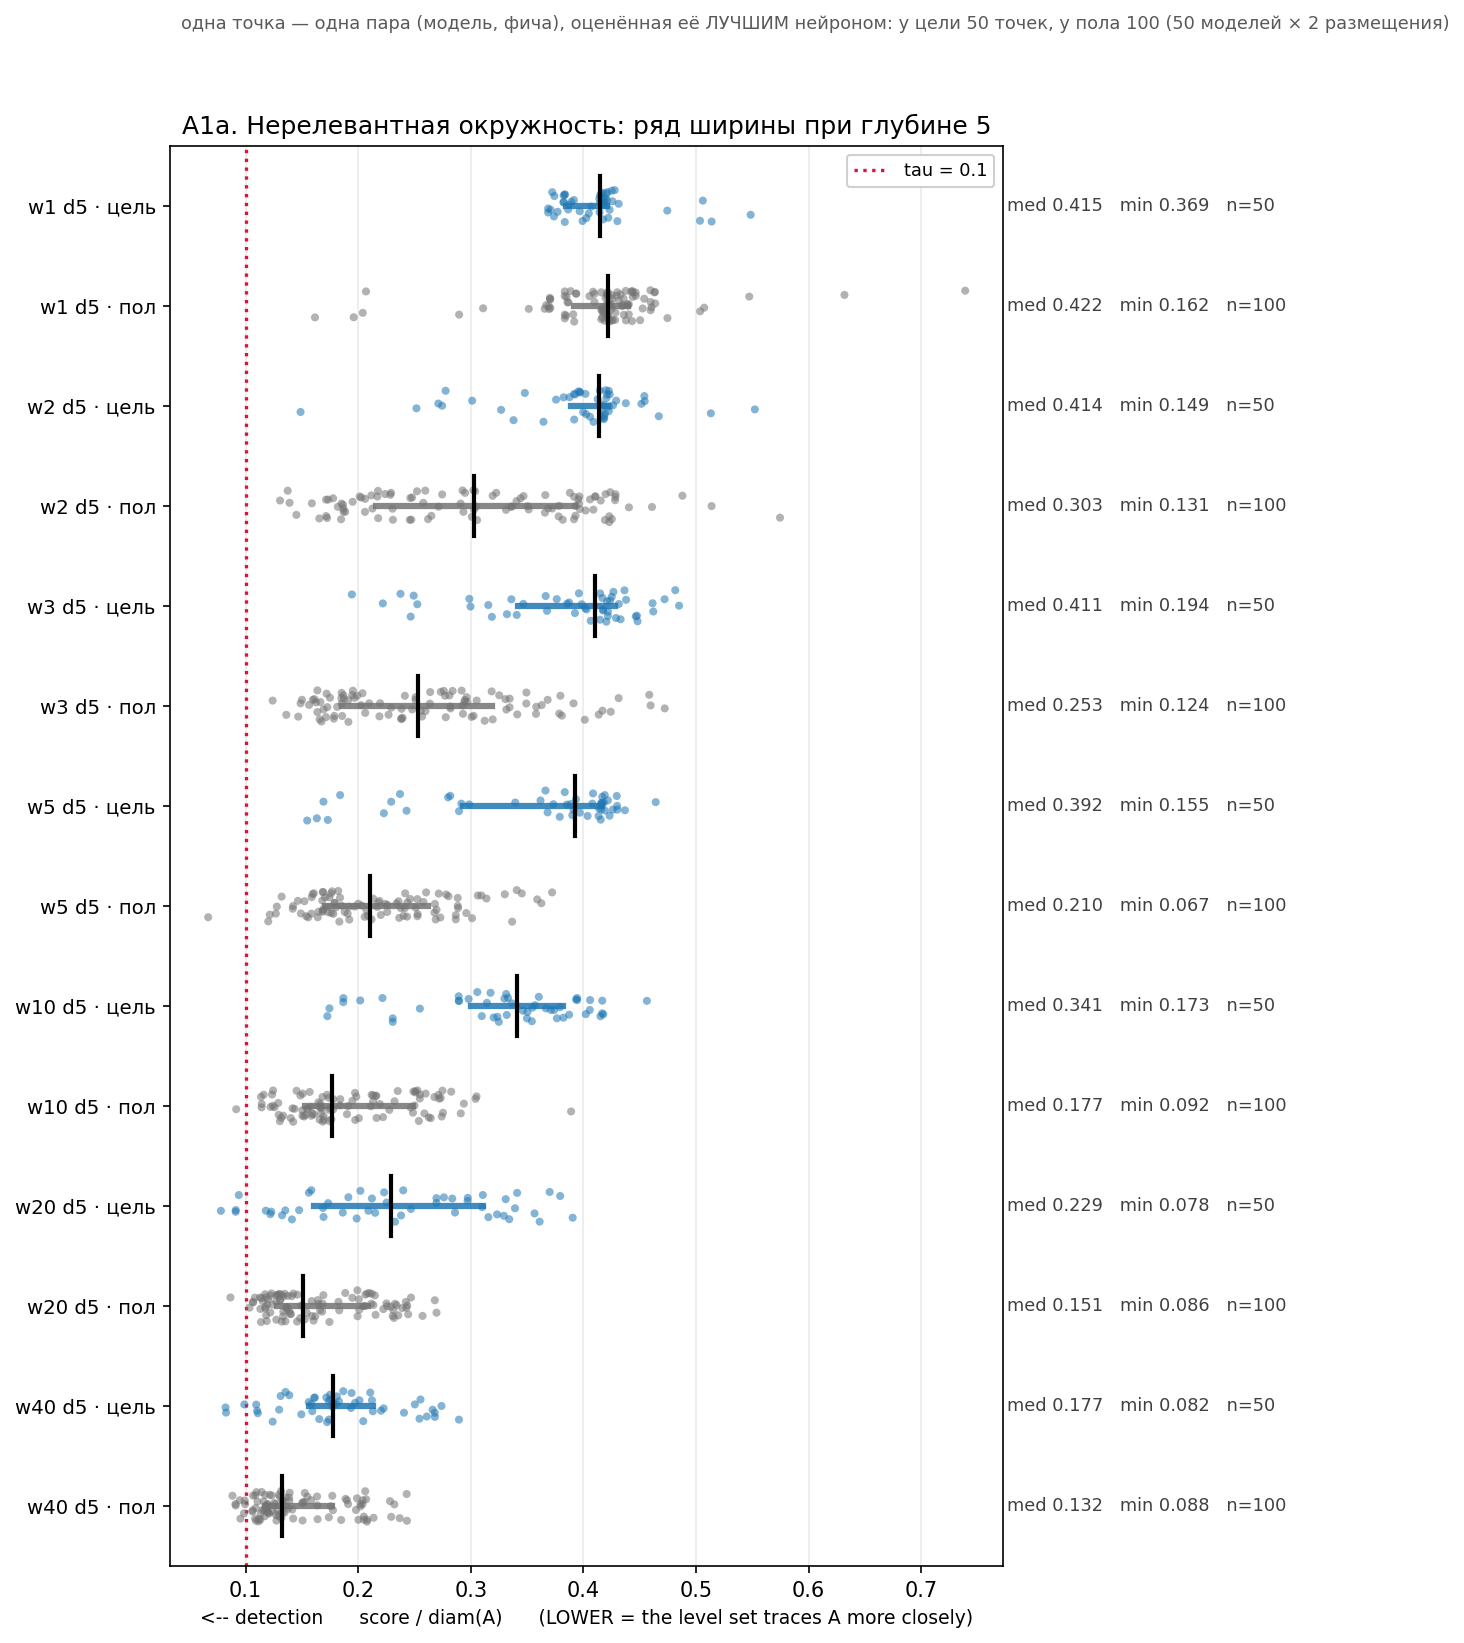

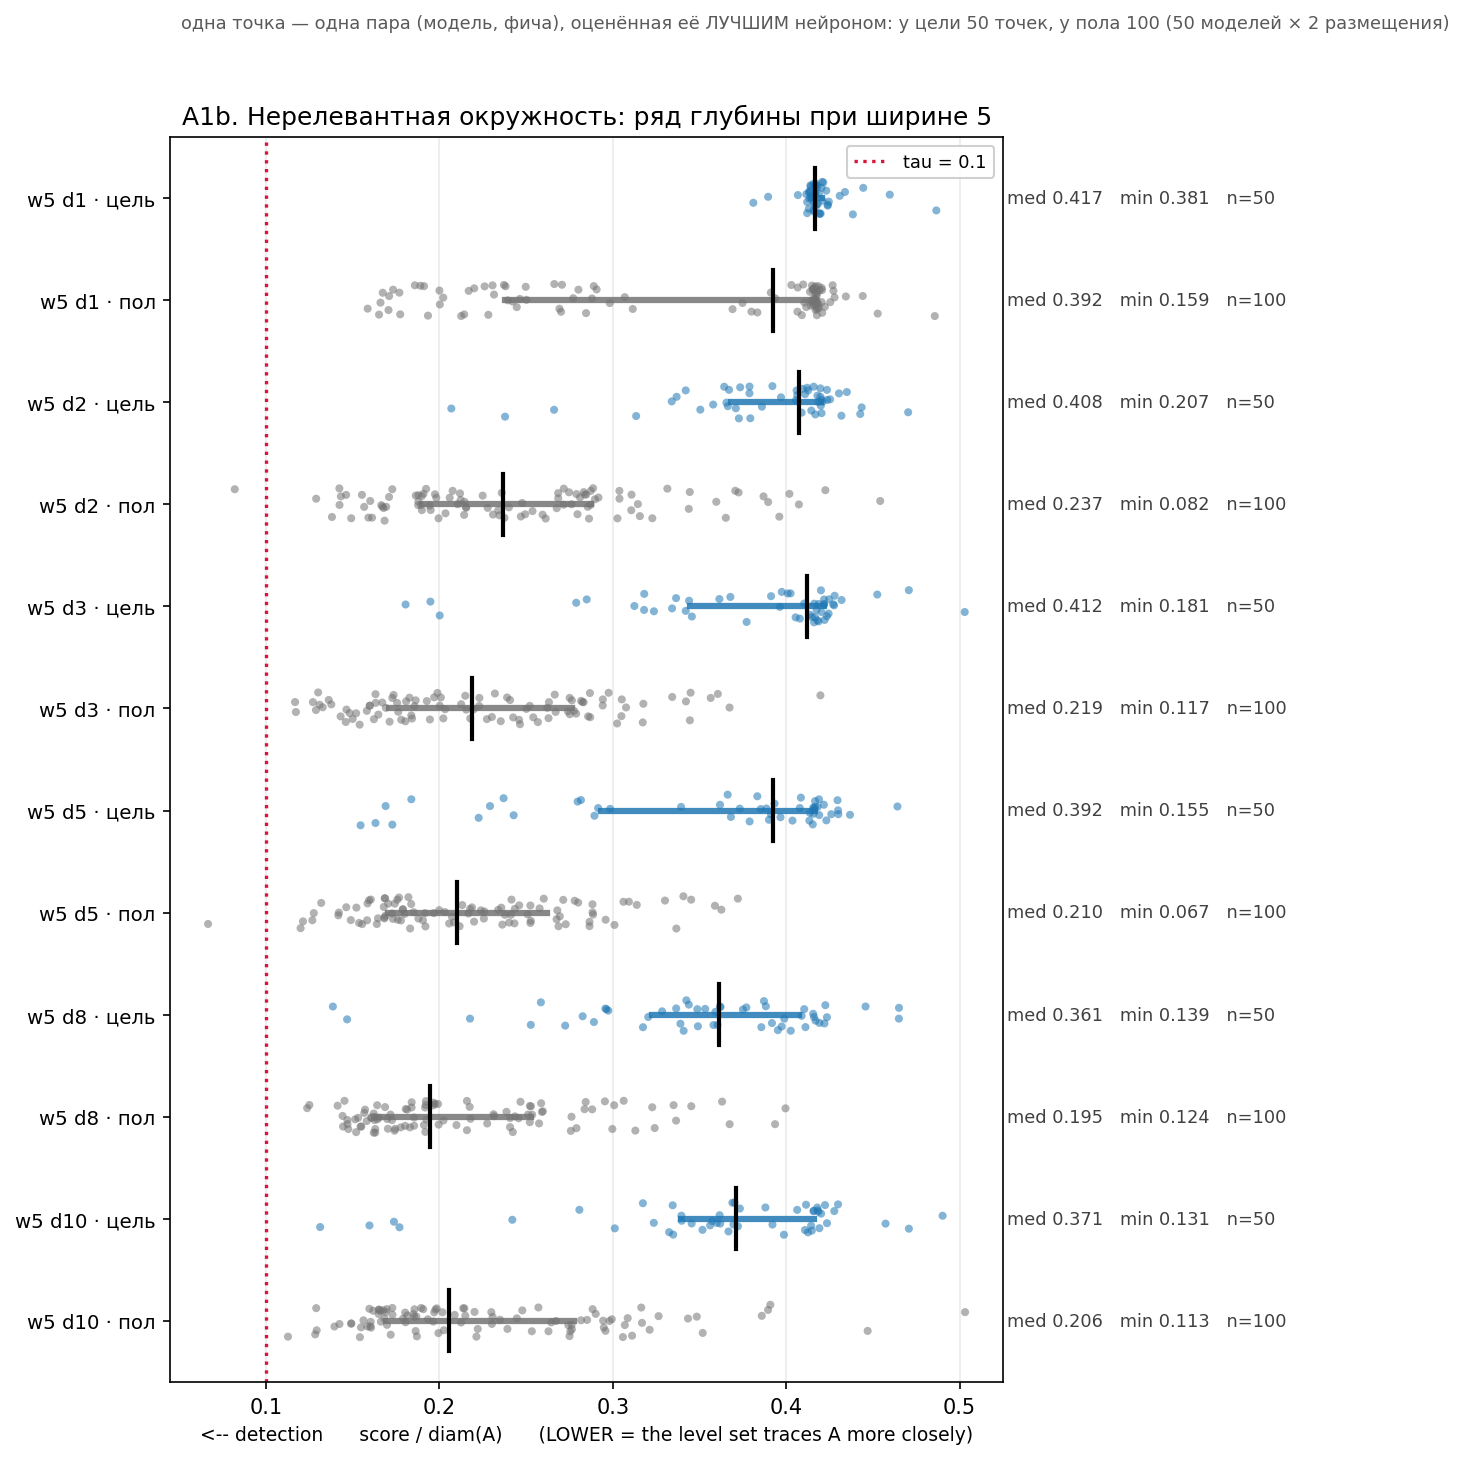

In [14]:
CAPTION = ("одна точка — одна пара (модель, фича), оценённая её ЛУЧШИМ нейроном: "
           "у цели 50 точек, у пола 100 (50 моделей × 2 размещения)")

def strips(dataset, axis, name, title):
    groups = []
    for w, d in axis:
        arch = f"w{w} d{d}"
        groups.append((f"{arch} · цель", {"dataset": dataset, "arch": arch,
                                          "role": "target"}, "tab:blue"))
        groups.append((f"{arch} · пол", {"dataset": dataset, "arch": arch,
                                         "role": "null"}, "0.45"))
    plot_unit_strips(scores, "structural", groups, threshold=aw.TAU,
                     title=title, caption=CAPTION, save_path=FIG / name)
    show(FIG / name)

strips(IRR, W_ROW_I, "A1a_irrelevant_width.png",
       "A1a. Нерелевантная окружность: ряд ширины при глубине 5")
strips(IRR, D_ROW, "A1b_irrelevant_depth.png",
       "A1b. Нерелевантная окружность: ряд глубины при ширине 5")

### Что видно на A1

**Ни одно облако не доходит до порога.** Все синие медианы стоят в 0.23–0.41, то есть в два-четыре
раза выше `τ`. Отдельные точки к порогу всё же подходят: ниже `τ` оказываются **семь** пар
(модель, фича) из восьмисот — четыре в `w20 d5` (0.078–0.094) и три в `w40 d5` (0.082–0.099). Все
семь разбираются отдельно в A4.

**Но подходят к порогу и нулевые размещения, причём чаще.** Ниже `τ` у них **двенадцать** юнитов из
тысячи шестисот, и восемь из двенадцати — в той же `w40 d5`. Более того, **самый низкий скор на всём
нерелевантном датасете принадлежит нулю, а не цели**: 0.0667 у нулевого размещения в `w5 d5` против
0.0780 у лучшего целевого. Пересечения порога здесь — свойство больших ансамблей вообще, а не
свойство окружности.

**Синее лежит правее серого во всех ячейках, кроме одной.** То есть типичная модель описывает
нерелевантную окружность **хуже**, чем то же самое размещение, специально подобранное как оценка
снизу. Исключение — `w1 d5`, ячейка под серой полосой, где ни один нейрон не может дать замкнутую
линию уровня; там сравниваются два способа промахнуться, и порядок между ними случаен.

**И цель, и пол уезжают влево с ростом ширины.** Это надо отметить сразу, потому что дальше все
кривые читаются только парой: одно облако без другого не означает ничего.

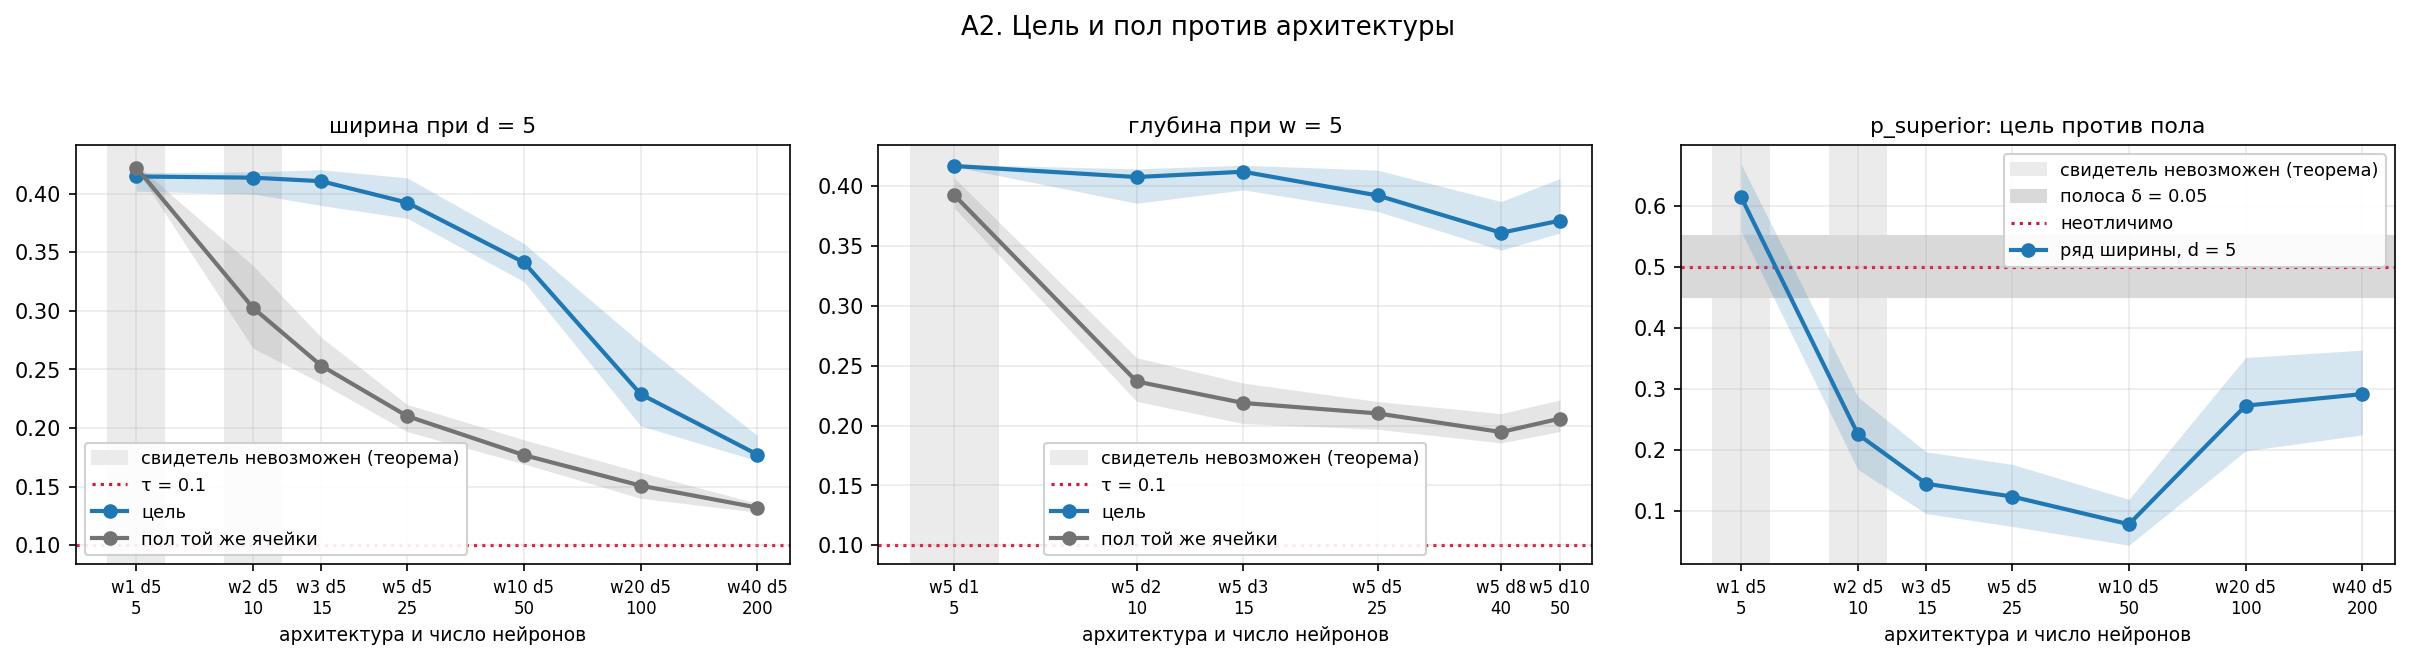

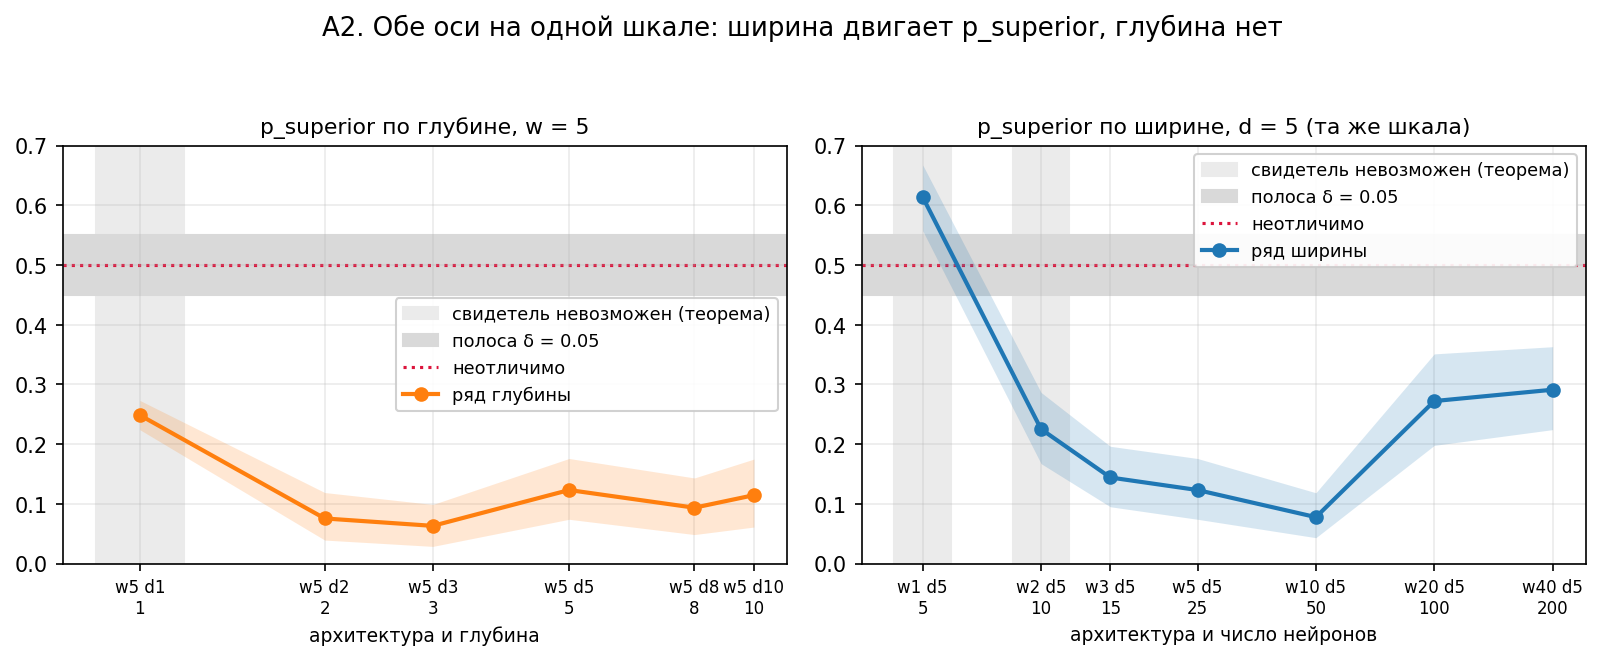

показатели степени, измеренные на этом пуле (двойные логарифмы):
  цель  по ширине: N^(-0.341) [-0.366, -0.302]; локальные наклоны [-0.09, -0.2, -0.58, -0.37]
  пол   по ширине: N^(-0.247) [-0.278, -0.218]; локальные наклоны [-0.37, -0.25, -0.23, -0.19]
irrelevant · p_superior · ширине                     наклон +0.1598 [+0.0881, +0.2303] за декаду, ноль внутри: False
irrelevant · p_superior · глубине                    наклон +0.0601 [-0.0200, +0.1436] за декаду, ноль внутри: True


In [15]:
ap.plot_axis_panels(cells, [
    dict(title="ширина при d = 5", dataset_type=IRR, cells=W_ROW_I,
         series=[("median_best", "цель", "tab:blue"),
                 ("median_best_null", "пол той же ячейки", "0.45")],
         hline=(aw.TAU, "τ = 0.1")),
    dict(title="глубина при w = 5", dataset_type=IRR, cells=D_ROW,
         series=[("median_best", "цель", "tab:blue"),
                 ("median_best_null", "пол той же ячейки", "0.45")],
         hline=(aw.TAU, "τ = 0.1")),
    dict(title="p_superior: цель против пола", dataset_type=IRR, cells=W_ROW_I,
         series=[("p_superior", "ряд ширины, d = 5", "tab:blue")],
         hline=(0.5, "неотличимо"), band=(0.45, 0.55, "полоса δ = 0.05")),
], suptitle="A2. Цель и пол против архитектуры",
   save_path=FIG / "A2a_irrelevant_axis.png")
show(FIG / "A2a_irrelevant_axis.png")

# p_superior по глубине — отдельной панелью, иначе оси не совмещаются.
ap.plot_axis_panels(cells, [
    dict(title="p_superior по глубине, w = 5", dataset_type=IRR, cells=D_ROW,
         x="depth", series=[("p_superior", "ряд глубины", "tab:orange")],
         hline=(0.5, "неотличимо"), band=(0.45, 0.55, "полоса δ = 0.05"),
         ylim=(0.0, 0.7)),
    dict(title="p_superior по ширине, d = 5 (та же шкала)", dataset_type=IRR,
         cells=W_ROW_I, x="n_neurons",
         series=[("p_superior", "ряд ширины", "tab:blue")],
         hline=(0.5, "неотличимо"), band=(0.45, 0.55, "полоса δ = 0.05"),
         ylim=(0.0, 0.7)),
], suptitle="A2. Обе оси на одной шкале: ширина двигает p_superior, глубина нет",
   save_path=FIG / "A2b_irrelevant_p_superior.png")
show(FIG / "A2b_irrelevant_p_superior.png")

print("показатели степени, измеренные на этом пуле (двойные логарифмы):")
for st, name in (("median_best", "цель"), ("median_best_null", "пол")):
    e = aw.loglog_exponent(df, W_ROW_R, IRR, st, n_boot=2000)
    print(f"  {name:5s} по ширине: N^({e['exponent']:+.3f}) "
          f"[{e['exponent_lo']:+.3f}, {e['exponent_hi']:+.3f}]; "
          f"локальные наклоны {[round(v, 2) for v in e['local_slopes']]}")
for st, name in (("p_superior", "p_superior"),):
    for cs, ax_name in ((W_ROW_R, "ширине"), (D_ROW_CAP, "глубине")):
        trend(cs, st, IRR, f"irrelevant · {st} · {ax_name}")

### Что видно на A2

Левые две панели — **ряд ширины при `d = 5`**, правые — **ряд глубины при `w = 5`**; сравнивать их
между собой напрямую нельзя, потому что число нейронов вдоль них растёт по-разному.

**По ширине падают обе кривые — и цель, и пол.** Медиана лучшего у цели идёт 0.41 → 0.18 от `w3` к
`w40`, у пола 0.25 → 0.13. Цель при этом всё время остаётся **выше** пола: отношение по ряду идёт
1.62 → 1.87 → 1.93 → 1.52 → 1.34, то есть сначала растёт и лишь потом сокращается. Никакого
равномерного схождения нет, и одной кривой этот ряд не описывается.

**По глубине пол практически не двигается.** Вдоль ряда глубины он идёт 0.237 → 0.219 → 0.210 →
0.195 → 0.206 при росте числа нейронов с десяти до пятидесяти, тогда как вдоль ряда ширины на том же
диапазоне — с 0.253 до 0.177. Это различие важно, и к нему стоит вернуться, потому что оно
единственное, что здесь объясняет само падение.

> **Почему пол вообще падает, и почему по ширине, а не по глубине.** Пол — это минимум по нейронам
> модели, и естественно ожидать, что чем нейронов больше, тем ниже минимум. Но тогда глубина должна
> была бы работать так же, а она не работает. Данные различают эти две оси прямо: **при одинаковом
> числе нейронов пол ниже у той архитектуры, которая шире.** При `N = 15` пол равен 0.253 у `w3 d5`
> и 0.219 у `w5 d3`; при `N = 50` — 0.177 у `w10 d5` и 0.206 у `w5 d10`; на диагонали равного
> бюджета (`N ≈ 24`) он идёт 0.198 → 0.211 → 0.210 → 0.246 от `w12 d2` к `w3 d8`. Три независимых
> сравнения, и все в одну сторону.
>
> Правдоподобное объяснение: нейроны **одного** слоя — это параллельные попытки, а нейроны
> следующего слоя не попытки, а функции от предыдущих. Глубокий стек — это не больше попыток, а
> более длинная цепочка. Множественность, снижающая пол, считается поэтому шириной слоя, а не общим
> числом нейронов. Это интерпретация; проверено то, что стоит перед ней — асимметрия между осями.
>
> **Практическое следствие для всего эксперимента:** «сколько бы дала одна множественность»
> оценивается не теорией, а **измеренным полом тех же ячеек**. Именно так это делается в B4.

**`p_superior` растёт значимо** — с 0.144 при `w3 d5` до 0.272 при `w20 d5` и **0.291** при
`w40 d5`, наклон +0.160 [+0.088, +0.230] за декаду, ноль вне интервала. Он чувствительнее медианы,
потому что видит всё распределение, а не одну точку. Но абсолютный уровень остаётся низким: при
двухстах нейронах цель по-прежнему **хуже** собственного пола в двух случаях из трёх.

**По глубине нет ничего:** наклон `p_superior` +0.060 [−0.020, +0.144], ноль внутри.

**Ускорения нет — и это видно только потому, что ряд доведён до `w40`.** Локальные наклоны цели по
отрезкам идут **−0.09, −0.20, −0.58, −0.37**: на четвёртом шаге падение не ускорилось, а
замедлилось. Если бы ряд обрывался на `w20`, первые три числа читались бы как разгоняющееся падение,
из которого следовало бы пересечение `τ` где-то за пределами пула; четвёртая точка это прочтение
снимает. **Экстраполяции к детекции здесь нет.**

---

### A2b. Одно замечание про пол, и дальше он используется как есть

Пол здесь по построению низкий: из пяти размещений эксперимента 1 оставлены два, а самое трудное
исключено guideline'ом. Это **сознательный выбор**: набор нуль-фичей подбирается вручную, из
соображений покрытия задачи, и берутся те размещения, что дают низкий скор, — тогда пол работает как
оценка снизу и вердикт от него только строже.

Ниже печатается, чем место мягкого нуля отличается от места цели — три величины, которые считаются
вместе со скором и лежат в тех же строках таблицы. Это **справка, а не предмет изучения**: вопрос
«как скор зависит от того, насколько поле в этом месте живое» — отдельный эксперимент, которого в
плане нет, и здесь он не ставится.

In [16]:
diag = aw.placement_diagnostics(df, IRR, 20, 5)
diag.to_csv(AGG / "placement_diagnostics.csv", index=False)
print("simple_irrelevant, w20 d5 — медианы по 5 000 нейронов на каждую фичу:")
display(diag.rename(columns={
    "feature_name": "фича", "role": "роль", "grad_norm": "|∇f| на фиче",
    "value_std": "разброс f", "value_abs_mean": "|f|", "median_score": "медиана скора",
    "n_rows": "строк"}).round(4))

d2 = aw.placement_diagnostics(df, REL, 20, 5)
print("\nдля сравнения, simple_relevant w20 d5:")
display(d2.rename(columns={
    "feature_name": "фича", "role": "роль", "grad_norm": "|∇f| на фиче",
    "value_std": "разброс f", "value_abs_mean": "|f|", "median_score": "медиана скора",
    "n_rows": "строк"}).round(4))

simple_irrelevant, w20 d5 — медианы по 5 000 нейронов на каждую фичу:


,фича,роль,|∇f| на фиче,разброс f,|f|,медиана скора,строк
0,null_far_right,null,0.0223,0.0160,0.8539,0.2529,5000
1,null_above_target,null,0.1131,0.1113,0.6361,0.3463,5000
2,irrelevant,target,0.1686,0.1505,0.6030,0.5518,5000



для сравнения, simple_relevant w20 d5:


,фича,роль,|∇f| на фиче,разброс f,|f|,медиана скора,строк
0,relevant,target,0.4497,0.1538,0.3919,0.1824,5000
1,null_far_right,null,0.1026,0.0819,0.6779,0.2803,5000
2,null_above_target,null,0.1034,0.0828,0.6790,0.3693,5000


### Что видно на A2b

**Мягкий нуль сидит в насыщенном хвосте поля.** На `simple_irrelevant` при `w20 d5`:

| фича | \|∇f\| на фиче | \|f\| | медиана скора |
|---|---|---|---|
| `irrelevant` (цель) | 0.169 | 0.60 | 0.552 |
| `null_above_target` | 0.113 | 0.64 | 0.346 |
| `null_far_right` | **0.022** | **0.85** | **0.253** |

У `far_right` градиент в 7.6 раза меньше, чем на цели, а модуль значения близок к единице — `tanh`
там насыщен и поле почти плоское. Это и есть механизм, которым получается низкий скор, и заодно
причина, по которой такой нуль даёт именно **нижнюю** оценку. Ровно поэтому он и выбран.

**Что отсюда следует и чего не следует.**

* **Следует:** пол 0.15–0.25 — оценка снизу на скор нерелевантной фичи в этой задаче, и цель
  (0.18–0.41) лежит выше неё. Ровно это и надо говорить.
* **Не следует:** что распределения скора на нуль-фичах и на нерелевантных фичах различаются. Мы
  сами оставили те нули, которые дают низкий скор.
* **Не следует:** что сеть «подавляет» нерелевантную окружность.

**Вердикт пункта A от этого не зависит:** он держится на пороге, а не на порядке. Ни цель, ни пол не
переходят `τ` систематически, и по цели это 0 из 16 050 строк в четырнадцати ячейках из шестнадцати.

Дальше пол используется как есть. Как выбирать нуль-фичи вообще — какое их число нужно, как мерить
их разнообразие и насколько занижена получаемая оценка — вопрос отдельного эксперимента, которого в
плане нет; здесь принят ручной подбор из соображений покрытия задачи, и этого достаточно.

---

### A3. Форма распределения, а не только сводка

Медиана — одно число; она не говорит, есть ли у распределения хвост, дотягивающийся до порога.
Поэтому здесь по каждой ячейке ряда ширины рисуется полное распределение скора **по всем нейронам**
(бледная гистограмма, нормированная на размер популяции) и **медиана лучшего на юнит** (жирная
вертикаль) — единственная из двух, на которую можно опирать вердикт.

Семь панелей подряд, по одной на ячейку: они про одно и то же, а вопрос именно в том, как форма
меняется вдоль оси. Первые две — теоремные, они здесь как эталон «никакой структуры».

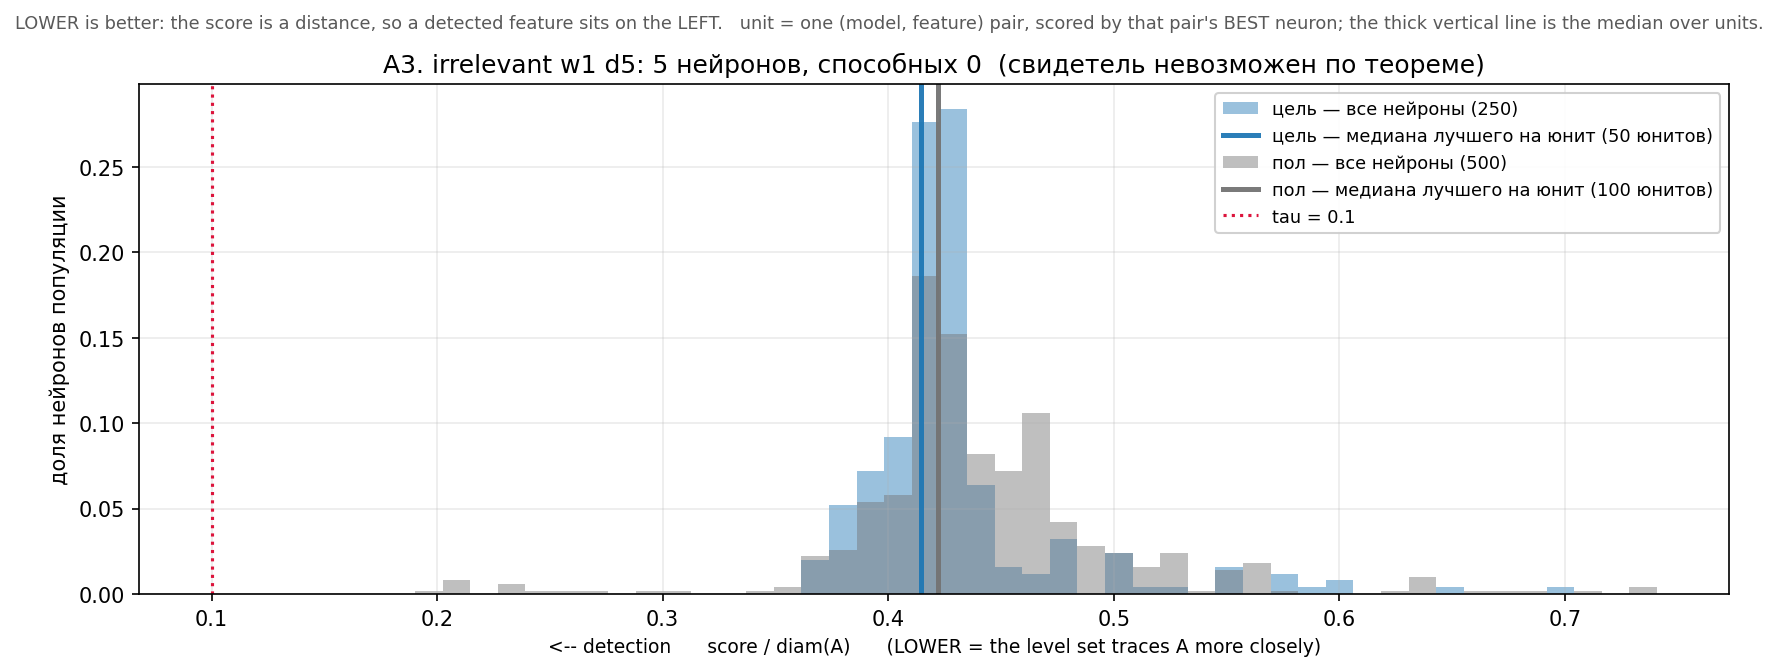

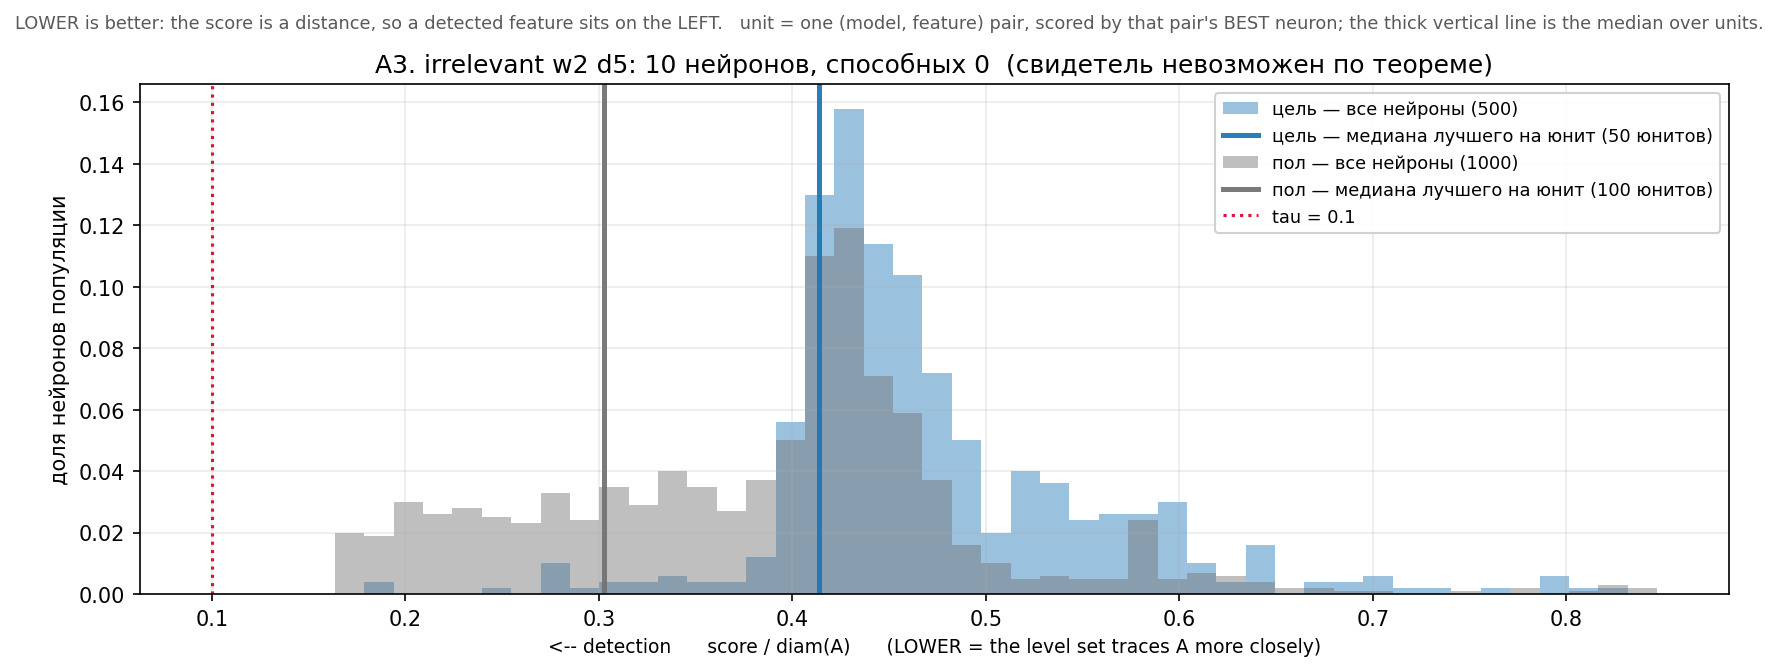

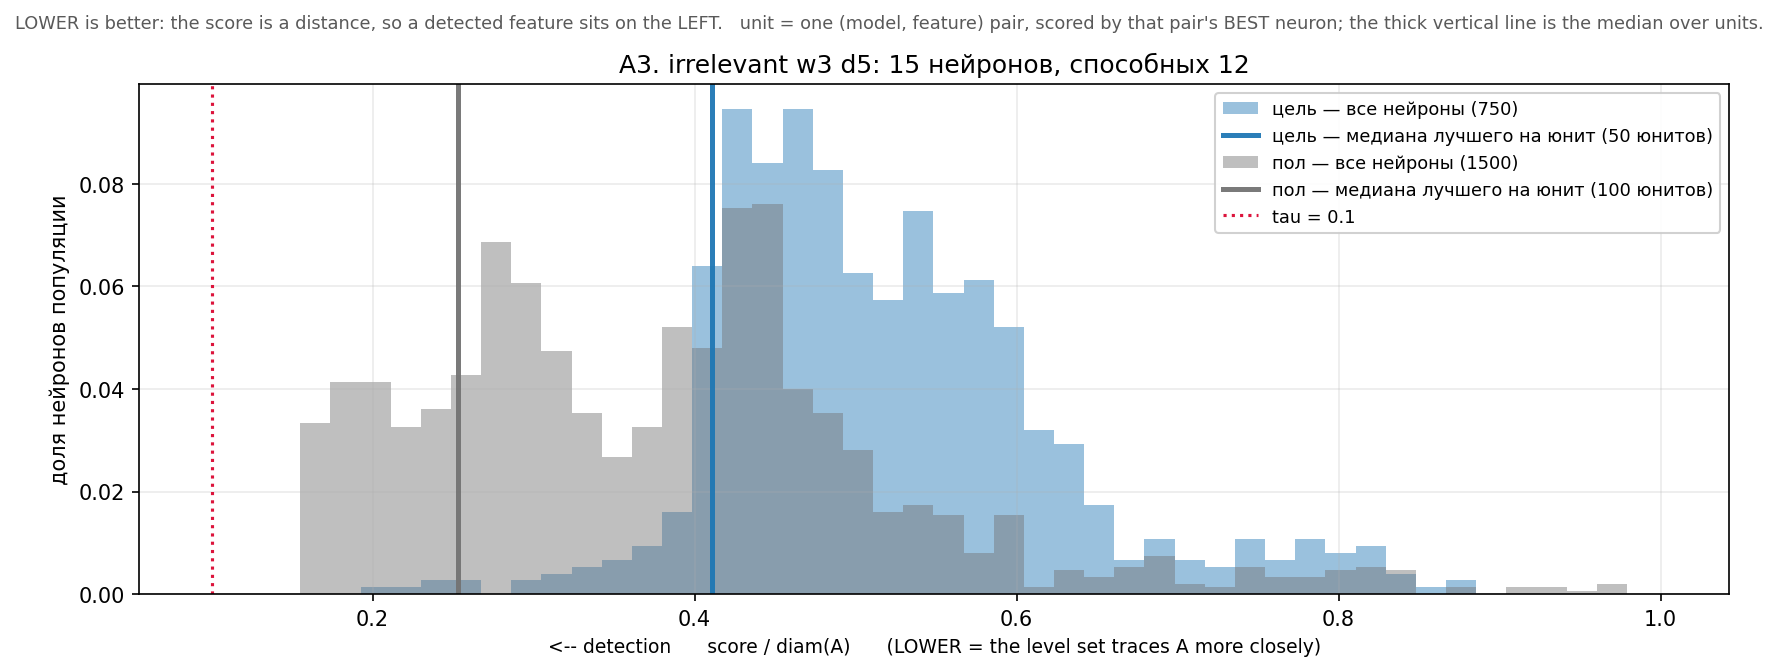

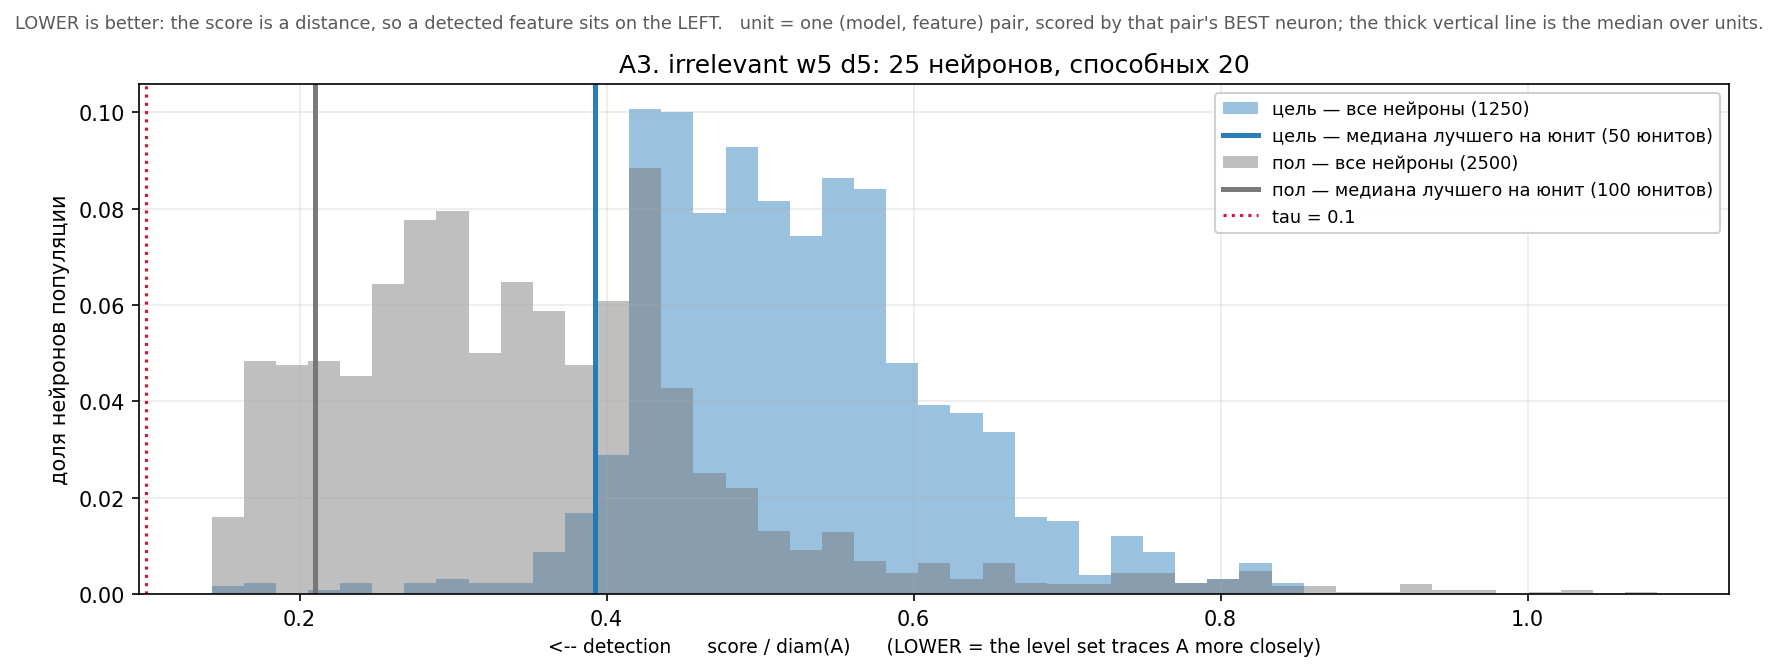

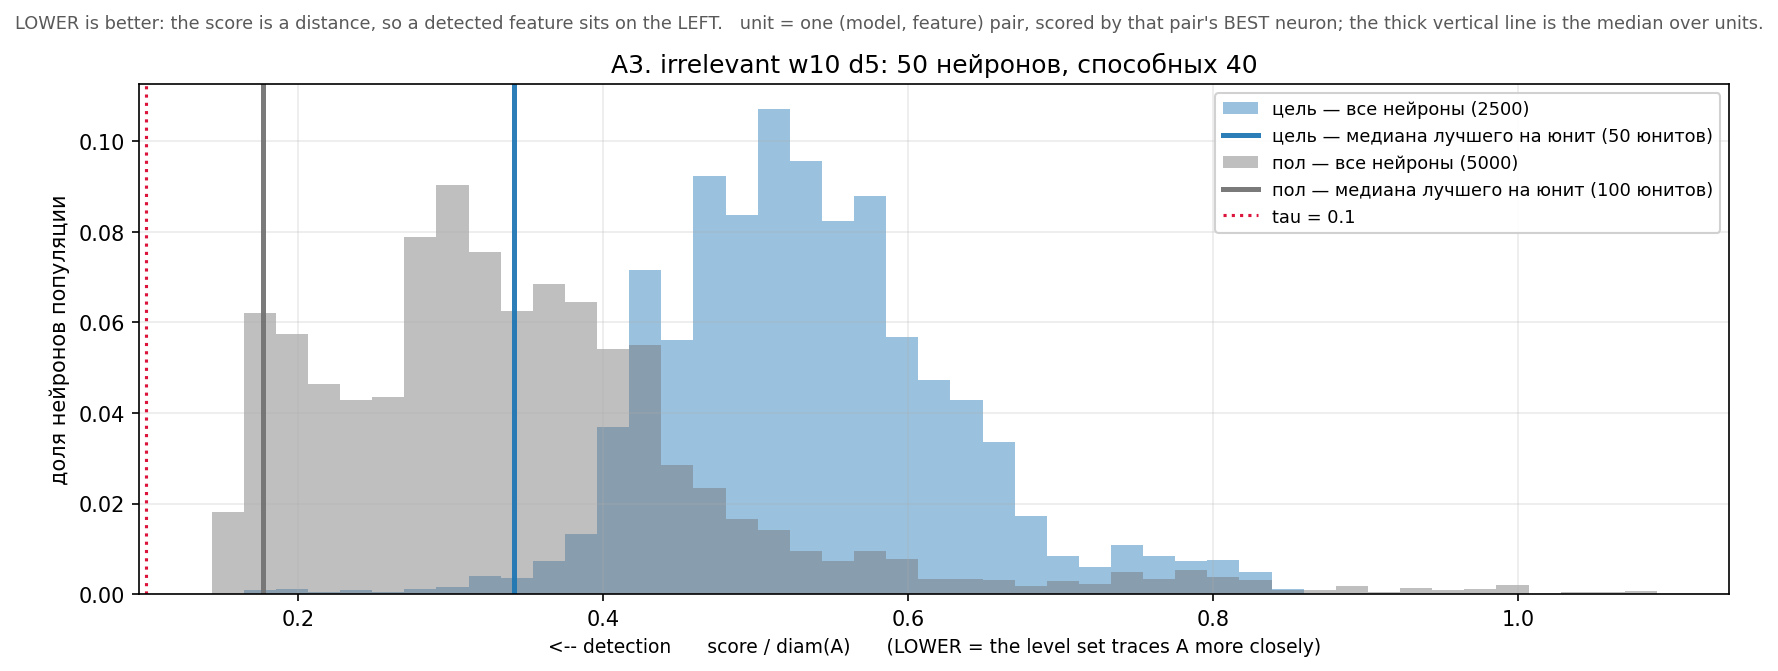

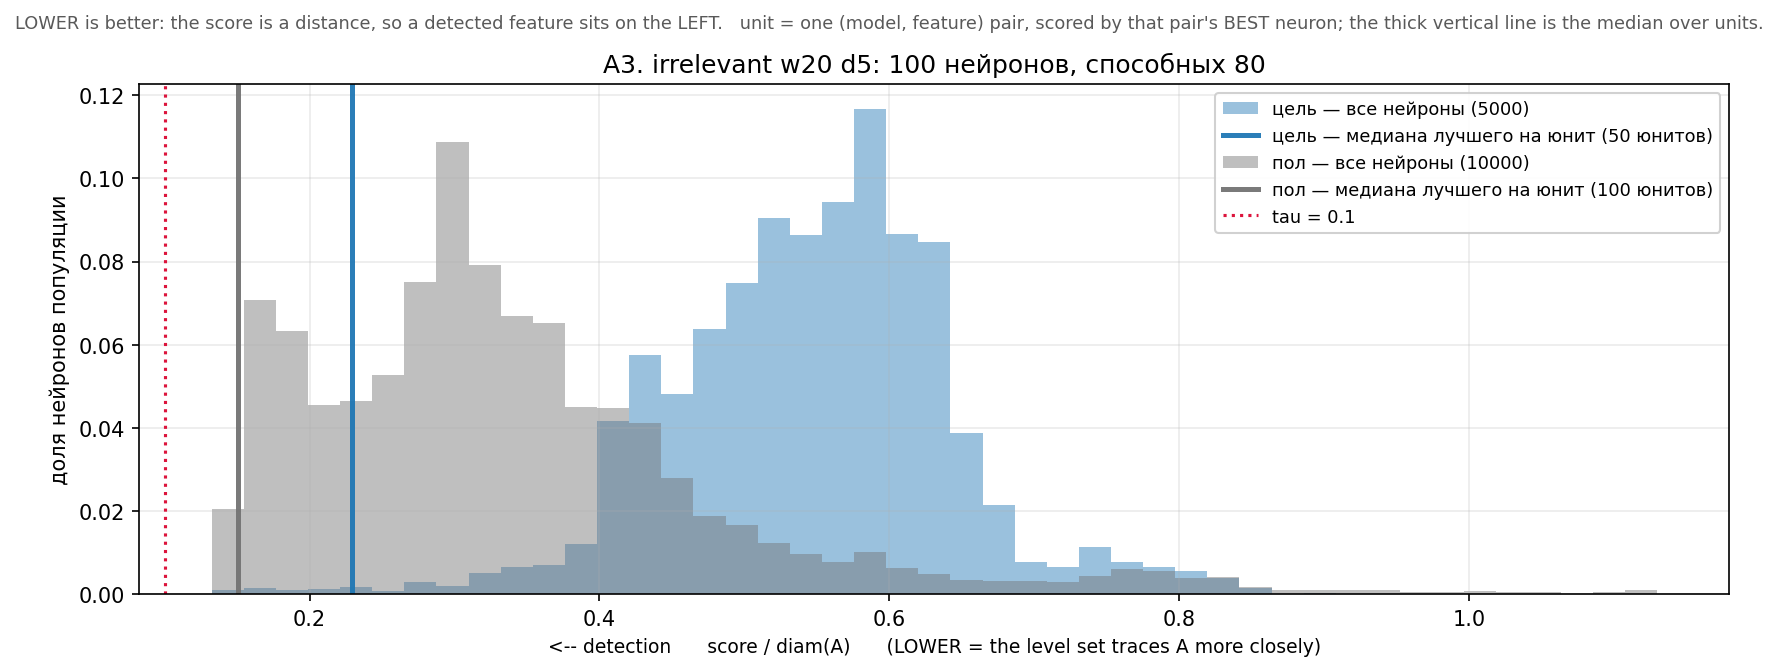

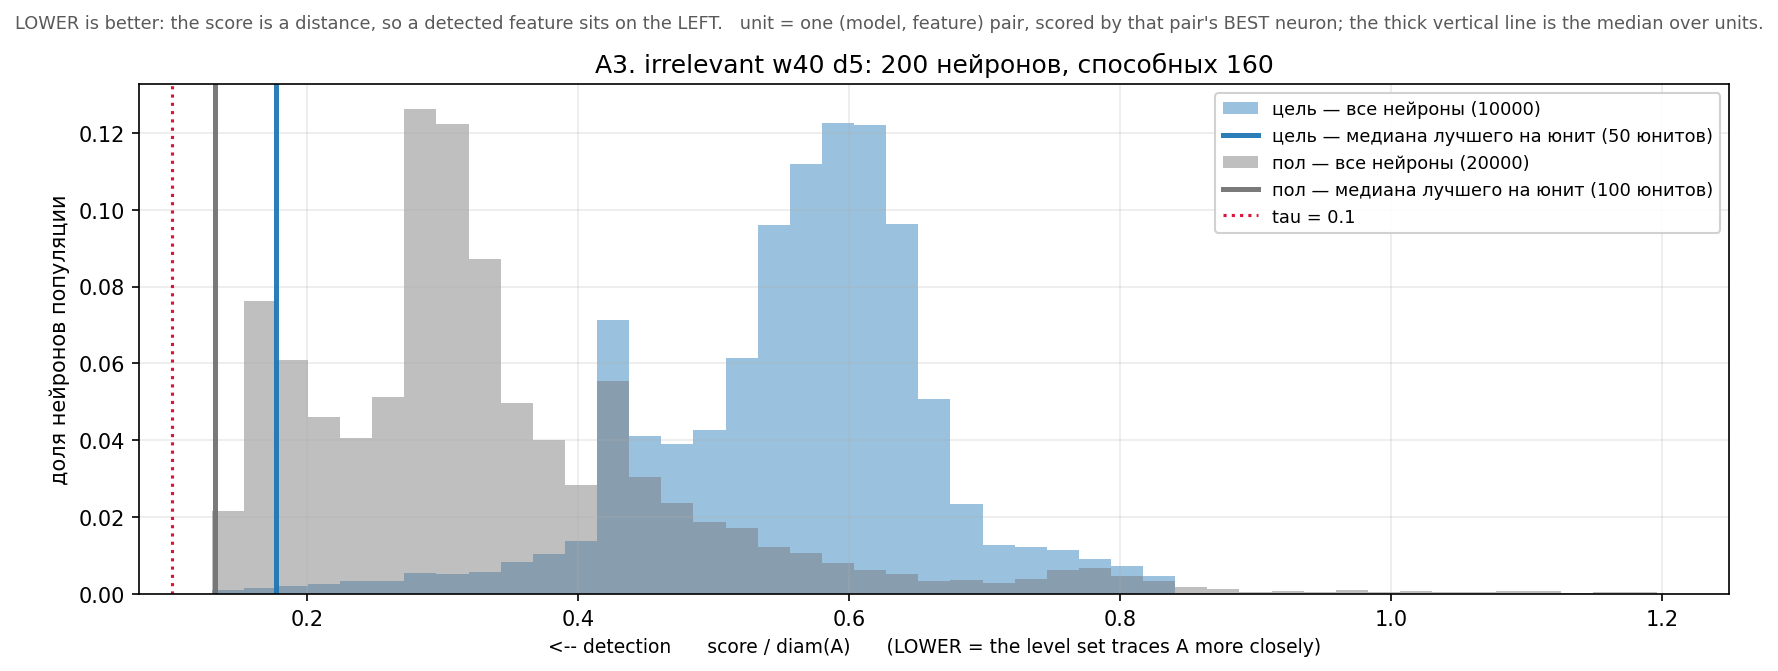

In [17]:
for w, d in W_ROW_I:
    arch = f"w{w} d{d}"
    name = f"A3_irrelevant_{arch.replace(' ', '')}.png"
    n_cap = int(cells[(cells.dataset_type == IRR) & (cells.arch == arch)].n_capable.iat[0])
    mark = "" if n_cap else "  (свидетель невозможен по теореме)"
    plot_populations(scores, "structural", [
        ("цель", {"dataset": IRR, "arch": arch, "role": "target"}, "tab:blue"),
        ("пол", {"dataset": IRR, "arch": arch, "role": "null"}, "0.45")],
        threshold=aw.TAU, save_path=FIG / name,
        title=f"A3. irrelevant {arch}: {w * d} нейронов, способных {n_cap}{mark}")
    show(FIG / name)

### Что видно на A3

**Разделение распределений держится на всех ширинах.** При `w1 d5` синее и серое почти совпадают —
ожидаемо, там ни одна из популяций не может ничего выделить. Начиная с `w3` синее уезжает вправо от
серого и остаётся там: типичный нейрон описывает нерелевантную окружность **хуже**, чем то же самое
размещение, специально подобранное как оценка снизу для нуль-фич. Это сравнение с нижней границей, а
не с произвольной альтернативой.

**Хвост появляется у двух самых широких ячеек.** У `w20 d5` левый край синего распределения впервые
дотягивается до области порога, у `w40 d5` то же самое. Это те **семь** нейронов — четыре и три, — и
единственный способ понять, что они собой представляют, это посмотреть на них.

---

### A4. Что именно сматчил критерий у этих семи

Число не может отличить замкнутую линию уровня, обводящую окружность, от куска кривой, случайно
легшего рядом. Поэтому здесь рисуется то, что критерий реально матчил —
`return_best_component_points`, — поверх поля нейрона, с фичей `A` сверху.

Компонента нарисована **широко и снизу**, фича — тонко и сверху: совпадение читается как зелёный
ореол вокруг чёрной кривой, а расхождение — как чистый зелёный или чистый чёрный.

К каждой панели считается ещё одна величина: **персистентность `H_1` самой компоненты**, нормированная
на `diam(A)`. Она отвечает на вопрос «а дырка-то есть, и какого она размера» независимо от того,
насколько компонента близка к `A`.

Нижние панели — контроли: **лучший нулевой нейрон всего нерелевантного датасета** (он набирает
меньше, чем любой целевой нейрон где бы то ни было), типичный нейрон `w20 d5` и, для контраста,
свидетели релевантной окружности при том же самом `τ`.

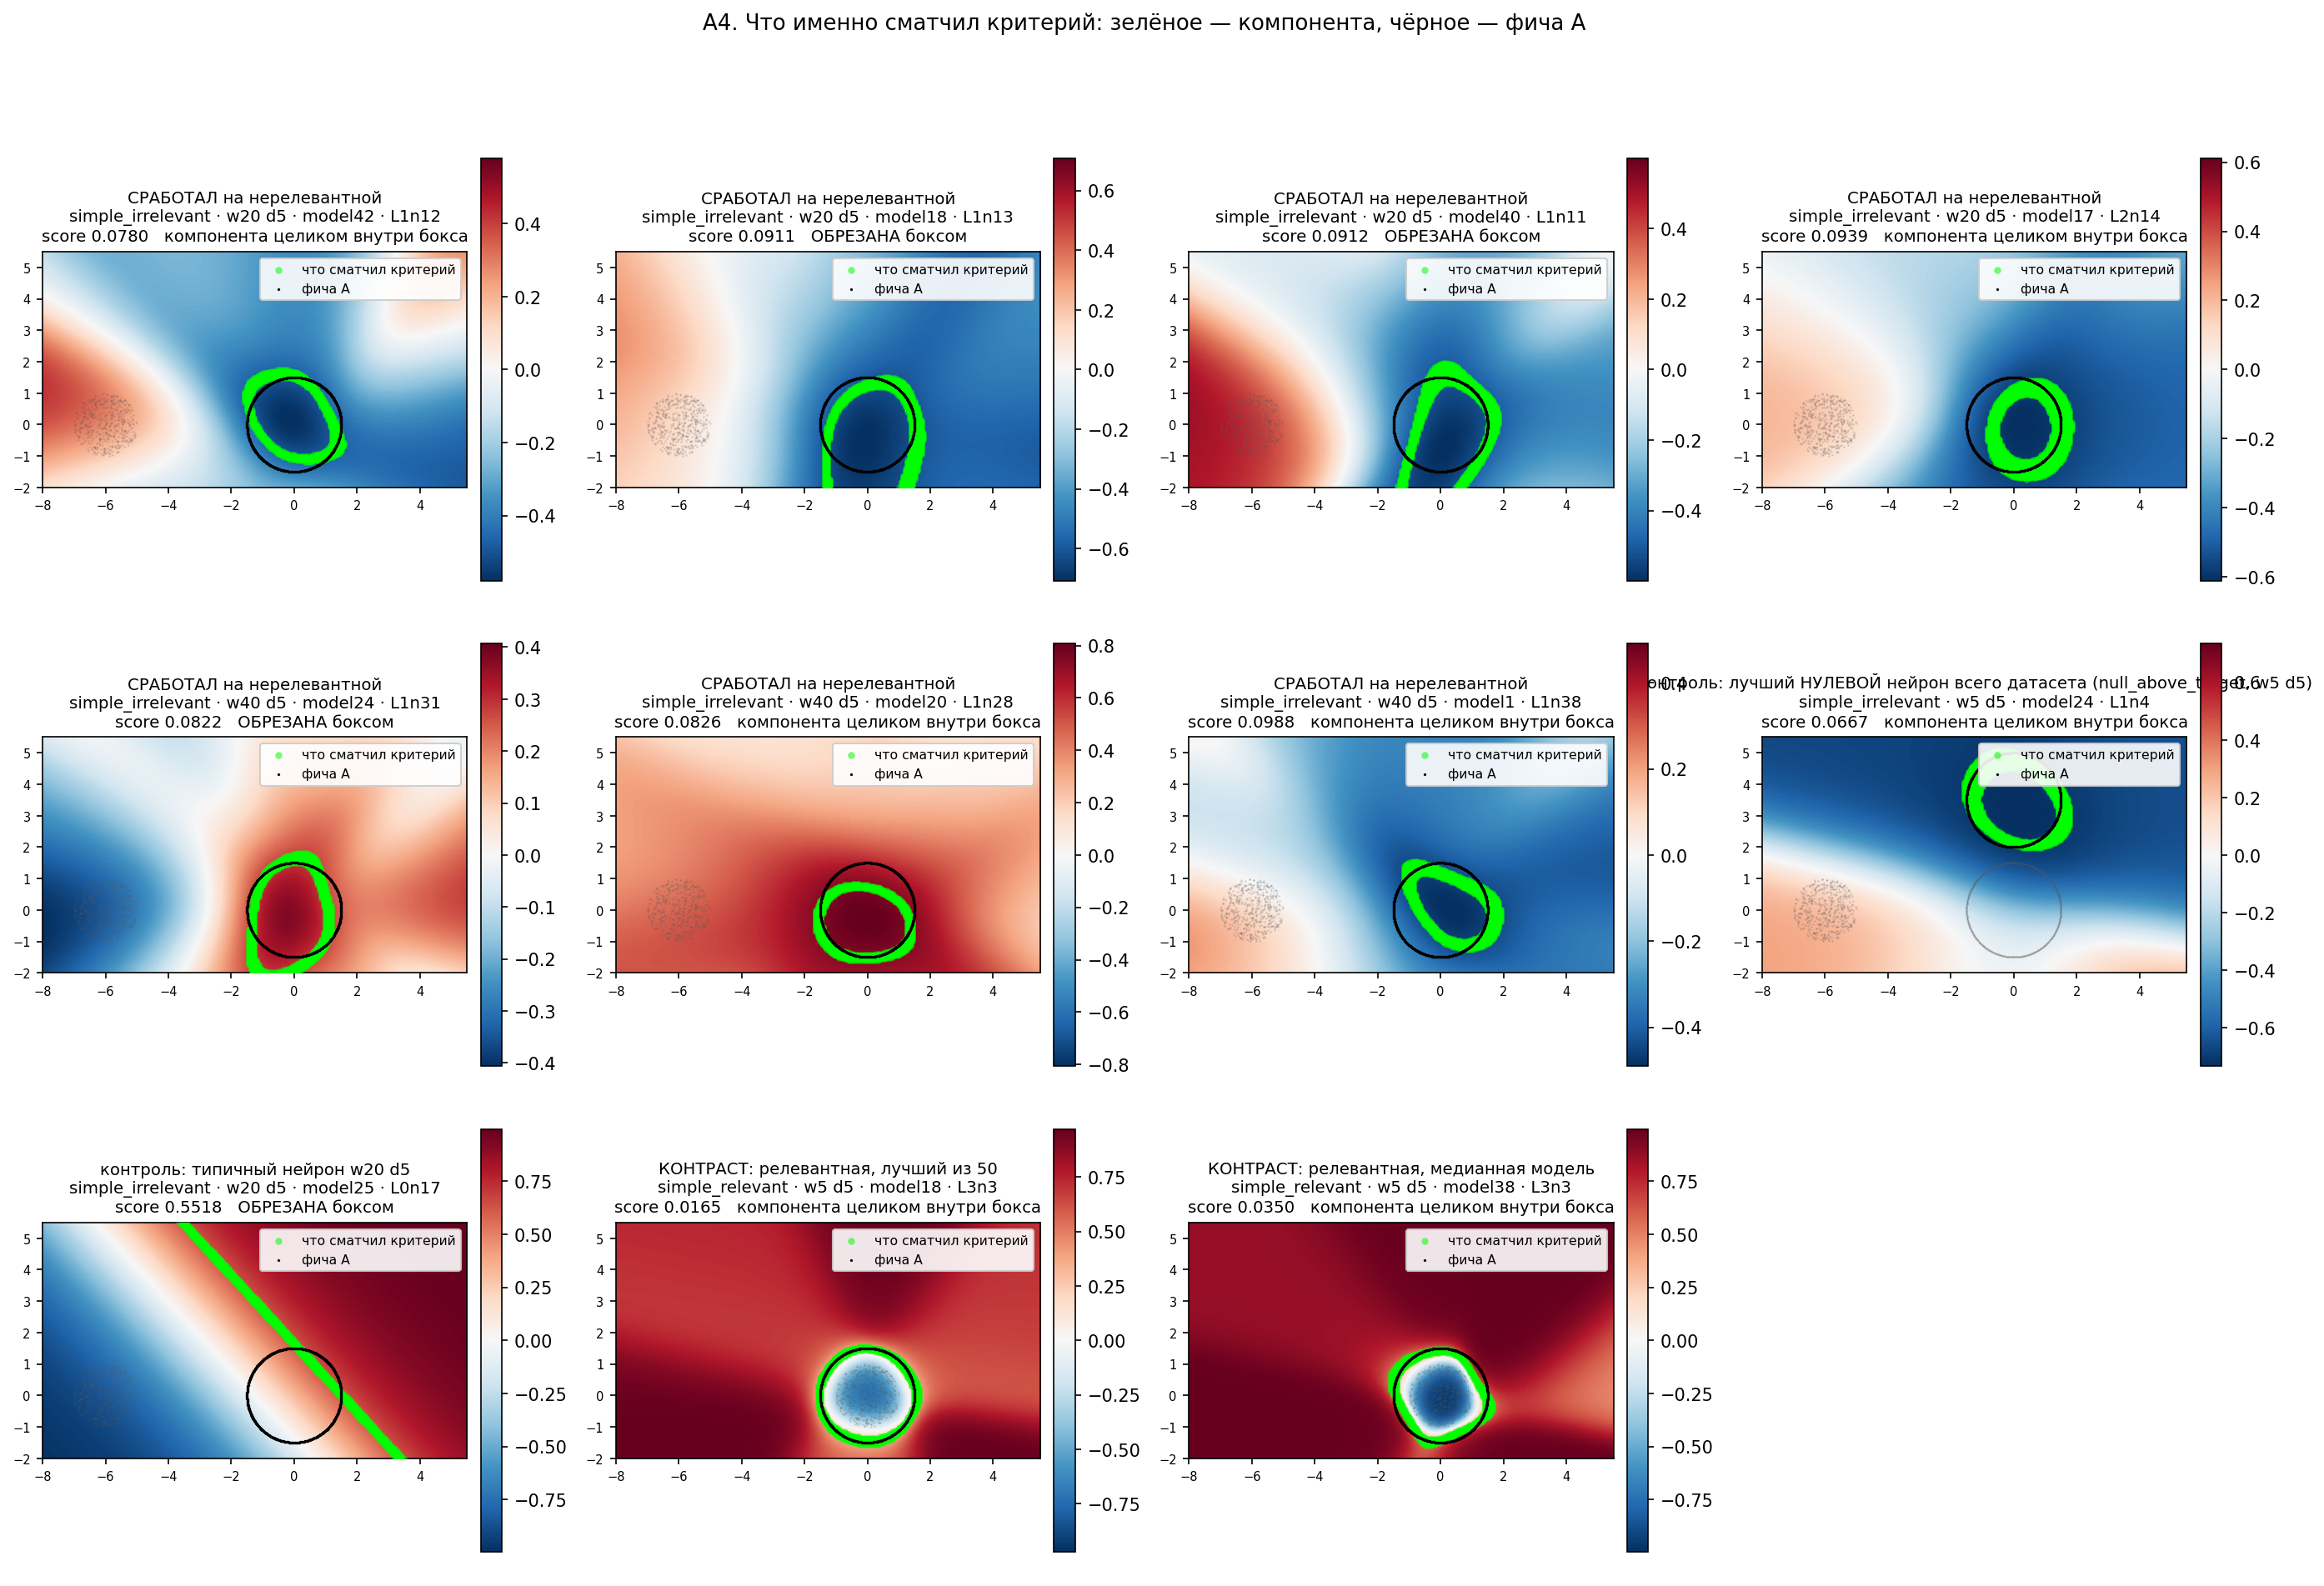

In [18]:
A_irr = aw.feature_points_for(IRR, "irrelevant")
A_rel = aw.feature_points_for(REL, "relevant")

irr = df[df.dataset_type == IRR]
fired = irr[(irr.feature_role == "target") & irr.witness].sort_values(["hidden_dim", "score"])
fired.to_csv(AGG / "irrelevant_witnesses.csv", index=False)
cell20 = irr[(irr.hidden_dim == 20) & (irr.n_layers == 5)]

# Компонента, упирающаяся в край бокса, обрезана: и её скор, и любая её
# топология — про бокс, а не про сеть. Это надо видеть на подписи.
(bx0, bx1), (by0, by1) = ES.bounds
STEP = max(bx1 - bx0, by1 - by0) / (ES.resolution - 1)

def clipped(component):
    K = np.asarray(component)
    return int((((np.abs(K[:, 0] - bx0) < 1.5 * STEP) | (np.abs(K[:, 0] - bx1) < 1.5 * STEP)
                 | (np.abs(K[:, 1] - by0) < 1.5 * STEP) | (np.abs(K[:, 1] - by1) < 1.5 * STEP))).sum())

def panel(row, feature_points, tag, dataset):
    it = aw.neuron_field_and_component(row.model_path, int(row.layer_id),
                                       int(row.coord_id), feature_points, ES)
    n_edge = clipped(it["component_points"])
    arch = f"w{int(row.hidden_dim)} d{int(row.n_layers)}"
    model = Path(row.model_path).name.split("_")[-1]
    it["label"] = (f"{tag}\n{dataset} · {arch} · {model} · L{row.layer_id}n{row.coord_id}\n"
                   f"score {it['score']:.4f}   "
                   f"{'ОБРЕЗАНА боксом' if n_edge else 'компонента целиком внутри бокса'}")
    it["data_points"] = aw.dataset_points(dataset)
    return it

items = [panel(r, A_irr, "СРАБОТАЛ на нерелевантной", IRR) for r in fired.itertuples()]

# Контроль сильнее, чем прежний «лучший нуль этой ячейки»: лучший нулевой
# нейрон ВСЕГО нерелевантного датасета набирает меньше, чем любой целевой.
best_null = irr[irr.feature_role == "null"].nsmallest(1, "score").iloc[0]
items.append(panel(best_null, aw.feature_points_for(IRR, best_null.feature_name, ES),
                   f"контроль: лучший НУЛЕВОЙ нейрон всего датасета "
                   f"({best_null.feature_name}, w{int(best_null.hidden_dim)} "
                   f"d{int(best_null.n_layers)})", IRR))

target20 = cell20[cell20.feature_role == "target"].sort_values("score")
items.append(panel(target20.iloc[len(target20) // 2],
                   A_irr, "контроль: типичный нейрон w20 d5", IRR))

ref = df[(df.dataset_type == REL) & (df.model_name == "tanh_w5_d5_mass-train")
         & (df.feature_role == "target")]
per_model = ref.groupby("model_path").score.min().sort_values()
median_model = per_model.index[len(per_model) // 2]
items.append(panel(ref.nsmallest(1, "score").iloc[0],
                   A_rel, "КОНТРАСТ: релевантная, лучший из 50", REL))
items.append(panel(ref[ref.model_path == median_model].nsmallest(1, "score").iloc[0],
                   A_rel, "КОНТРАСТ: релевантная, медианная модель", REL))

ap.plot_neuron_fields(items, ncols=4, save_path=FIG / "A4_irrelevant_fired_fields.png",
    title="A4. Что именно сматчил критерий: зелёное — компонента, чёрное — фича A")
show(FIG / "A4_irrelevant_fired_fields.png")

### Что видно на A4

**Три компоненты из семи обрезаны боксом.** У `w20 d5` это `L1n13` (0.0911) и `L1n11` (0.0912), у
`w40 d5` — `L1n31` (0.0822): часть точек компоненты лежит на краю окна оценки, линия уровня уходит за
бокс и внутри него видна дугой. Для таких компонент **и скор, и любая их геометрия — про бокс, а не
про сеть**: критерий сравнивает `A` с усечённым множеством.

**Оставшиеся четыре выглядят как честные срабатывания.** `L1n12` (0.0780) и `L2n14` (0.0939) при
`w20 d5`, `L1n28` (0.0826) и `L1n38` (0.0988) при `w40 d5` — замкнутые линии уровня, обводящие
окружность со смещением, но обводящие. По виду это не артефакт: критерий сработал на том, на что он и
должен срабатывать.

Отсюда точная формулировка результата: **на двух самых широких архитектурах четыре модели из ста дают
правдоподобного свидетеля нерелевантной окружности**, и ещё три срабатывания недостоверны из-за
обрезки. Достаточно ли этого, чтобы говорить о ставке, решается в A6 — заранее объявленным правилом,
а не глазом.

**И тут же контроль, который отвечает почти сразу.** Лучший НУЛЕВОЙ нейрон всего нерелевантного
датасета набирает **0.0667** — меньше любого из семи, — и его компонента целиком внутри бокса и
честно обводит своё размещение. То есть **самое убедительное срабатывание на этом датасете
принадлежит фиче, о которой задача не упоминала вовсе.** Это тот же диапазон значений и то же
качество обводки, а не что-то худшее.

**Контраст с релевантной окружностью при том же `τ`** качественный, а не количественный: там
компонента — плотное замкнутое кольцо, облегающее `A`, со скором 0.017–0.035.

**Почему 0.09 вообще проходит порог.** `geometry.max_chamfer_distance` — это максимум по двум
направлениям от **средних** расстояний до ближайшего, а не от максимальных. Усреднение делает
критерий устойчивым к дыркам сетки, но у самого порога означает, что 0.09 — область неплотных
обводок.

---

### A5. Второй критерий, независимый от первого

Гомологический критерий спрашивает другое: есть ли у ПОЛЯ петля нужной размерности, без ссылки на
то, где стоит `A`. Именно поэтому его совпадение со структурным вердиктом — свидетельство, а не
бухгалтерия.

**Смотрим на скор, а не на долю.** Доля сработавших на `simple_irrelevant` — это 52 нейрона из
31 050, и сравнивать доли с четырьмя знаками бессмысленно. Информативная величина — сам
`persistence_margin`, взятый как **лучший на модель** (у него больше = лучше, в отличие от
структурного скора). `NaN` означает «бара нужной размерности не нашлось вовсе» и в максимум не
входит; сколько таких, печатается отдельно.

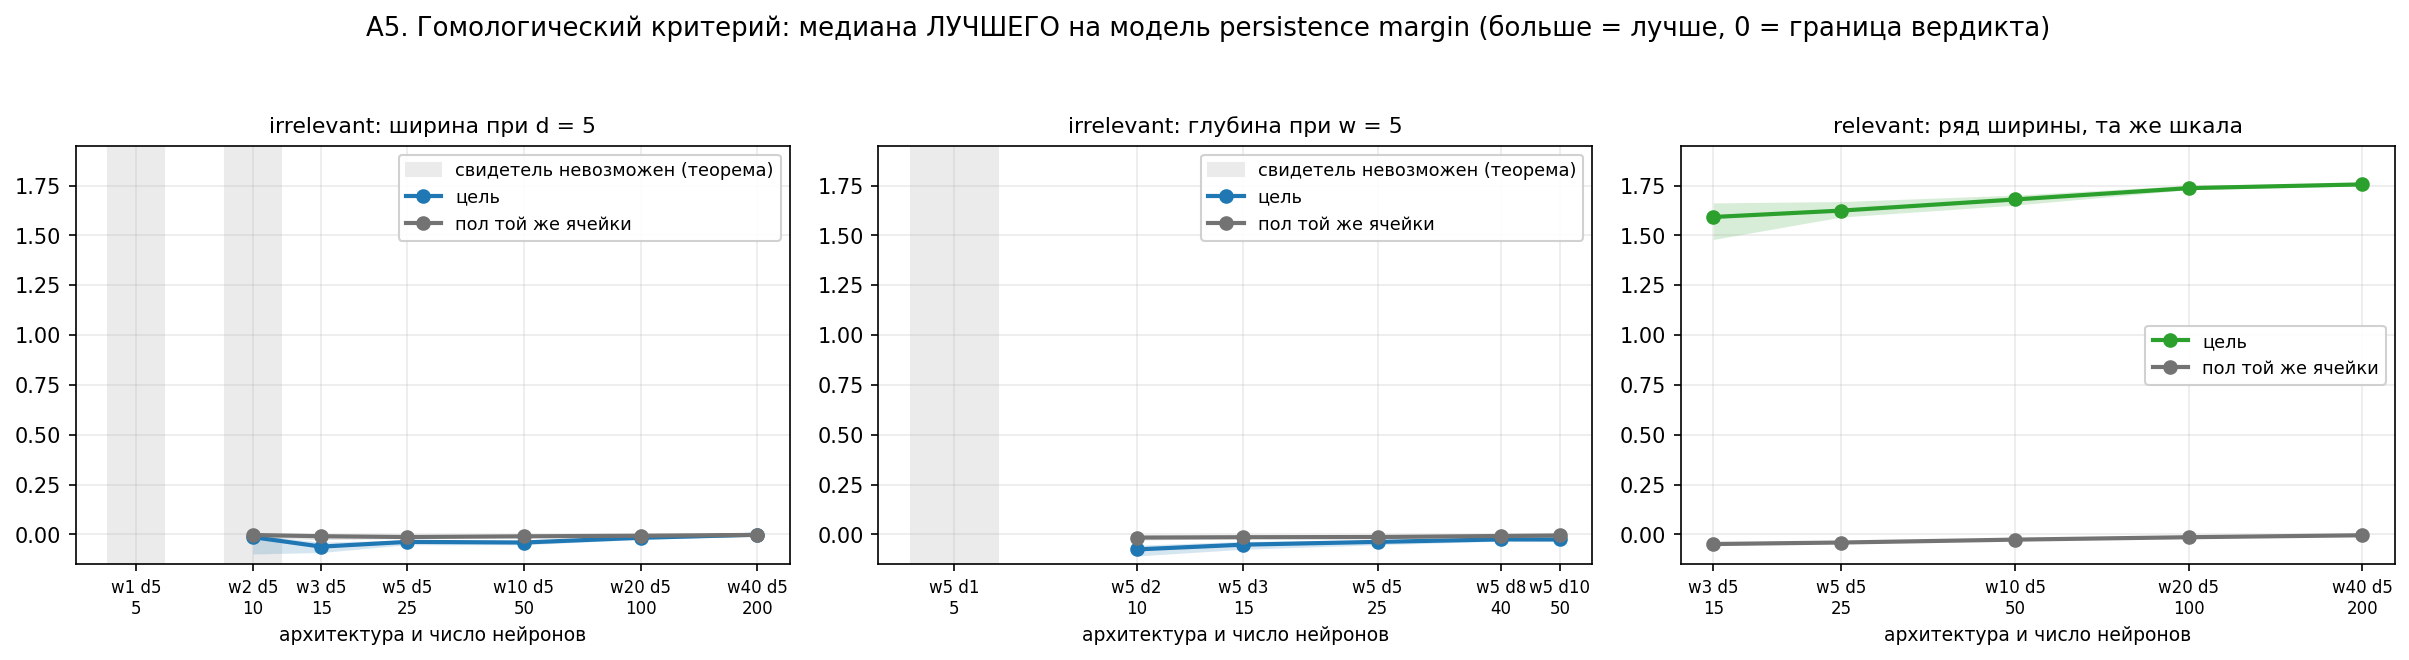

  irrelevant  target  (w20 d5): бара нет у 86.4% нейронов; вердикт сработал у 16 из 5000
  irrelevant  null    (w20 d5): бара нет у 90.5% нейронов; вердикт сработал у 29 из 10000
  relevant    target  (w20 d5): бара нет у 35.4% нейронов; вердикт сработал у 2693 из 5000
  relevant    null    (w20 d5): бара нет у 75.1% нейронов; вердикт сработал у 18 из 10000
всего по всем ячейкам irrelevant : гомологический вердикт у 52 нейронов из 31050
всего по всем ячейкам relevant   : гомологический вердикт у 15048 нейронов из 30300


In [19]:
YL = (-0.15, 1.95)
ap.plot_axis_panels(cells, [
    dict(title="irrelevant: ширина при d = 5", dataset_type=IRR, cells=W_ROW_I,
         series=[("hom_median_best", "цель", "tab:blue"),
                 ("hom_median_best_null", "пол той же ячейки", "0.45")], ylim=YL),
    dict(title="irrelevant: глубина при w = 5", dataset_type=IRR, cells=D_ROW,
         series=[("hom_median_best", "цель", "tab:blue"),
                 ("hom_median_best_null", "пол той же ячейки", "0.45")], ylim=YL),
    dict(title="relevant: ряд ширины, та же шкала", dataset_type=REL, cells=W_ROW_R,
         series=[("hom_median_best", "цель", "tab:green"),
                 ("hom_median_best_null", "пол той же ячейки", "0.45")], ylim=YL),
], suptitle="A5. Гомологический критерий: медиана ЛУЧШЕГО на модель persistence margin "
            "(больше = лучше, 0 = граница вердикта)",
   save_path=FIG / "A5_homological.png")
show(FIG / "A5_homological.png")

for ds, name in ((IRR, "irrelevant"), (REL, "relevant")):
    g = df[(df.dataset_type == ds) & (df.hidden_dim == 20) & (df.n_layers == 5)]
    for role in ("target", "null"):
        b = g[g.feature_role == role]
        nan = b.homological_persistence_margin.isna().mean()
        k, n = int(b.hom_witness.sum()), len(b)
        print(f"  {name:11s} {role:7s} (w20 d5): бара нет у {nan:5.1%} нейронов; "
              f"вердикт сработал у {k} из {n}")
for ds, name in ((IRR, "irrelevant"), (REL, "relevant")):
    tot = df[(df.dataset_type == ds) & (df.feature_role == "target")]
    print(f"всего по всем ячейкам {name:11s}: гомологический вердикт у "
          f"{int(tot.hom_witness.fillna(False).sum())} нейронов из {len(tot)}")

### Что видно на A5

**Разделение по скору, а не по доле — на два порядка и с переменой знака.** Лучший на модель
`persistence_margin`: на `simple_relevant` медиана **+1.74** при поле −0.014, на `simple_irrelevant`
**−0.017** при поле −0.007. Отрицательный margin означает, что бар нужной размерности не пережил
проверку; то есть на нерелевантной цели второй критерий, устроенный совсем иначе, приходит к тому же
вердикту, что и первый.

**Счётом это 52 нейрона из 31 050** по всем ячейкам `irrelevant` — против 15 048 из 30 300 на
`relevant`. Именно счёт, а не доля с четырьмя знаками, стоит держать в голове.

**Растёт ли margin у цели с шириной** на `irrelevant` — да, с −0.075 до −0.017, то есть цель
подбирается к границе вердикта. Но пол делает ровно то же (−0.016 → −0.007), и оба остаются
отрицательными.

---

### A6. Формальный вердикт по существованию

Осталось проверить единственную ячейку с сигналом. Правило объявлено заранее: превышение над полом
считается установленным, только если точный биномиальный интервал доли моделей со свидетелем не
пересекается с интервалом той же величины у пола в той же ячейке.

In [20]:
from scipy.stats import beta

def clopper_pearson(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else float(beta.ppf(alpha, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - alpha, k + 1, n - k))
    return lo, hi

rows = []
for r in cells[cells.dataset_type == IRR].itertuples():
    k = int(round(r.p_has_witness * r.n_models))
    lo, hi = clopper_pearson(k, r.n_models)
    g = df[(df.dataset_type == IRR) & (df.hidden_dim == r.width)
           & (df.n_layers == r.depth) & (df.feature_role == "null")]
    unit = g.groupby(["model_path", "feature_name"]).witness.any()
    lo_n, hi_n = clopper_pearson(int(unit.sum()), len(unit))
    rows.append({"arch": r.arch, "цель": f"{k}/{r.n_models}",
                 "интервал цели": f"[{lo:.3f}, {hi:.3f}]",
                 "пол": f"{int(unit.sum())}/{len(unit)}",
                 "интервал пола": f"[{lo_n:.3f}, {hi_n:.3f}]",
                 "превышение установлено": lo > hi_n})
existence = pd.DataFrame(rows)
existence.to_csv(AGG / "irrelevant_existence.csv", index=False)

signal = existence[existence["цель"] != "0/50"]
print(f"ячеек с ненулевой ставкой: {len(signal)} из {len(existence)}; "
      f"в остальных {len(existence) - len(signal)} — ровно 0/50")
display(signal)

DELTA = 0.05
eq = pd.DataFrame([
    {"arch": r.arch, "p_superior": round(r.p_superior, 4),
     "интервал": f"[{r.p_superior_lo:.3f}, {r.p_superior_hi:.3f}]",
     "равен 0.5": equivalence(r.p_superior, r.p_superior_lo, r.p_superior_hi,
                              DELTA, 0.5)["equivalent"],
     "цель хуже пола": r.p_superior_hi < 0.5 - DELTA}
    for r in cells[cells.dataset_type == IRR].itertuples()])
eq.to_csv(AGG / "irrelevant_equivalence.csv", index=False)
worse = eq[eq["цель хуже пола"]]
print(f"\nцель значимо хуже пола в {len(worse)} ячейках из {len(eq)}; "
      f"не в этом списке только {list(eq[~eq['цель хуже пола']].arch)} "
      f"— ячейка без единого способного нейрона")

ячеек с ненулевой ставкой: 2 из 16; в остальных 14 — ровно 0/50


,arch,цель,интервал цели,пол,интервал пола,превышение установлено
11,w20 d5,4/50,"[0.028, 0.174]",1/100,"[0.001, 0.047]",False
12,w40 d5,3/50,"[0.017, 0.148]",8/100,"[0.040, 0.140]",False



цель значимо хуже пола в 15 ячейках из 16; не в этом списке только ['w1 d5'] — ячейка без единого способного нейрона


### Что видно на A6

**Четырнадцать ячеек из шестнадцати дают ровно 0/50.** Ненулевая ставка есть только в двух, и в
обеих превышение над полом **не установлено** по объявленному правилу:

| ячейка | цель | интервал цели | пол | интервал пола |
|---|---|---|---|---|
| `w20 d5` | 4/50 | [0.028, 0.174] | 1/100 | [0.001, 0.047] |
| `w40 d5` | 3/50 | [0.017, 0.148] | **8/100** | [0.040, 0.140] |

**При двухстах нейронах пол срабатывает чаще цели.** Это и есть ответ на вопрос, который `w20 d5`
оставлял открытым: удвоение ширины не усилило сигнал, а сравняло его с фоном. Ставка на цели даже
снизилась (4/50 → 3/50), тогда как на нулевых размещениях выросла восьмикратно.

**И сами срабатывания у цели и у пола неразличимы.** Все три целевых нейрона `w40 d5` сидят на
**слое 1** (как и три из четырёх при `w20 d5`), скоры 0.0822 / 0.0826 / 0.0988; восемь нулевых — на
слоях 1 и 2, скоры 0.0883–0.0995. Тот же слой, тот же диапазон значений, та же сторона порога. Это
поведение **широкого раннего слоя**: чем больше в нём нейронов, тем выше шанс, что чья-то линия
уровня ляжет рядом с произвольно выбранной фигурой.

Отдельно печатается, что цель значимо **хуже** пола в 15 ячейках из 16; единственное исключение —
`w1 d5`, где способных нейронов нет вовсе.

---

## Итог по A

**Свидетеля избыточная архитектура не производит — но исход (a) «ничего не происходит» тоже неверен.**

1. **Детекции нет, и с ростом ширины она не появляется.** 0 свидетелей из 16 050 целевых строк в
   четырнадцати ячейках из шестнадцати. Все семь срабатываний живут в двух самых широких ячейках и
   на первых двух слоях: четыре в `w20 d5`, три в `w40 d5`. Из семи три компоненты обрезаны боксом и
   недостоверны, четыре выглядят честными замкнутыми линиями уровня. При удвоении ширины ставка
   **не растёт** (4/50 → 3/50), а пол начинает срабатывать **чаще** цели (8/100). Ни в одной из двух
   ячеек биномиальный интервал не отделяется от пола, а **лучший нулевой нейрон всего датасета
   (0.0667) набирает меньше любого целевого** и обводит своё размещение честной замкнутой линией.
2. **Второй критерий подтверждает независимо.** Лучший `persistence_margin` на цели −0.017 против
   +1.74 на релевантной задаче; счётом 52 нейрона из 31 050 на `irrelevant` против 15 048 из 30 300
   на `relevant`.
3. **Ширина сокращает разрыв, глубина нет.** `p_superior` растёт с 0.144 до 0.291 (наклон +0.160
   [+0.088, +0.230] за декаду), по глубине ноль внутри интервала. Это и есть искомый PLAN'ом
   количественный incidental-эффект — слабый и не доходящий до детекции.
4. **Сокращение разрыва идёт не только со стороны цели.** В двойных логарифмах цель падает быстрее
   пола (`N^(−0.341)` против `N^(−0.247)`, интервалы не пересекаются), но отношение цель/пол
   немонотонно: 1.62 → 1.93 → 1.34, то есть до `w10` цель от пола отдаляется. А локальные наклоны
   цели, разгонявшиеся до `w20` (−0.09, −0.20, −0.58), на последнем шаге замедляются до −0.37.
   **Экстраполяции к детекции нет**, и это установлено измерением, а не оценкой интервала.
5. **Пол — это оценка снизу, и говорить надо именно так.** Из пяти размещений эксперимента 1
   оставлены два, а самое трудное (`in_between`, пол 0.368) исключено guideline'ом; механизм видно
   в A2b — мягкий нуль стоит в насыщенном хвосте поля, где градиент в 7.6 раза меньше, чем на цели.
   Поэтому корректная формулировка результата: **скор на нерелевантной окружности лежит выше нижней
   оценки, полученной на нуль-размещениях**. Утверждать по этим данным, что распределения на
   нуль-фичах и на нерелевантных фичах различаются — и тем более что сеть нерелевантную окружность
   «подавляет», — нельзя: мы сами оставили те нули, что дают низкий скор. Вердикт держится на
   пороге, а не на порядке.

**Граница применимости.** Всё сказанное — про окружность в датасете, где она стоит внутри одного
класса и решению не мешает. Абсолютное значение пола, по guideline эксперимента 1, не переносится ни
на другую задачу, ни на другую форму фичи. И ещё одна оговорка, важная для чтения пункта: вдоль ряда
ширины падает не только число нейронов на модель, но и **длительность обучения** — с 16 эпох при
`w3 d5` до 6 при `w40 d5`. Разводит эти два объяснения пункт E.

---

# B. Task-relevant: что происходит при минимуме и при избытке

Тот же критерий, тот же порог, тот же бокс — и та же окружность, побитово. Различается только то,
что теперь без неё задача не решается.

**Точка отсчёта.** `w5 d5`: 49/50 моделей со свидетелем, медиана лучшего 0.0349, 41.9 % всех
нейронов ниже `τ`. Все три числа воспроизвели эксперимент 1 до шестого знака — это и есть проверка,
что новый бокс ничего не сдвинул.

**Два вопроса.**

* При избытке — держится ли доля 41.9 %. Постоянная доля означает, что признак переиспользуется всей
  сетью; падающая при неизменном лучшем — что задачу решает фиксированная малая группа, а остальное
  простаивает.
* Стал ли при этом лучший нейрон лучше — или их просто стало больше.

Третий вопрос, стоявший здесь в первой редакции («остаётся ли одиночный свидетель»), снят: в
формулировке «один нейрон на всю сеть» он внутренне противоречив — тогда на последующих слоях
свидетеля нет, и голова сети признаком не пользуется. Осмысленная версия — в пределах слоя —
индексирована слоем и отнесена к задаче C.

**Асимметрия с пунктом A, заявленная заранее.** На relevant цель набирает столько же, сколько
заведомый свидетель (0.0349 против подсаженного 0.0343), поэтому информативны доля и форма
распределения. На irrelevant цель у пола, и там наоборот. Два датасета читаются разными
статистиками — это следствие эксперимента 1, а не выбор удобной метрики.

### B1. Та же первая фигура, что и в A, — и она сразу другая

Читается точно так же: точка — пара (модель, фича) по её лучшему нейрону, красный пунктир — `τ`,
детекция это лево. Две панели: ряд ширины и ряд глубины.

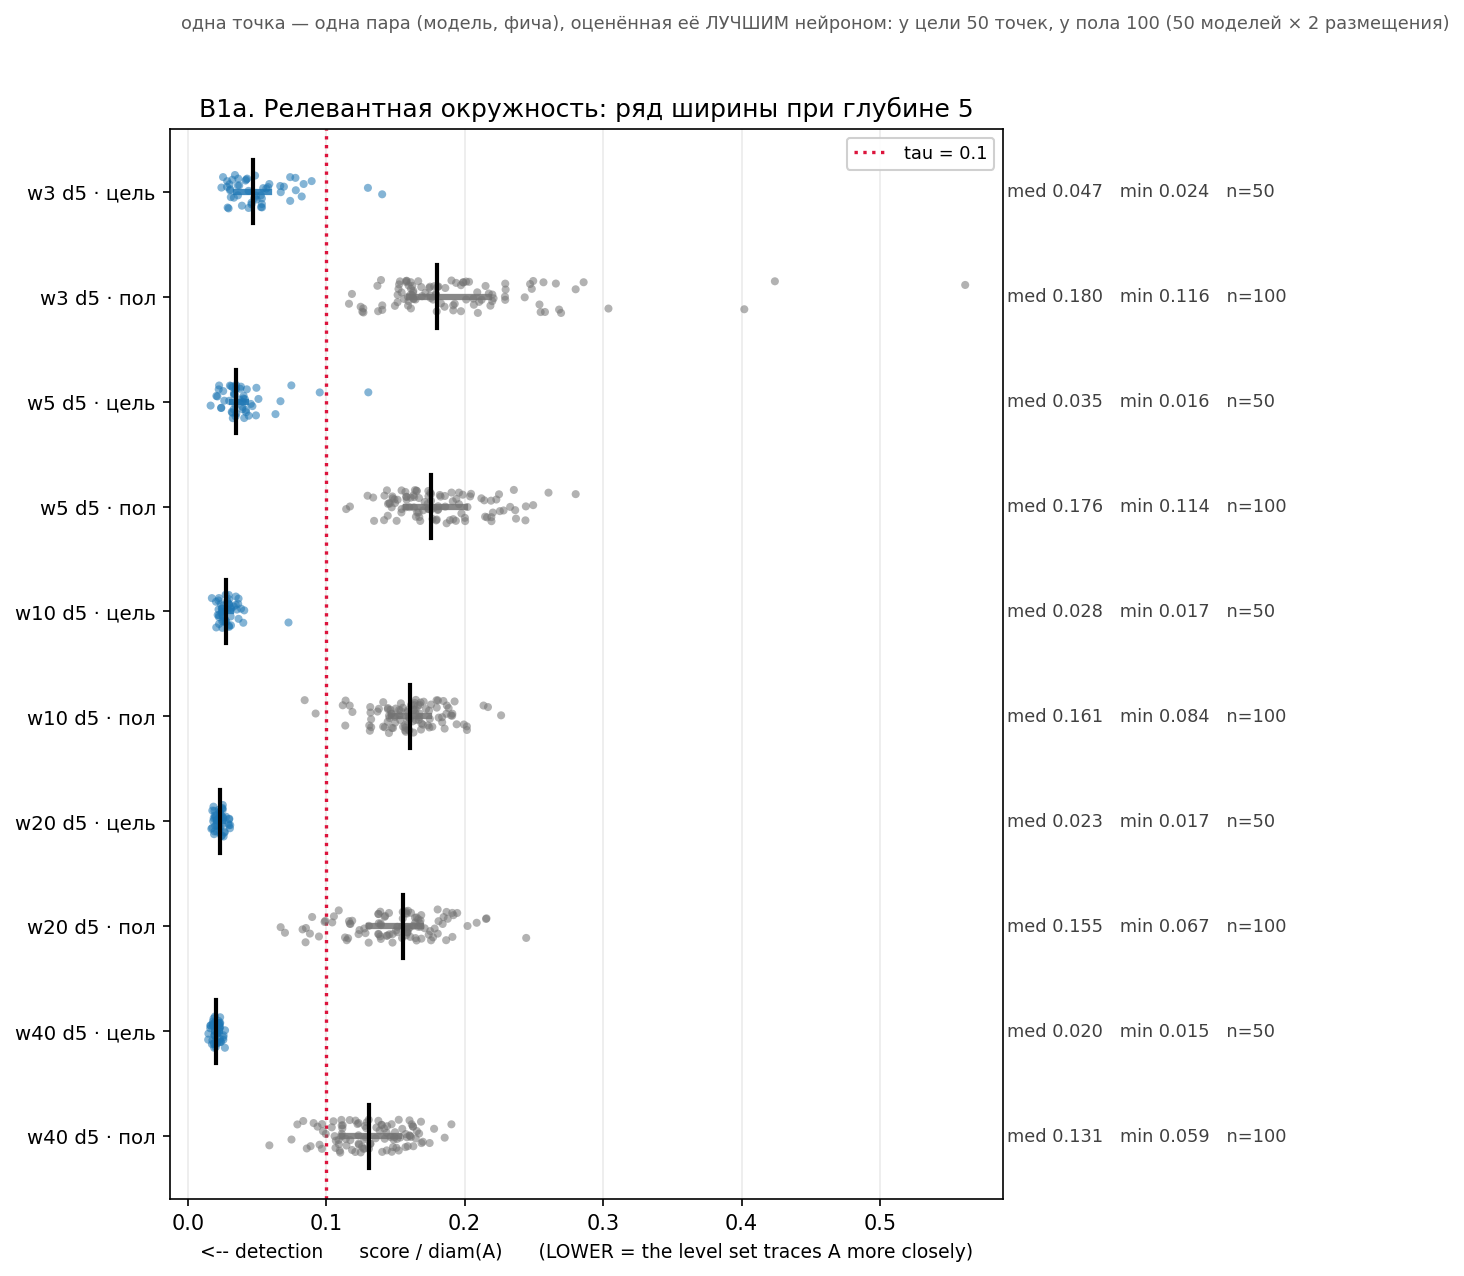

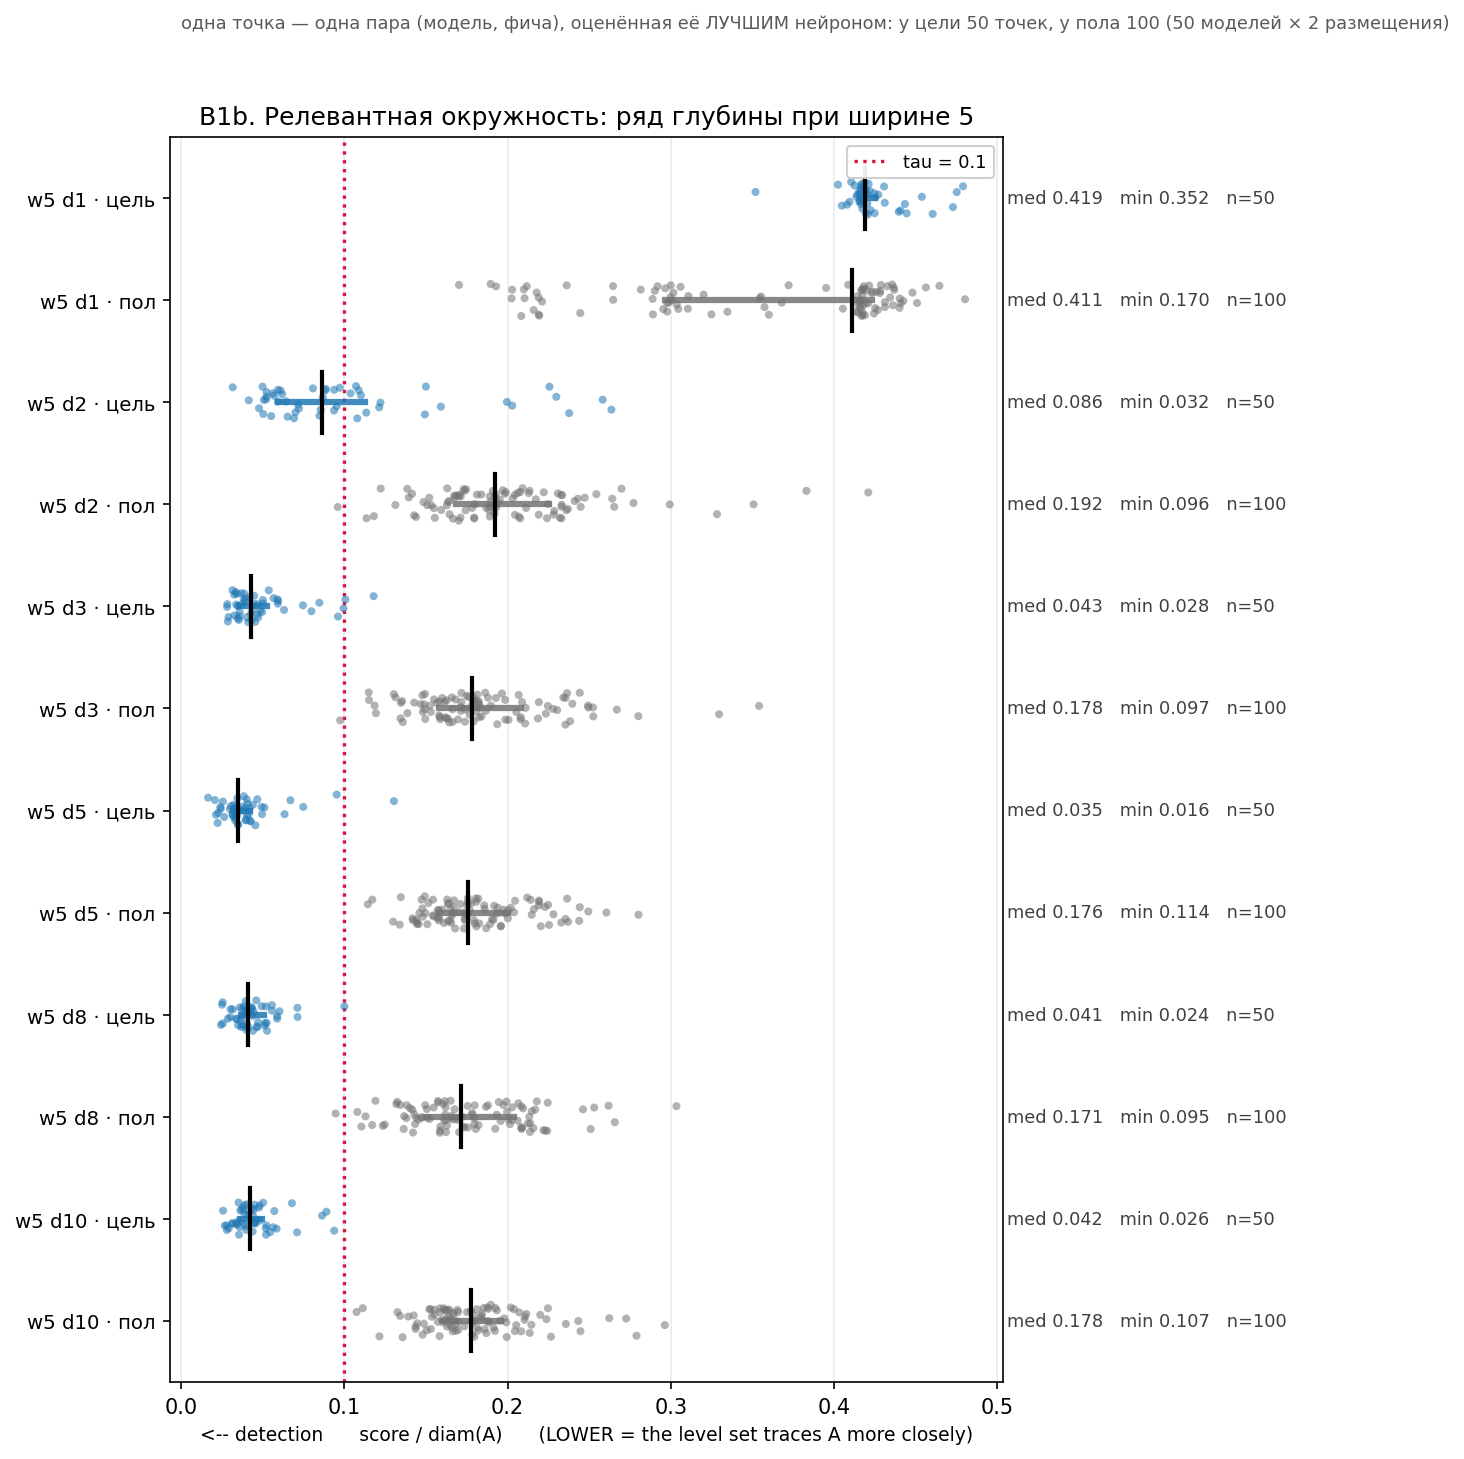

In [21]:
strips(REL, W_ROW_R, "B1a_relevant_width.png",
       "B1a. Релевантная окружность: ряд ширины при глубине 5")
strips(REL, D_ROW, "B1b_relevant_depth.png",
       "B1b. Релевантная окружность: ряд глубины при ширине 5")

### Что видно на B1

**Полное разделение.** Синие облака целиком слева от `τ`, серые целиком справа; они даже не
соприкасаются. Для сравнения, в пункте A синее лежало правее серого. Это тот же инструмент на тех
же данных — различается только роль окружности в задаче.

**Ряд глубины показывает границу.** При `d = 1` синее облако уезжает вправо к 0.42 и сливается с
полом — это теоремный ноль. При `d = 2` разделение уже есть, но неполное. Дальше держится.

**С ростом ширины синее облако сжимается.** Разброс скора между моделями падает монотонно и сильно:
σ = 0.024 при `w3 d5`, 0.019 при `w5`, 0.008 при `w10`, 0.004 при `w20` и **0.003** при `w40` —
в восемь раз. Размах туда же: с 0.024–0.140 до 0.015–0.027. Широкие ансамбли не просто лучше в
среднем, они **однороднее**: у минимальной ширины отдельные модели промахиваются мимо `τ`, у
двухсотнейронных таких нет вовсе.

**Серое облако при этом едет влево.** Медиана пола идёт 0.180 → 0.176 → 0.161 → 0.155 → **0.131** от
`w3` к `w40`. То есть ширина двигает обе популяции в одну сторону, и разбирать это надо парой — чем
и занят пункт B4.

**А по глубине после пятого слоя не меняется почти ничего.** Медиана цели: 0.086 → 0.043 → 0.035 →
0.041 → 0.042 при `d` = 2, 3, 5, 8, 10; медиана пола: 0.192 → 0.178 → 0.176 → 0.171 → 0.178. Обе
величины выходят на полку около `d = 5`, и дальше пятидесяти нейронов, разложенных вглубь, хватает
ровно на то же, на что хватало двадцати пяти. Это наблюдение стоит запомнить — в пунктах C и E
окажется, что за ним стоит одно и то же явление.

---

### B2. Держится ли доля — и что делает глубина

Первая содержательная фигура пункта. Три панели: доля свидетелей против ширины, против глубины, и
`P(в модели есть хоть один свидетель)`.

**Зачем зелёная линия рядом с синей.** Синяя — доля от ВСЕХ нейронов, как в эксперименте 1. Но
знаменатель зависит от глубины: при `d = 2` половина нейронов неспособна по теореме, при `d = 8` —
восьмая часть, поэтому часть роста по глубине арифметическая. Зелёная — та же доля, считая только от
способных нейронов (слой ≥ 1, ширина ≥ 3). Если зелёная растёт так же, как синяя, то эффект глубины
не в знаменателе.

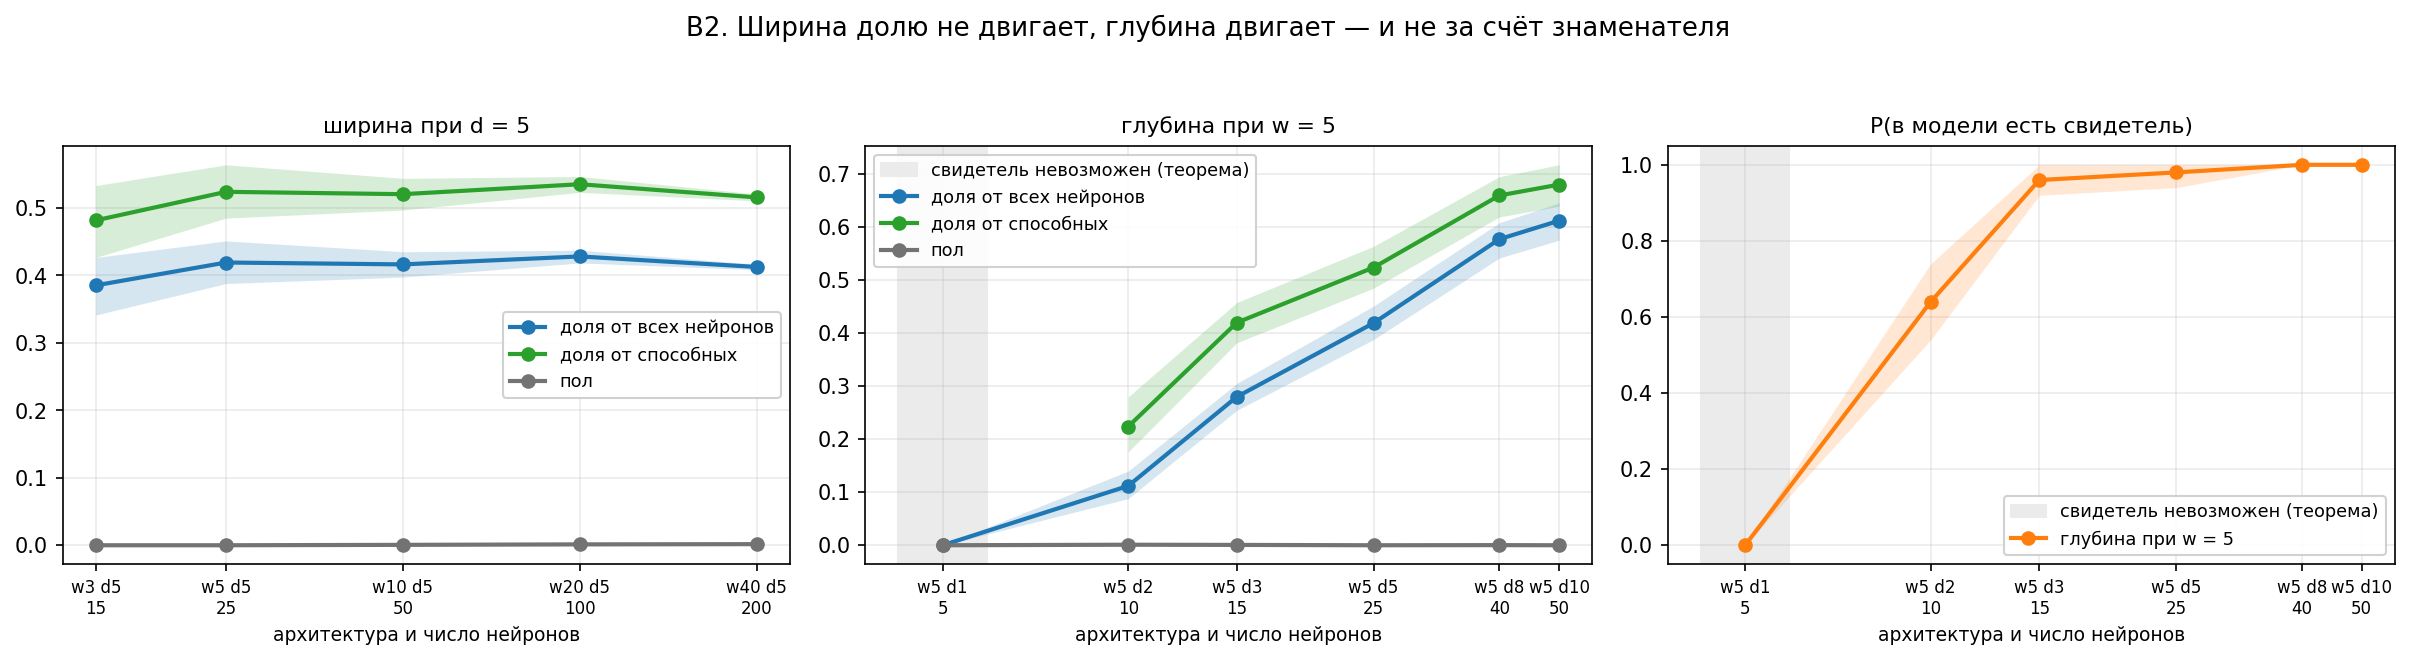

relevant · witness_fraction · ширина                 наклон +0.0208 [-0.0091, +0.0527] за декаду, ноль внутри: True
relevant · witness_fraction_capable · ширина         наклон +0.0260 [-0.0114, +0.0659] за декаду, ноль внутри: True
relevant · witness_fraction · глубина                наклон +0.7159 [+0.6613, +0.7646] за декаду, ноль внутри: False
relevant · witness_fraction_capable · глубина        наклон +0.6368 [+0.5528, +0.7093] за декаду, ноль внутри: False


In [22]:
ap.plot_axis_panels(cells, [
    dict(title="ширина при d = 5", dataset_type=REL, cells=W_ROW_R,
         series=[("witness_fraction", "доля от всех нейронов", "tab:blue"),
                 ("witness_fraction_capable", "доля от способных", "tab:green"),
                 ("null_fraction", "пол", "0.45")]),
    dict(title="глубина при w = 5", dataset_type=REL, cells=D_ROW,
         series=[("witness_fraction", "доля от всех нейронов", "tab:blue"),
                 ("witness_fraction_capable", "доля от способных", "tab:green"),
                 ("null_fraction", "пол", "0.45")]),
    dict(title="P(в модели есть свидетель)", dataset_type=REL, cells=D_ROW,
         series=[("p_has_witness", "глубина при w = 5", "tab:orange")]),
], suptitle="B2. Ширина долю не двигает, глубина двигает — и не за счёт знаменателя",
   save_path=FIG / "B2_relevant_fraction.png")
show(FIG / "B2_relevant_fraction.png")

for cs, axis in ((W_ROW_R, "ширина"), (D_ROW_CAP, "глубина")):
    for st in ("witness_fraction", "witness_fraction_capable"):
        trend(cs, st, REL, f"relevant · {st} · {axis}")

### Что видно на B2

**Ширина долю не двигает.** По всему ряду она держится в полосе 0.385–0.428 при росте ширины в
**13.3 раза** (с пятнадцати нейронов до двухсот): 0.385 → 0.419 → 0.416 → 0.428 → 0.413. Наклон
**+0.021 [−0.009, +0.053]** за декаду нейронов, ноль внутри интервала. По объявленному правилу доля
держится, и утроение размаха оси этого не изменило.

**Глубина двигает её впятеро:** 0.112 → 0.612, наклон **+0.716 [+0.661, +0.765]** — на порядок с
лишним больше, чем по ширине.

**И это не знаменатель.** Зелёная линия идёт почти параллельно синей: наклон доли от способных
**+0.637 [+0.553, +0.709]**. Арифметика первого слоя объясняет малую часть эффекта, остальное
реально.

**`P(есть свидетель)` насыщается быстро:** 0.00 → 0.64 → 0.96 → 0.98 → 1.00 → 1.00 при
`d` = 1, 2, 3, 5, 8, 10. Начиная с трёх слоёв практически каждая модель имеет свидетеля, и дальше
растёт уже не наличие, а количество.

---

### B3. То же самое в штуках — и как разбросано между моделями

Здесь надо сразу сказать, чего эта фигура **не** доказывает. «Доля держится» и «число растёт
линейно» — одно утверждение, записанное дважды: число = доля × N по определению, и никакого
отдельного открытия во втором нет. Конкурирующей гипотезы «постоянное число» тут тоже не проверяют:
она отвергнута уже тем, что доля не падает.

Фигура нужна за другим — за **разбросом**. Доля по ячейке это одно число; она не говорит, все ли
модели ансамбля устроены одинаково или среднее набирается из очень разных. Точка — одна модель,
ромб — медиана ячейки, серая прямая — пересчёт постоянной доли в штуки, для привязки глаза.

Два ряда сразу, ширина и глубина: у них разные доли (0.416 против 0.553), поэтому и наклоны разные.

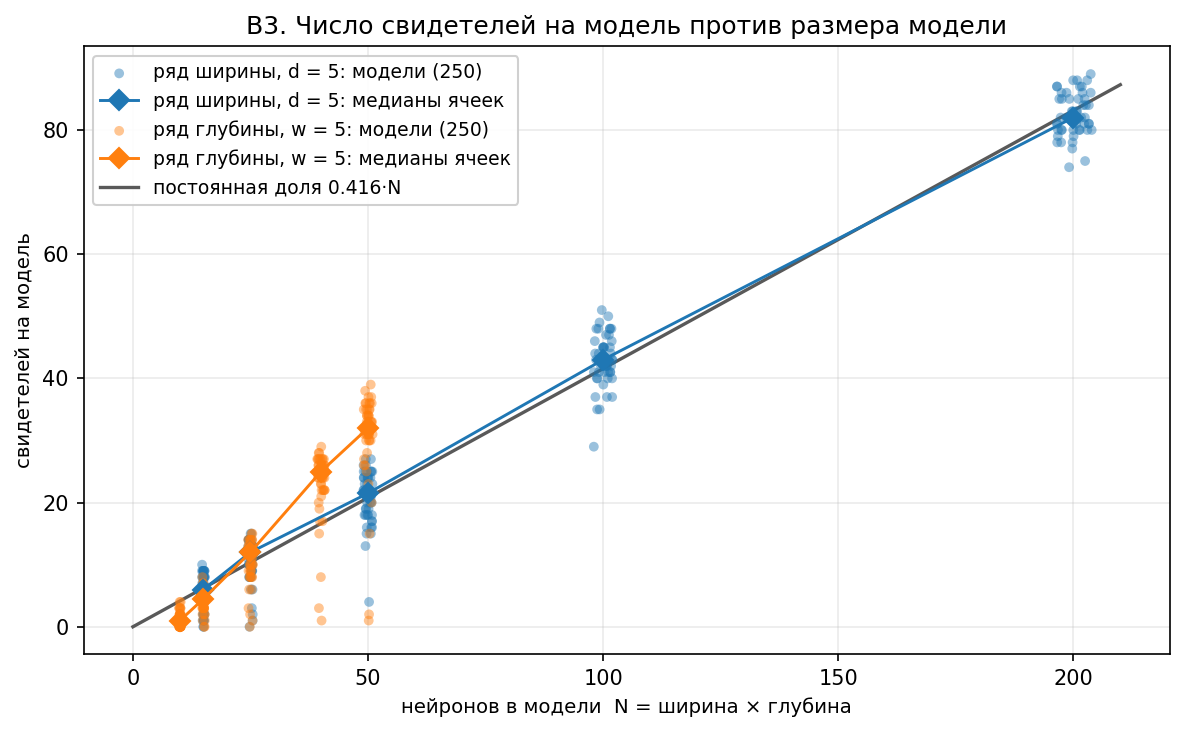

  ширина  : пулированная доля 0.416, то есть в среднем 0.416·N свидетелей на модель
  глубина : пулированная доля 0.553, то есть в среднем 0.553·N свидетелей на модель
  w3 d5  : медиана   6.0, разброс 0–10, межквартильный 5–8
  w5 d5  : медиана  12.0, разброс 0–15, межквартильный 9–13
  w10 d5 : медиана  21.5, разброс 4–27, межквартильный 18–24
  w20 d5 : медиана  43.0, разброс 29–51, межквартильный 41–45
  w40 d5 : медиана  82.0, разброс 74–89, межквартильный 80–85


In [23]:
counts = aw.witness_counts(df, REL, ALL_R)
counts.to_csv(AGG / "witness_counts_per_model.csv", index=False)

fit_width = aw.count_fit(df, REL, W_ROW_R)
fit_depth = aw.count_fit(df, REL, D_ROW_CAP)
pd.DataFrame([{**f, "cells": " ".join(f"w{w}d{d}" for w, d in f["cells"])}
              for f in (fit_width, fit_depth)]).to_csv(AGG / "count_fit.csv", index=False)

w_archs = [f"w{w} d{d}" for w, d in W_ROW_R]
d_archs = [f"w{w} d{d}" for w, d in D_ROW_CAP]
ap.plot_count_vs_neurons(
    [("ряд ширины, d = 5", counts[counts.arch.isin(w_archs)], "tab:blue"),
     ("ряд глубины, w = 5", counts[counts.arch.isin(d_archs)], "tab:orange")],
    fraction=fit_width["fraction"],
    title="B3. Число свидетелей на модель против размера модели",
    save_path=FIG / "B3_count_vs_neurons.png")
show(FIG / "B3_count_vs_neurons.png")

for name, f in (("ширина", fit_width), ("глубина", fit_depth)):
    print(f"  {name:8s}: пулированная доля {f['fraction']:.3f}, "
          f"то есть в среднем {f['fraction']:.3f}·N свидетелей на модель")
for arch in w_archs:
    c = counts[counts.arch == arch]["count"]
    print(f"  {arch:7s}: медиана {c.median():5.1f}, разброс {c.min()}–{c.max()}, "
          f"межквартильный {c.quantile(0.25):.0f}–{c.quantile(0.75):.0f}")

### Что видно на B3

**Разброс между моделями большой и растёт вместе с числом.** При `w3 d5` модели дают от 0 до 10
свидетелей, при `w20 d5` — от 29 до 51. Ансамбль неоднороден: доля 0.43 это не «у каждой модели
43 %», а среднее по заметно разным моделям.

**Относительный разброс при этом падает** — при `w3 d5` межквартильный размах 5–8 при медиане 6, при
`w20 d5` — 41–46 при медиане 43. Ровно то, чего ждёшь, если каждый нейрон подхватывает окружность
независимо: относительный разброс суммы падает как `1/√N`.

**Ряд глубины идёт круче ряда ширины** (доля 0.494 против 0.425) — та же разница, что на B2, просто
в штуках.

---

### B4. Стал ли лучший нейрон лучше — или их просто стало больше

Медиана лучшего улучшается с шириной: 0.0471 → 0.0230. Само по себе это ничего не значит: минимум из
большего числа попыток убывает и тогда, когда все попытки одинаковы по качеству. Нужен способ
отделить одно от другого.

**Пол даёт этот способ, и без единой импортированной константы.** Нулевые размещения живут в тех же
ячейках, им доступно то же число нейронов, и сигнала в них нет по построению. Значит их собственное
падение с ростом сети **и есть эффект множественности**, измеренный здесь, на той же статистике и в
тех же единицах.

**Как построена пунктирная линия.** Это не подгонка и не закон из другого эксперимента. Берём цель в
референсной ячейке `w5 d5` и двигаем её ровно настолько, насколько сдвинулся ПОЛ:

```
предсказание(ячейка) = цель(w5 d5) × пол(ячейка) / пол(w5 d5)
```

Она читается как «где стоял бы лучший нейрон, если бы ширина меняла только число попыток».
**Точка на линии — улучшения нет. Точка ниже линии — нейроны действительно стали ближе к A.**

Под фигурой печатаются показатели степени в двойных логарифмах для цели и для пола — то же
сравнение, но числом.

  цель  по ширине: N^(-0.315) [-0.357, -0.276]
  пол   по ширине: N^(-0.117) [-0.141, -0.093]


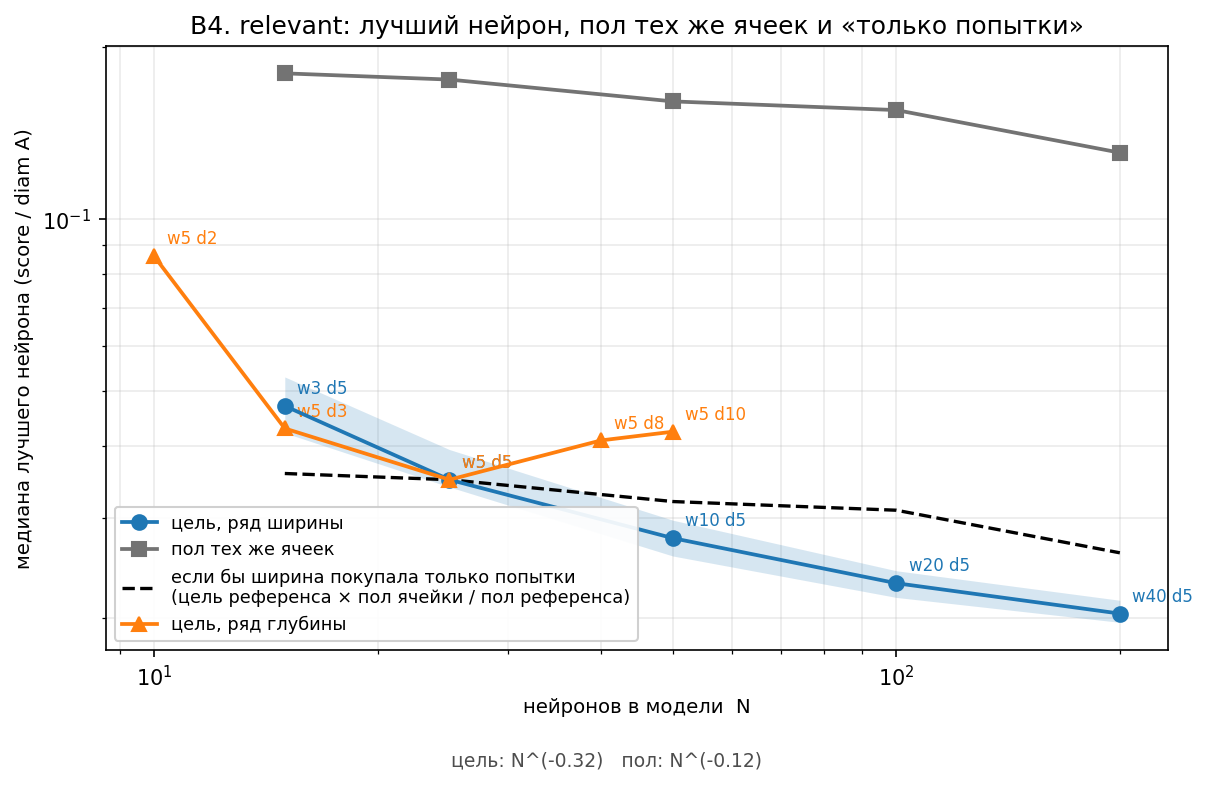

  w3 d5  : измерено 0.0471 [0.0422, 0.0529], «только попытки» дало бы 0.0358 — измеренное хуже в 1.31 раза
  w5 d5  : измерено 0.0349 [0.0339, 0.0395], «только попытки» дало бы 0.0349 — измеренное хуже в 1.00 раза
  w10 d5 : измерено 0.0276 [0.0257, 0.0297], «только попытки» дало бы 0.0320 — измеренное ЛУЧШЕ в 1.16 раза
  w20 d5 : измерено 0.0230 [0.0217, 0.0242], «только попытки» дало бы 0.0309 — измеренное ЛУЧШЕ в 1.34 раза
  w40 d5 : измерено 0.0204 [0.0197, 0.0215], «только попытки» дало бы 0.0260 — измеренное ЛУЧШЕ в 1.28 раза

нейронов ниже заявленного экспериментом 1 «потолка инструмента» 0.0343: 4461 из 30300 (14.7%); самый низкий скор пула 0.0147
  w 3 d5: ниже потолка  4.93%, минимум 0.0243
  w 5 d5: ниже потолка  7.76%, минимум 0.0165
  w10 d5: ниже потолка 15.80%, минимум 0.0174
  w20 d5: ниже потолка 24.72%, минимум 0.0170
  w40 d5: ниже потолка 24.90%, минимум 0.0147


In [24]:
check = aw.floor_scaled_check(cells, REL)
check.to_csv(AGG / "floor_scaled_check.csv", index=False)

exps = {}
for st, name in (("median_best", "цель"), ("median_best_null", "пол")):
    e = aw.loglog_exponent(df, W_ROW_R, REL, st, n_boot=2000)
    exps[name] = e["exponent"]
    print(f"  {name:5s} по ширине: N^({e['exponent']:+.3f}) "
          f"[{e['exponent_lo']:+.3f}, {e['exponent_hi']:+.3f}]")

ap.plot_best_vs_floor(check, W_ROW_R, D_ROW_CAP, exponents=exps,
    title="B4. relevant: лучший нейрон, пол тех же ячеек и «только попытки»",
    save_path=FIG / "B4_best_vs_floor.png")
show(FIG / "B4_best_vs_floor.png")

for r in check[check.arch.isin([f"w{w} d{d}" for w, d in W_ROW_R])].itertuples():
    print(f"  {r.arch:7s}: измерено {r.median_best:.4f} "
          f"[{r.median_best_lo:.4f}, {r.median_best_hi:.4f}], "
          f"«только попытки» дало бы {r.predicted_median_best:.4f} — "
          + (f"измеренное ЛУЧШЕ в {1 / r.observed_over_predicted:.2f} раза"
             if r.observed_over_predicted < 1 else
             f"измеренное хуже в {r.observed_over_predicted:.2f} раза"))

CEIL = 0.0343
t = df[(df.dataset_type == REL) & (df.feature_role == "target")]
print(f"\nнейронов ниже заявленного экспериментом 1 «потолка инструмента» {CEIL}: "
      f"{int((t.score < CEIL).sum())} из {len(t)} ({(t.score < CEIL).mean():.1%}); "
      f"самый низкий скор пула {t.score.min():.4f}")
for w, d in W_ROW_R:
    g = t[(t.hidden_dim == w) & (t.n_layers == d)]
    print(f"  w{w:2d} d{d}: ниже потолка {(g.score < CEIL).mean():6.2%}, "
          f"минимум {g.score.min():.4f}")

### Что видно на B4

Вопрос пункта простой: лучший нейрон широкой сети лучше — но не потому ли просто, что он выбран из
большего числа кандидатов? Ответить на это теорией нельзя, потому что неизвестно, сколько
«независимых попыток» даёт данная архитектура. Зато это можно **измерить**: пол — это и есть то, что
множественность делает со скором, потому что нулевое размещение выбрано так, чтобы ничего, кроме
множественности, за ним не стояло. Поэтому эталон берётся из пола тех же самых ячеек, а не из закона.

**Цель падает заметно быстрее пола.** В двойных логарифмах цель идёт как `N^(−0.315) [−0.357, −0.276]`,
пол — как `N^(−0.117) [−0.141, −0.093]`: почти втрое круче, интервалы не пересекаются. Значит ширина
покупает не только билеты — нейроны действительно становятся ближе к окружности.

**Но выигрыш появляется не сразу и не растёт бесконечно.** Относительно линии «столько, сколько дала
бы одна множественность», ячейки идут так: `w3 d5` **хуже** её в 1.31 раза, `w5 d5` — сама привязка,
`w10 d5` лучше в 1.16, `w20 d5` лучше в 1.34, `w40 d5` лучше в **1.28**. То есть на минимальной
архитектуре лучший нейрон хуже, чем дала бы одна множественность; преимущество появляется за
референсом, растёт до `w20` и на удвоении ширины останавливается.

**Останавливается оно не из-за цели, а из-за пола.** На последнем шаге пол падает резко — с 0.1553 до
0.1308, локальный наклон −0.25 против −0.05 на предыдущих отрезках, — тогда как цель продолжает
улучшаться ровно (0.0230 → 0.0204). При двухстах нейронах в слое множественность наконец заработала в
полную силу: перебирая столько линий уровня, ансамбль находит приличную и на заведомо неверном месте.
Разрыв сократился потому, что подтянулся фон, а не потому, что ослаб сигнал.

**По глубине то же сравнение даёт противоположный ответ.** `w5 d8` с сорока нейронами даёт 0.0410, а
`w5 d10` с пятьюдесятью — 0.0424, тогда как `w5 d5` с двадцатью пятью даёт **0.0349**. Пол при этом
вдоль ряда глубины стоит на месте (0.192 → 0.178). Значит нейроны, добавленные вглубь, не работают ни
как дополнительные попытки, ни как улучшение качества: после пятого слоя глубина не покупает ничего.
Механизм этого разбирается в пункте C.

**Заодно всё это опровергает «потолок инструмента» эксперимента 1.** Там из разложения подсаженного
нейрона (0.0343, из которых 0.0016 геометрия) был сделан вывод: «при R = 200 ни один нейрон, каким бы
идеальным он ни был, ниже не опустится». В этом пуле ниже 0.0343 опускаются **4 461 нейрон из
30 300**, самый низкий — **0.0147**. И доля таких растёт с шириной: 4.9 % при `w3 d5`, 7.8 % при
`w5 d5`, 15.8 % при `w10 d5`, 24.7 % при `w20 d5`, 24.9 % при `w40 d5`.

Ошибка была не в измерении, а в обобщении: 0.0343 — накладные расходы **того конкретного зонда**.
Подсаженный нейрон строится с нормировкой шапки на единицу, его поле доходит лишь до ≈ 0.76 и
остаётся пологим, поэтому адаптивная ε у него широкая. У обученного нейрона с крутым кольцом полоса
уровня тоньше и накладные расходы меньше. **Переносится метод разложения, а не число.**

---

### B5. Равный бюджет нейронов: ширина против глубины без конфаунда

Ряды B2 меняли форму сети вместе с числом нейронов, поэтому «глубина сильнее ширины» там сказано с
оговоркой. Диагональ равного бюджета снимает оговорку: пять архитектур по **24–25 нейронов**
каждая, от `w24 d1` до `w3 d8`. Число нейронов постоянно, меняется только форма.

Это формально вопрос задачи D, но без него выводы A и B неполны: там сравнивались архитектуры
разного размера, и здесь проверяется, переживает ли вывод фиксацию бюджета. Полная развёртка ширины
против глубины остаётся за D.

Слева relevant, справа irrelevant — обе задачи на одной оси, потому что интересен именно контраст.

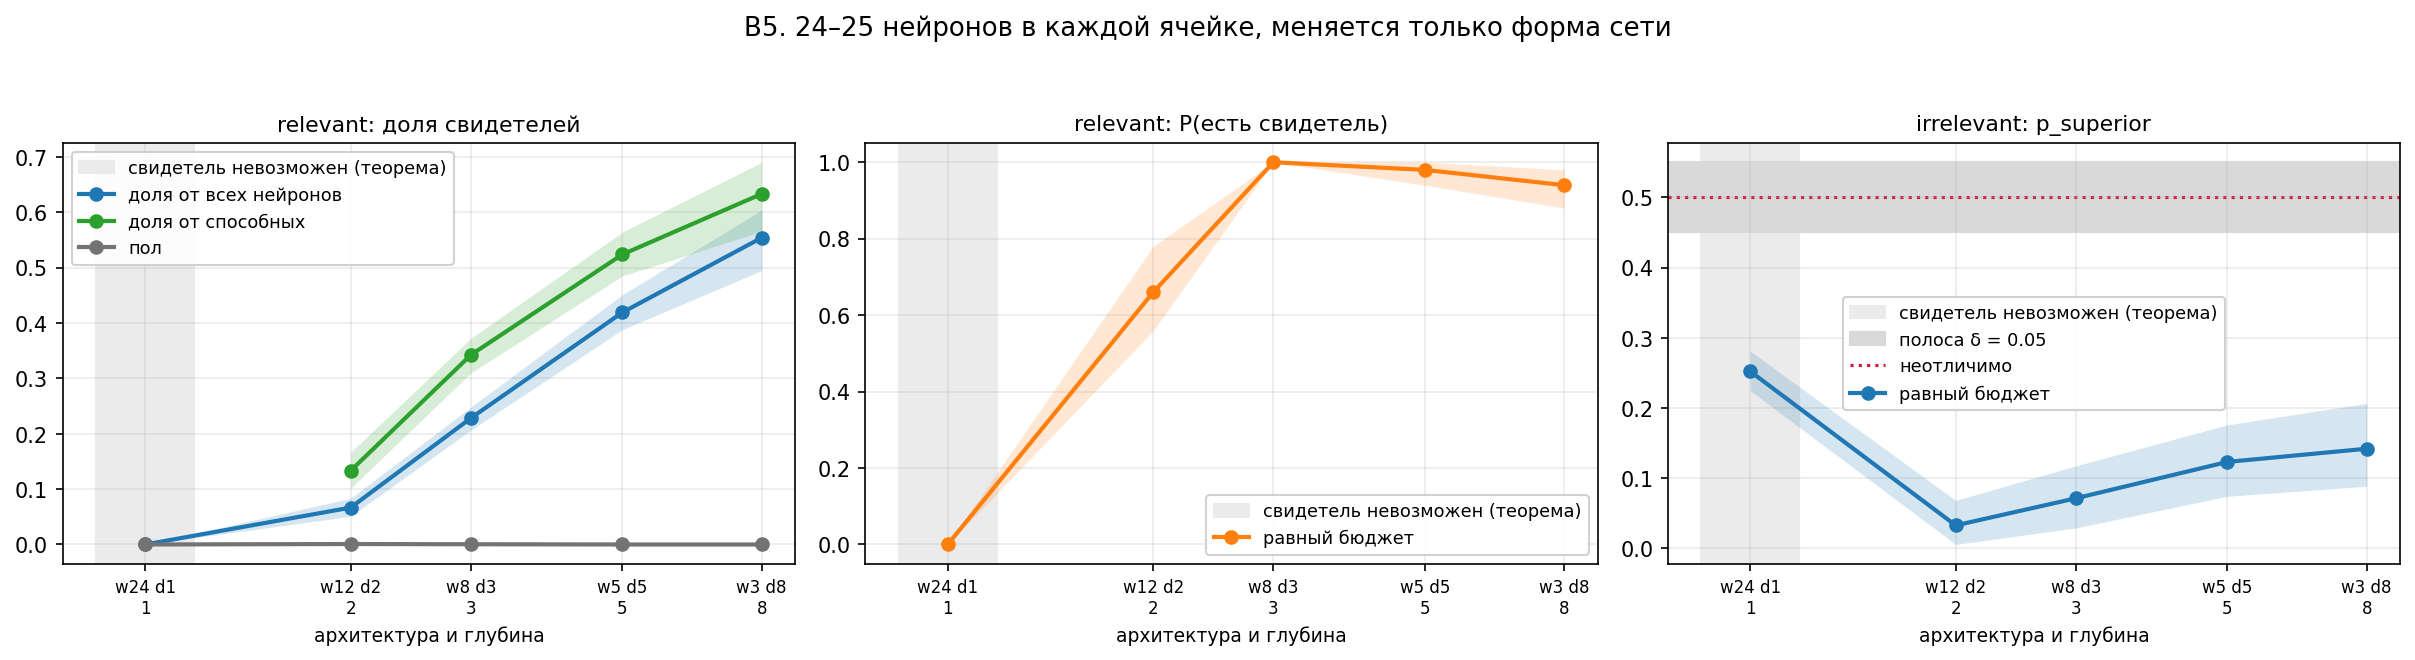

relevant, равный бюджет:
  w24 d1  (24 нейронов,  0 способных): доля 0.000, P(есть) 0.00
  w12 d2  (24 нейронов, 12 способных): доля 0.067, P(есть) 0.66
  w8 d3   (24 нейронов, 16 способных): доля 0.228, P(есть) 1.00
  w5 d5   (25 нейронов, 20 способных): доля 0.419, P(есть) 0.98
  w3 d8   (24 нейронов, 21 способных): доля 0.554, P(есть) 0.94

все наклоны сохранены в analysis/results/experiments/exp2_arch_sweep/aggregates/arch_trends.csv (6 строк)


In [25]:
ap.plot_axis_panels(cells, [
    dict(title="relevant: доля свидетелей", dataset_type=REL, cells=BUDGET_ROW,
         series=[("witness_fraction", "доля от всех нейронов", "tab:blue"),
                 ("witness_fraction_capable", "доля от способных", "tab:green"),
                 ("null_fraction", "пол", "0.45")]),
    dict(title="relevant: P(есть свидетель)", dataset_type=REL, cells=BUDGET_ROW,
         series=[("p_has_witness", "равный бюджет", "tab:orange")]),
    dict(title="irrelevant: p_superior", dataset_type=IRR, cells=BUDGET_ROW,
         series=[("p_superior", "равный бюджет", "tab:blue")],
         hline=(0.5, "неотличимо"), band=(0.45, 0.55, "полоса δ = 0.05")),
], x="depth",
   suptitle="B5. 24–25 нейронов в каждой ячейке, меняется только форма сети",
   save_path=FIG / "B5_equal_budget.png")
show(FIG / "B5_equal_budget.png")

b = cells[(cells.dataset_type == REL) & cells.arch.isin(
    [f"w{w} d{d}" for w, d in BUDGET_ROW])].sort_values("depth")
print("relevant, равный бюджет:")
for r in b.itertuples():
    print(f"  {r.arch:7s} ({r.n_neurons:2d} нейронов, {r.n_capable:2d} способных): "
          f"доля {r.witness_fraction:.3f}, P(есть) {r.p_has_witness:.2f}")

pd.DataFrame(TRENDS).to_csv(AGG / "arch_trends.csv", index=False)
print(f"\nвсе наклоны сохранены в {AGG / 'arch_trends.csv'} ({len(TRENDS)} строк)")

### Что видно на B5

**При постоянном бюджете доля растёт с глубиной монотонно.** Двадцать четыре нейрона дают долю
свидетелей 0.00 при одном слое, 0.07 при двух, 0.23 при трёх и **0.55 при восьми**. Число нейронов
всё это время одно и то же — меняется только форма сети. Конфаунда с размером нет.

`P(есть свидетель)` насыщается уже на трёх слоях и дальше не растёт: меняется не наличие, а
количество. Небольшой спад на восьми слоях — это ячейка `w3 d8`, где ширина равна минимальной и
часть моделей обучается на грани.

**На irrelevant форма сети цель не улучшает.** `p_superior` при равном бюджете остаётся глубоко
ниже 0.5 на всех пяти формах, но не постоянен: среди способных ячеек он идёт 0.033 → 0.071 → 0.123 →
0.142 с глубиной, то есть вчетверо. Смотреть, однако, надо на то, ЧТО из двух величин двигается:
медиана цели вдоль ряда стоит на месте (0.4126 → 0.4080), а пол портится (0.1976 → 0.2458). Значит
глубина при равном бюджете делает труднее НУЛЕВЫЕ размещения, а не легче цель, и сокращение разрыва,
найденное в A2, всё равно идёт от **числа** нейронов, а не от того, как они разложены. Подробнее —
в пункте D.

---

## Итог по B

**1. Ширина не меняет долю, но меняет число.** При росте ширины в 13.3 раза доля свидетелей стоит на
месте (0.385–0.428, интервал наклона включает ноль), а их количество растёт пропорционально сети —
с шести до **восьмидесяти двух**. Читается так: **каждый добавленный нейрон подхватывает окружность
примерно с той же вероятностью, что и уже имевшиеся.** Простаивающей ширины нет.

**1b. Ширина делает ансамбль однороднее.** Разброс лучшего скора между моделями падает в восемь раз
(σ = 0.024 при `w3 d5` против 0.003 при `w40 d5`), и на двухстах нейронах ни одна модель мимо `τ` не
промахивается. Пол при этом едет в ту же сторону (0.180 → 0.131), поэтому обе величины и разбираются
парой.

**2. Ширина при этом делает нейроны и качественно лучше — но преимущество упирается в пол.** Лучший
нейрон улучшается быстрее, чем объясняется одной множественностью (`N^(−0.315)` против `N^(−0.117)`
у пола, интервалы не пересекаются). Относительно эталона множественности, взятого из пола тех же
ячеек, выигрыш растёт до `w20 d5` (в 1.34 раза) и на `w40 d5` перестаёт расти (1.28) — потому что
при двухстах нейронах резко пошёл вниз сам пол. На минимальной архитектуре наоборот: там лучший
нейрон в 1.31 раза **хуже** эталона, то есть выигрыш появляется только за референсом.

**3. Глубина сильнее ширины, и это не артефакт.** Доля свидетелей растёт с глубиной **впятеро**
(0.11 → 0.61), тогда как ширина её не двигает. Эффект переживает две проверки: он остаётся, если
считать долю только от нейронов, способных нести замкнутую линию уровня, и он остаётся при
**фиксированном числе нейронов** (B5). При этом после пятого слоя перестаёт меняться почти всё:
качество лучшего нейрона идёт 0.0349 → 0.0410 → 0.0424 при `d = 5, 8, 10`, а пол стоит на месте
(0.176 → 0.171 → 0.178). Глубина добавляет свидетелей, а не резкость, и добавляет их не как
дополнительные попытки — иначе пол падал бы вместе с числом нейронов, как он падает по ширине.
Механизм разбирается в C.

**4. Ноль при глубине 1 — теорема, а не результат.** Единственный скрытый слой сети глубины 1 есть
`tanh(w·x + b)`, его линии уровня — прямые. `w24 d1`, двадцать четыре нейрона и ноль свидетелей, это
демонстрирует и заодно задаёт границу применимости всего пункта.

**Поправка к эксперименту 1.** Заявленный там «потолок инструмента» 0.0343 потолком не является: в
этом пуле ниже него опускаются 4 461 нейрон из 30 300, самый низкий скор 0.0147. Число было
накладными расходами конкретного подсаженного зонда с пологим полем, а не свойством инструмента при
`R = 200`. Отчёт и ноутбук эксперимента 1 поправлены.

**Оговорка, снимаемая пунктом E.** Вдоль ряда ширины меняется не только число нейронов: гейт
срабатывает тем раньше, чем сеть шире, и медиана остановки падает со 124 эпох при `w3 d5` до 9 при
`w40 d5`. Пока эти два объяснения не разведены, все выводы по оси ширины формально условны.

**Куда это продолжается.**

* Сколько свидетелей в каждом слое и один ли это нейрон на слой — **задача C** (перенесено из B).
* Остаётся ли свидетель слоя `l` на слое `l + 1`, и годится ли непрерывность по слоям как фильтр
  ложных срабатываний — тоже **задача C**.
* Полная развёртка ширины против глубины, за пределами одной диагонали, — **задача D**.
* Разведение «ширины» и «длительности обучения» — **задача E**.

---

# C. Свидетели по слоям

Пункты A и B считали по всей сети сразу. Здесь добавляется единственная новая ось — **номер слоя**, и
всё, что в C делается, ею индексировано. Это же и граница с соседними экспериментами, и проводится
она не соглашением, а данными: в пуле **одна** целевая фича на датасет и **никакого вмешательства** в
сеть.

| соседний вопрос | почему C его не трогает |
|---|---|
| multitasking — один нейрон свидетельствует несколько фичей | нужны две целевые фичи в одном датасете; здесь одна |
| абляция — нужен ли нейрон причинно | нужно вмешательство в сеть; C только наблюдает |
| распределённое кодирование — сколько нейронов требуется | «требуется» без абляции не устанавливается |

Поэтому всюду ниже «признак несут несколько нейронов» означает **наблюдаемую кратность**, и ничего
про необходимость.

**Что здесь называется профилем.** Профиль — это зависимость какой-либо характеристики свидетельства
от номера скрытого слоя, при фиксированной архитектуре и фиксированной фиче. Характеристик будет
три: доля нейронов слоя, прошедших `τ`; медианный скор нейрона слоя; доля нейронов слоя, у которых
сработал гомологический критерий.

---

## Шесть вопросов

1. **Как выглядит профиль и двигается ли он с архитектурой.** Профиль при `w5 d5` уже померен
   экспериментом 1; вклад C — зависимость от ширины и глубины.
2. **Тот же профиль в непрерывной валюте и по второму критерию** — потому что доля свидетелей
   зависит от `τ`, а скор и гомологический вердикт от него не зависят или зависят иначе.
3. **Свидетельствует ли окружность сам выход сети.** Отдельный вопрос, а не служебная деталь: выход —
   это ровно та функция, по которой ставится вердикт классификатора, и её скор напрямую сравним со
   скорами скрытых нейронов. Ответ нужен и сам по себе, и дальше — в вопросах 4 и 6.
4. **Описывает ли профили одна кривая**, если положение слоя нормировать на глубину сети и
   добавить голову как последний слой. Это бывшая задача E; она влита сюда, потому что без ответа на
   неё профиль нечитаем, а сам ответ считается из тех же кривых.
5. **Сколько свидетелей в одном слое и как это число меняется от слоя к слою.** Перенесено из B: в
   формулировке «один нейрон на всю сеть» вопрос противоречив, в пределах слоя — корректен.
6. **Годится ли непрерывность по слоям как фильтр ложных срабатываний.** Если признак выделен на
   слое `l` и ни один более глубокий слой его не несёт, голова сети, читающая последний слой, им не
   пользуется — и такое срабатывание есть кандидат в ложные, по основанию, не зависящему от `τ`.
   Сюда же — проверка, растёт ли профиль внутри каждой модели, а не только в среднем.

Нового счёта требует только выход сети (вопросы 3, 4 и 6) — пара секунд на модель; всё остальное
считается из тех же 184 050 строк, где колонка `layer_id` уже лежит.

---

### C1. Профиль и его зависимость от архитектуры

**Что рисуем.** Доля нейронов слоя, прошедших `τ`, против номера слоя. Одна кривая на ячейку,
полоса — бутстрап-интервал по моделям (единица пересэмплирования остаётся моделью, хотя величина
индексирована слоем). Слева ряд глубины при `w = 5`, справа ряд ширины при `d = 5`.

**Пунктиром — пол тех же ячеек.** Он здесь обязателен: у нулей профиль по слоям тоже мог бы быть
(эксперимент 1 мерил на `far_right` падение 0.422 → 0.228 от слоя 0 к слою 3), поэтому без него
растущую кривую нельзя отличить от «с глубиной всё вообще становится кривее».

**Что фигура не показывает.** Это средние по ансамблю. Растёт ли профиль внутри каждой отдельной
модели — вопрос того же типа, что и фильтр непрерывности, и оба считаются в C6.

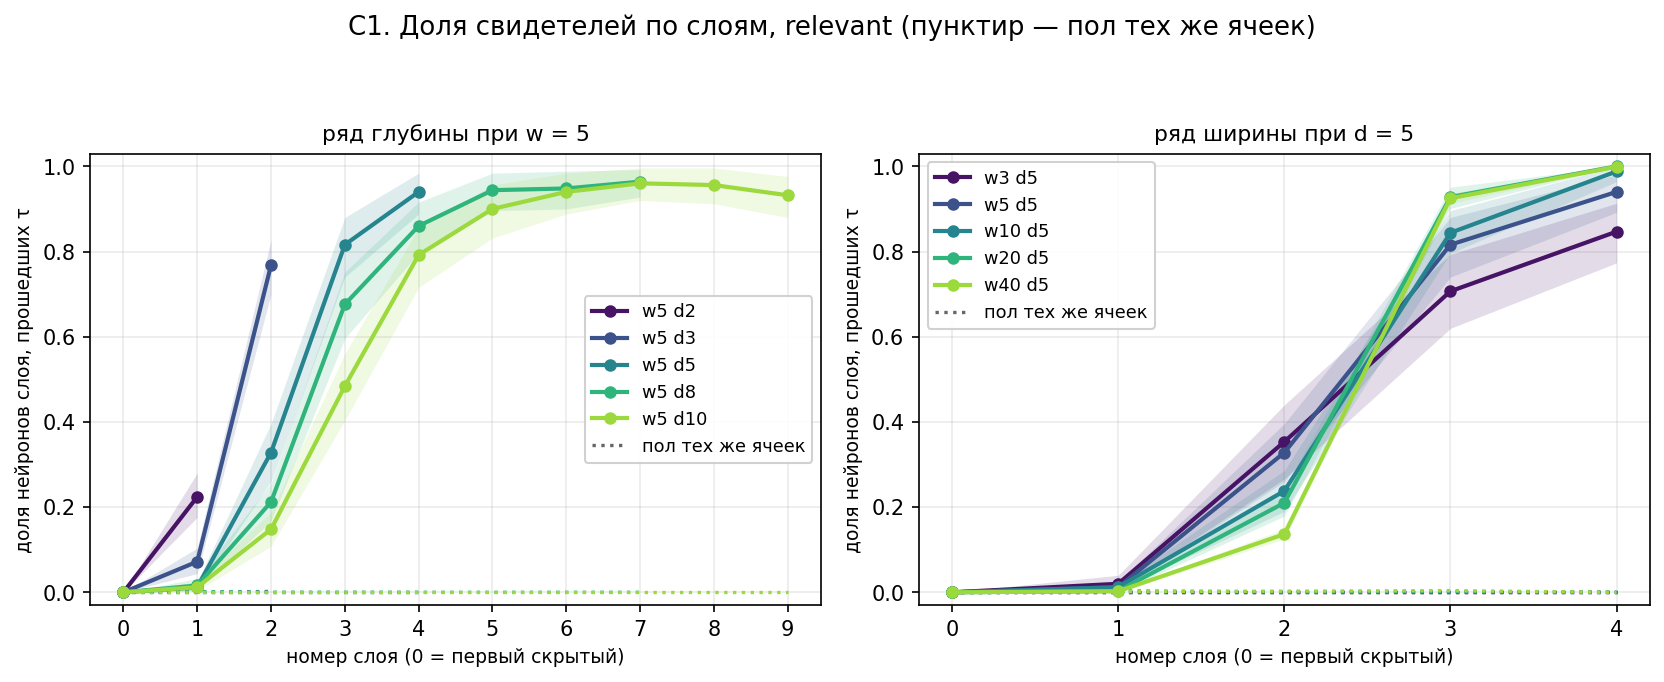

доля свидетелей по слоям, ряд глубины:
  d =  2: 0.000 0.224
  d =  3: 0.000 0.072 0.768
  d =  5: 0.000 0.012 0.328 0.816 0.940
  d =  8: 0.000 0.016 0.212 0.676 0.860 0.944 0.948 0.964
  d = 10: 0.000 0.012 0.148 0.484 0.792 0.900 0.940 0.960 0.956 0.932

ряд ширины, слои 1-4:
  w 3 d5: 0.000 0.020 0.353 0.707 0.847
  w 5 d5: 0.000 0.012 0.328 0.816 0.940
  w10 d5: 0.000 0.012 0.238 0.844 0.988
  w20 d5: 0.000 0.003 0.210 0.928 1.000
  w40 d5: 0.000 0.003 0.136 0.925 0.999

максимум профиля на irrelevant по всем слоям и ячейкам: 0.0030
максимум пола на relevant по всем слоям и ячейкам:      0.0040


In [26]:
D_ROW_C = [(5, 2), (5, 3), (5, 5), (5, 8), (5, 10)]   # ряд глубины, без d1
W_ROW_C = [(3, 5), (5, 5), (10, 5), (20, 5), (40, 5)]  # ряд ширины
ALL_C = list(dict.fromkeys(D_ROW_C + W_ROW_C))

prof_depth = aw.layer_profile(df, REL, D_ROW_C, n_boot=2000)
prof_width = aw.layer_profile(df, REL, W_ROW_C, n_boot=2000)
floor_depth = aw.layer_profile(df, REL, D_ROW_C, role="null", n_boot=2000)
floor_width = aw.layer_profile(df, REL, W_ROW_C, role="null", n_boot=2000)
prof_irr = aw.layer_profile(df, IRR, ALL_C, n_boot=500)
pd.concat([prof_depth, prof_width, floor_depth, floor_width, prof_irr]).to_csv(
    AGG / "layer_profiles.csv", index=False)

ap.plot_layer_profiles([
    dict(title="ряд глубины при w = 5", profile=prof_depth, floor=floor_depth,
         x="layer_id", by="depth"),
    dict(title="ряд ширины при d = 5", profile=prof_width, floor=floor_width,
         x="layer_id", by="width"),
], suptitle="C1. Доля свидетелей по слоям, relevant (пунктир — пол тех же ячеек)",
   save_path=FIG / "C1_layer_profile.png")
show(FIG / "C1_layer_profile.png")

print("доля свидетелей по слоям, ряд глубины:")
for depth in (2, 3, 5, 8, 10):
    b = prof_depth[prof_depth.depth == depth].sort_values("layer_id")
    print(f"  d = {depth:2d}: " + " ".join(f"{v:.3f}" for v in b.fraction))
print("\nряд ширины, слои 1-4:")
for w, d in W_ROW_C:
    b = prof_width[prof_width.width == w].sort_values("layer_id")
    print(f"  w{w:2d} d{d}: " + " ".join(f"{v:.3f}" for v in b.fraction))
print(f"\nмаксимум профиля на irrelevant по всем слоям и ячейкам: "
      f"{prof_irr.fraction.max():.4f}")
print(f"максимум пола на relevant по всем слоям и ячейкам:      "
      f"{max(floor_depth.fraction.max(), floor_width.fraction.max()):.4f}")

### Что видно на C1

**Профиль растёт от входа к выходу почти всюду.** У всех глубин до восьмой и у всех ширин средняя
кривая не имеет спада вовсе. Единственное исключение — **`d = 10`, где на двух последних слоях
кривая идёт вниз**: 0.960 → 0.956 → 0.932. Спад невелик, но он есть, он воспроизводится и другими
величинами, и к нему мы вернёмся в C2 и C5. У всех остальных ячеек признак **строится постепенно**, а
не возникает на промежуточном слое и теряется; насколько это верно внутри отдельной модели,
проверяется в C6.

**Пол при этом плоский** — максимум 0.0040 по всем слоям и ячейкам. На `simple_irrelevant` профиль
тоже плоский, максимум 0.0030, и ненулевым он бывает ровно в трёх местах: слои 1 и 2 ячейки `w20 d5`
(0.0030 и 0.0010) и слой 1 ячейки `w40 d5` (0.0015) — то есть те самые семь нейронов из пункта A, и
все они на первых двух слоях. Значит рост по слоям — не общее свойство «глубже — кривее».

**Чем мельче сеть, тем раньше она обязана начать.** На слое 1 доля равна 0.224 при `d = 2`, 0.072 при
`d = 3` и 0.012–0.016 при `d = 5, 8, 10`; на слое 2 — 0.768 при `d = 3`, 0.328 при `d = 5`, 0.212 при
`d = 8` и 0.148 при `d = 10`. Порядок строгий и по всей глубинной оси: чем больше слоёв впереди, тем
позже начинается подъём.

Прочтение прямое: **у мелкой сети нет запаса по глубине.** Ей нужно получить решающий признак за два
или три преобразования, поэтому она вынуждена выделять окружность уже на первом скрытом слое.
Глубокая сеть может позволить себе растянуть построение — и растягивает. Это же объясняет, почему в
пункте B глубина двигала долю впятеро: она не добавляет свидетелей к готовому профилю, она меняет
темп, с которым признак собирается.

**Ширина перелом не сдвигает, а обостряет — и порядок кривых на нём переворачивается.** На слое 2
доля падает с ростом ширины (0.353 → 0.328 → 0.238 → 0.210 → **0.136** от `w3` к `w40`), а на слоях
3 и 4 растёт (0.707 → 0.925 и 0.847 → 0.999). При `w20 d5` последний слой свидетельствует **весь**,
все двадцать нейронов из двадцати, при `w40 d5` — 0.999 из сорока.

Правдоподобное объяснение здесь то же самое, что и для глубины, только по другой оси: **широкой сети
не нужно занимать ранний слой целиком.** При ширине 3 у сети нет свободных нейронов — доля на раннем
слое высока просто потому, что занято всё, что есть. При ширине 40 ранние слои могут делать что-то
ещё, а к выходу, где признаки обязаны стать почти линейно разделимыми, окружность подхватывают уже
все. Это **интерпретация, а не измерение**: различить «сеть выбрала не занимать ранний слой» и «сеть
не смогла» этими данными нельзя, для этого нужен свип по сложности задачи при фиксированной ширине.

---

### C2. Тот же профиль в непрерывной валюте и по второму критерию

Доля свидетелей — величина за порогом: она отвечает, сколько нейронов перешли `τ`, и молчит о том,
что происходит с остальными. Поэтому здесь тот же профиль рисуется ещё дважды.

**Слева — медианный скор нейрона слоя.** Порога в этой величине нет вовсе, шкала логарифмическая,
красный пунктир — `τ` для привязки глаза. Если бы доля росла только из-за того, что хвост
распределения переползает порог, медиана осталась бы на месте; если растёт и медиана, то сдвигается
всё распределение.

**Справа — доля нейронов слоя, у которых сработал гомологический критерий.** Он спрашивает другое:
есть ли у поля петля нужной размерности **безотносительно того, где стоит `A`**. Сравнение двух
профилей поэтому отвечает на осмысленный вопрос: замкнутая линия уровня и правильно расположенная
замкнутая линия уровня появляются одновременно или нет. И заодно — что именно происходит на
последних слоях `d = 10`, где структурная доля пошла вниз.

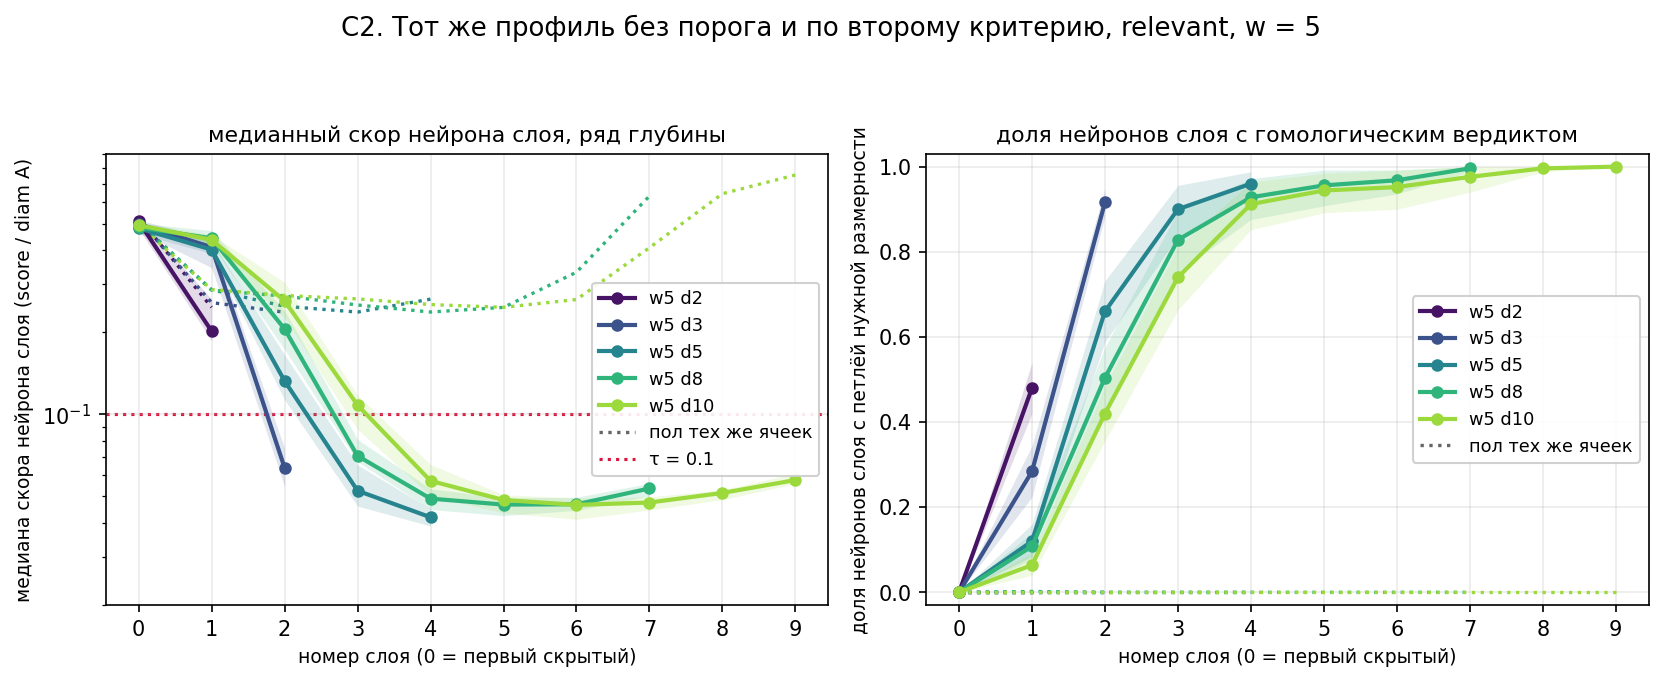

слой:                       0       1       2       3       4       5       6       7
d = 8, структурная доля:    0.000   0.016   0.212   0.676   0.860   0.944   0.948   0.964
d = 8, медианный скор  :    0.484   0.442   0.205   0.070   0.049   0.047   0.047   0.053
d = 8, гомологическая д.:    0.000   0.108   0.504   0.828   0.928   0.956   0.968   0.996

d = 5, структурная против гомологической доли по слоям:
  слой 0: структурная 0.000, гомологическая 0.000, опережение +0.000
  слой 1: структурная 0.012, гомологическая 0.120, опережение +0.108
  слой 2: структурная 0.328, гомологическая 0.660, опережение +0.332
  слой 3: структурная 0.816, гомологическая 0.900, опережение +0.084
  слой 4: структурная 0.940, гомологическая 0.960, опережение +0.020


In [27]:
ap.plot_layer_profiles([
    dict(title="медианный скор нейрона слоя, ряд глубины", profile=prof_depth,
         floor=floor_depth, x="layer_id", by="depth", value="median_score",
         ylabel="медиана скора нейрона слоя (score / diam A)",
         log_y=True, ylim=(0.02, 0.9), hline=(aw.TAU, "τ = 0.1")),
    dict(title="доля нейронов слоя с гомологическим вердиктом", profile=prof_depth,
         floor=floor_depth, x="layer_id", by="depth", value="hom_fraction",
         ylabel="доля нейронов слоя с петлёй нужной размерности"),
], suptitle="C2. Тот же профиль без порога и по второму критерию, relevant, w = 5",
   save_path=FIG / "C2_score_and_homology.png")
show(FIG / "C2_score_and_homology.png")

print("слой:                " + "".join(f"{l:>8d}" for l in range(8)))
for name, col in (("структурная доля", "fraction"),
                  ("медианный скор  ", "median_score"),
                  ("гомологическая д.", "hom_fraction")):
    b = prof_depth[prof_depth.depth == 8].sort_values("layer_id")
    print(f"d = 8, {name}: " + "".join(f"{v:8.3f}" for v in b[col]))
b5 = prof_depth[prof_depth.depth == 5].sort_values("layer_id")
print("\nd = 5, структурная против гомологической доли по слоям:")
for r in b5.itertuples():
    print(f"  слой {r.layer_id}: структурная {r.fraction:.3f}, "
          f"гомологическая {r.hom_fraction:.3f}, "
          f"опережение {r.hom_fraction - r.fraction:+.3f}")

### Что видно на C2

**Растёт не хвост, а всё распределение.** Медианный скор нейрона слоя падает у `d = 5` с 0.481 на
слое 0 до 0.042 на слое 4 — то есть на порядок, и медиана уходит ниже `τ` уже на слое 3. Значит доля
свидетелей растёт не потому, что несколько удачных нейронов переползают порог, а потому что
сдвигается вся популяция слоя. Порог `τ` в этой картине ничего не создаёт: он просто отмечает, где
кривая его пересекает.

**Скор на первом скрытом слое сам зависит от глубины, и в ту же сторону.** У `d = 2` медиана на слое
1 равна 0.202, у `d = 3, 5, 8, 10` — 0.410, 0.401, 0.442, 0.436. Мелкая сеть не просто чаще переходит
порог на раннем слое, она там в среднем **ближе к окружности**. Это та же нехватка запаса по глубине,
но измеренная без порога.

**Гомологический критерий устойчиво опережает структурный на один слой.** При `d = 5`:

| слой | структурная доля | гомологическая доля | опережение |
|---|---|---|---|
| 1 | 0.012 | 0.120 | +0.108 |
| 2 | 0.328 | 0.660 | +0.332 |
| 3 | 0.816 | 0.900 | +0.084 |
| 4 | 0.940 | 0.960 | +0.020 |

Читается это так: **замкнутая линия уровня появляется раньше, чем она становится окружностью.** На
слое 2 петля есть у двух третей нейронов, а обводит целевую окружность только у трети. Разрыв
максимален ровно на переломе и почти исчезает у выхода.

**А на последних слоях два критерия расходятся, и это самое интересное здесь.** У `d = 10`
структурная доля к концу идёт вниз (0.960 → 0.956 → 0.932), а гомологическая — **строго вверх до
самой единицы**: 0.976 → 0.996 → 1.000. То же и у `d = 8`: 0.968 → 0.996 при структурной 0.948 →
0.964. Ни при одной глубине гомологическая кривая не спадает нигде.

Значит замкнутые линии уровня на последних слоях **не исчезают — их становится только больше**.
Меняется их геометрия: они перестают быть похожими на нашу окружность. Правдоподобное прочтение
такое: на ранних слоях линия уровня не похожа на `A` потому, что нейрону не хватает выразительности,
на средних она в `A` попадает, а на последних сеть продолжает оптимизировать уже решённую задачу и
приходит к чему-то, что решает её не хуже, но геометрически от окружности отличается. Это
**гипотеза**: данные показывают расхождение двух критериев, а чем именно стала линия уровня, здесь
не измеряется.

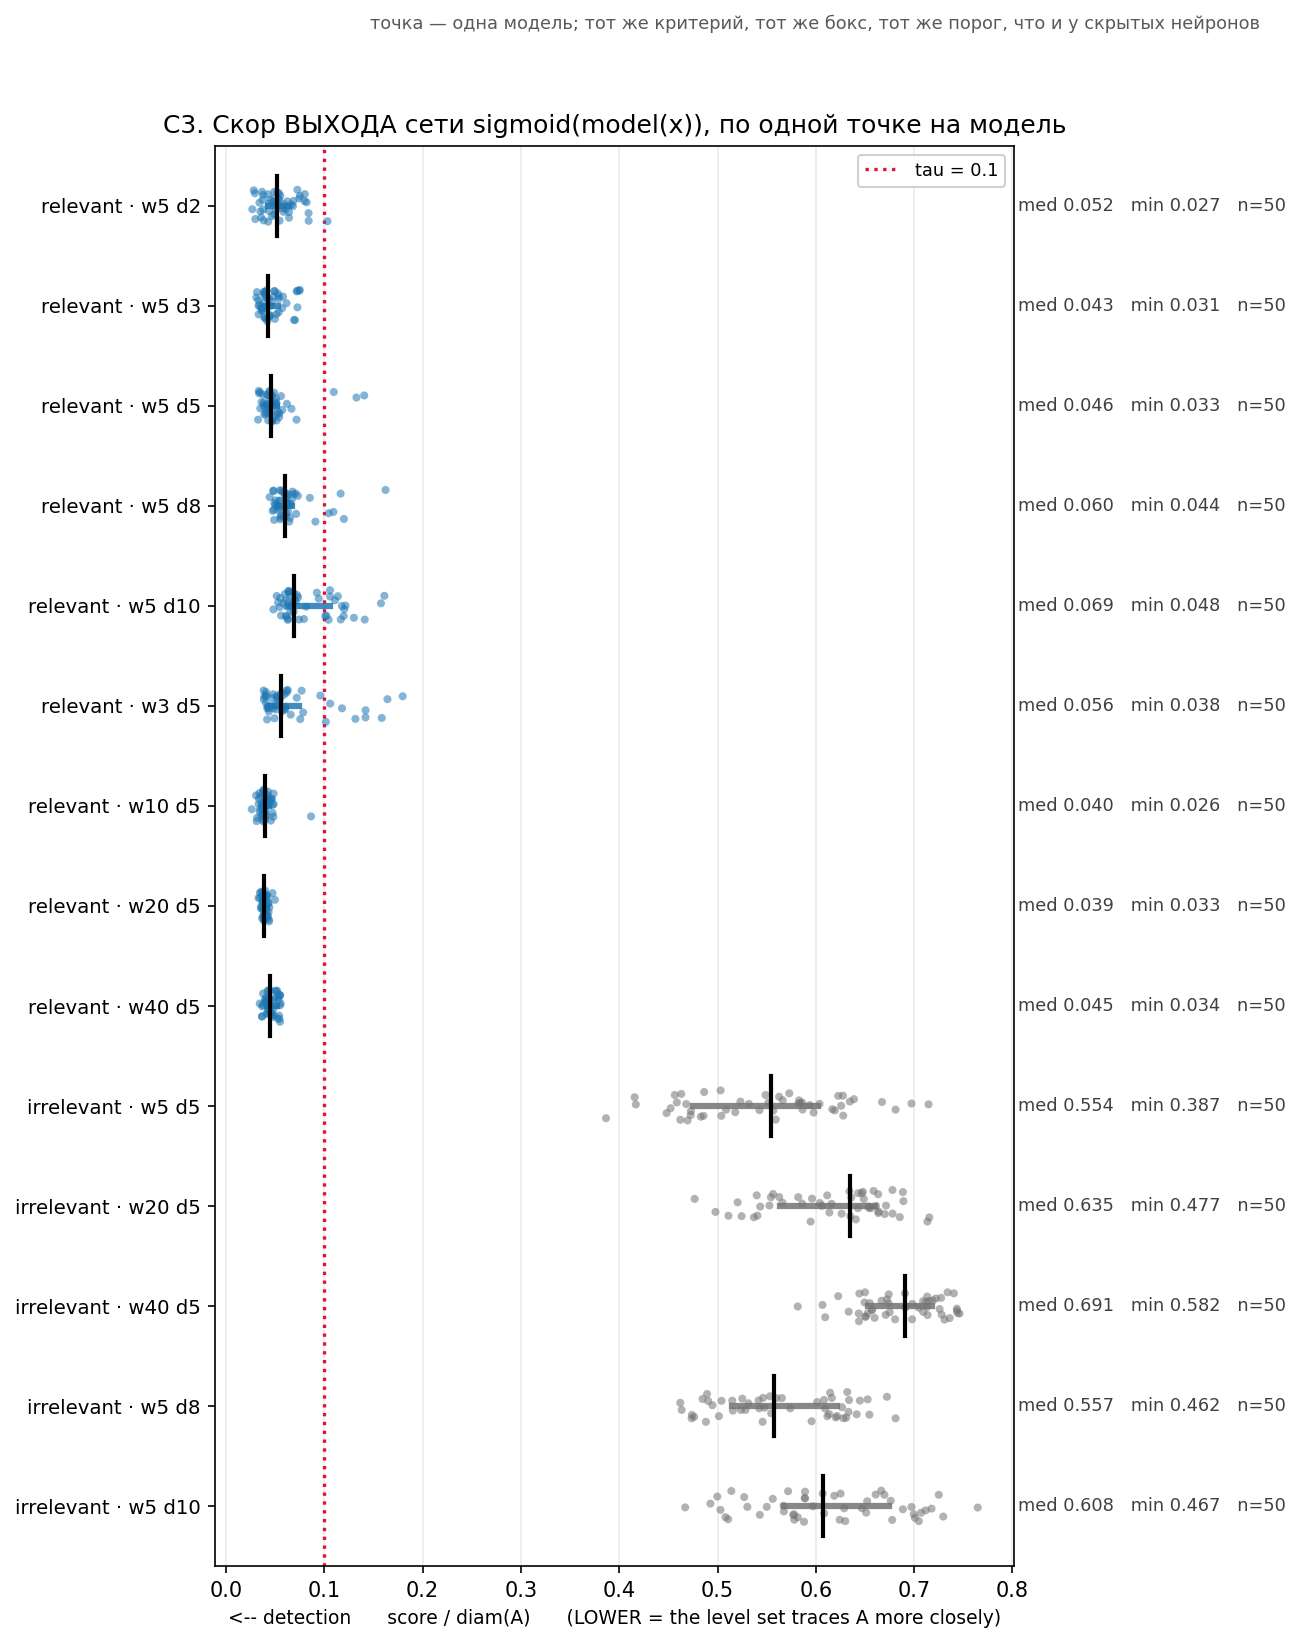

доля моделей со свидетельствующей головой, % — выбор шкалы выхода (там, где посчитаны обе, 10 ячеек):


output,dataset_type,arch,logit,prob
0,simple_irrelevant,w20 d5,0.0,0.0
1,simple_irrelevant,w5 d5,0.0,0.0
2,simple_irrelevant,w5 d8,0.0,0.0
3,simple_relevant,w10 d5,100.0,100.0
4,simple_relevant,w20 d5,100.0,100.0
5,simple_relevant,w3 d5,84.0,82.0
6,simple_relevant,w5 d2,98.0,98.0
7,simple_relevant,w5 d3,100.0,100.0
8,simple_relevant,w5 d5,96.0,94.0
9,simple_relevant,w5 d8,96.0,90.0



промахи головы на relevant: 34 из 450, скоры 0.101–0.180; медиана попавших 0.0467
  по ячейкам: w3 d5 9, w5 d10 16, w5 d2 1, w5 d5 3, w5 d8 5
лучший выход на irrelevant: 0.387 из 250 моделей


In [28]:
# Голова сети. Скрытые нейроны оцениваются ПОСЛЕ нелинейности (kind="post");
# собственная нелинейность головы — сигмоида, которую применяет функция потерь
# (обучение предсказывает sigmoid(logit) > 0.5). Поэтому голова берётся как
# sigmoid(model(x)) — ровно та функция в (0, 1), которой сеть и является как
# классификатор. Пара секунд на модель, поэтому результат кэшируется.
HEAD_CACHE = AGG / "head_scores.csv"
IRR_HEAD_CELLS = [(5, 5), (20, 5), (40, 5), (5, 8), (5, 10)]
heads_rel = aw.head_scores(df, REL, ALL_C, ES, cache=HEAD_CACHE,
                           output="prob", verbose=False)
heads_irr = aw.head_scores(df, IRR, IRR_HEAD_CELLS, ES, cache=HEAD_CACHE,
                           output="prob", verbose=False)
heads = pd.concat([heads_rel, heads_irr], ignore_index=True)

head_units = heads.assign(criterion="structural", feature="head",
                          dataset=heads.dataset_type)
groups = ([(f"relevant · {a}", {"dataset": REL, "arch": a}, "tab:blue")
           for a in [f"w{w} d{d}" for w, d in ALL_C]]
          + [(f"irrelevant · {a}", {"dataset": IRR, "arch": a}, "0.45")
             for a in [f"w{w} d{d}" for w, d in IRR_HEAD_CELLS]])
plot_unit_strips(head_units, "structural", groups, threshold=aw.TAU,
                 title="C3. Скор ВЫХОДА сети sigmoid(model(x)), по одной точке на модель",
                 caption="точка — одна модель; тот же критерий, тот же бокс, тот же порог, "
                         "что и у скрытых нейронов",
                 save_path=FIG / "C3_head.png")
show(FIG / "C3_head.png")

# Проверка, что вердикт не создан выбором шкалы: сигмоида строго монотонна, поэтому
# линии уровня у sigmoid(model(x)) и у сырого логита СОВПАДАЮТ как множества, и
# различаться может только то, какие уровни попадают в скан из 101 штуки.
stored = pd.read_csv(HEAD_CACHE)
if "output" in stored and (stored.output == "logit").any():
    both = (stored.pivot_table(index=["dataset_type", "arch"], columns="output",
                               values="witness", aggfunc="mean") * 100).round(1)
    both = both.dropna()          # логит считался не для всех ячеек
    print(f"доля моделей со свидетельствующей головой, % — выбор шкалы выхода "
          f"(там, где посчитаны обе, {len(both)} ячеек):")
    display(both.reset_index())

misses = heads[(heads.dataset_type == REL) & ~heads.witness]
hits = heads[(heads.dataset_type == REL) & heads.witness]
print(f"\nпромахи головы на relevant: {len(misses)} из {len(heads[heads.dataset_type == REL])}, "
      f"скоры {misses.score.min():.3f}–{misses.score.max():.3f}; "
      f"медиана попавших {hits.score.median():.4f}")
print("  по ячейкам: " + ", ".join(
    f"{a} {int((~g.witness).sum())}" for a, g in
    heads[heads.dataset_type == REL].groupby("arch") if (~g.witness).any()))
print(f"лучший выход на irrelevant: {heads[heads.dataset_type == IRR].score.min():.3f} "
      f"из {len(heads[heads.dataset_type == IRR])} моделей")

### Что видно на C3

**Оба предсказания подтвердились, и разделение не пограничное.** На `simple_relevant` выход
свидетельствует окружность у **68–100 %** моделей, на `simple_irrelevant` — **у нуля моделей из
двухсот пятидесяти**, причём лучший из этих двухсот пятидесяти выходов набирает **0.387** при пороге
0.1. Между двумя облаками на фигуре нет ни одной точки: худший релевантный выход — 0.180, лучший
нерелевантный — 0.387. Это не тавтология, а измерение того, что и должно было получиться: у
релевантного датасета граница решения и есть окружность, у нерелевантного она проходит в другом
месте.

**Выбор шкалы вердикт не создаёт.** Там, где посчитаны обе версии, сигмоидная и логитная дают
одинаковую долю в семи ячейках из десяти и расходятся не более чем на три модели из пятидесяти в
остальных. Ни один вывод ниже от этого не зависит, и это ожидаемо: линии уровня у двух полей
совпадают, различается только сетка сканируемых уровней. Дальше везде используется сигмоидная версия
как прямой аналог `kind="post"` у скрытого нейрона.

**Промахи головы — пограничные, а не качественные.** Все тридцать четыре модели из четырёхсот
пятидесяти, чей выход не прошёл `τ`, лежат в диапазоне 0.101–0.180, при медиане попавших 0.047 и поле
пункта B в 0.13–0.18. То есть «голова не свидетельствует» здесь означает «обводит окружность с
точностью 0.10–0.18 вместо 0.10», а не «обводит что-то другое».

Правдоподобная причина — **граница решения совпадает с окружностью только там, где есть данные.** В
пустых частях бокса линию уровня не держит ничто, и лишний кусок, ушедший в пустоту, штрафуется
критерием наравне с остальным. Это интерпретация; проверять её надо сравнением скора в боксе и в
выпуклой оболочке данных, чего здесь не делается.

**Слабые ячейки стоят на двух концах оси глубины и на минимуме ширины.** Меньше всего голова
свидетельствует при **`w5 d10` (68 %, 16 промахов)**, затем при `w3 d5` (82 %, 9 промахов) и
`w5 d8` (90 %). Широкие сети дают 100 % — включая `w40 d5`. Первое согласуется с тем, что после пяти
слоёв качество перестаёт расти (B4), второе — с тем, что `w3 d5` худшая ячейка по всем величинам
сразу. **Лишняя глубина выход не улучшает, а понемногу портит.**

---

### C4. Описывает ли профили одна кривая

Сравнивать пять ломаных с разным числом звеньев «в среднем по совпадающим позициям» некорректно:
у кривых разной глубины разные области определения, и любое такое усреднение зависит больше от того,
какие позиции попали в пересечение, чем от самих кривых. Нужна координата, в которой у всех кривых
**общая область определения и общие концы**.

Такая координата теперь есть: голова из C3 встаёт последним слоем, позиция нормируется как `l / d`,
первый скрытый слой попадает в 0, голова — в 1. Все кривые начинаются в `(0, 0)`, потому что на
первом скрытом слое замкнутая линия уровня невозможна по теореме, и заканчиваются в точке головы.

**Что на фигуре.** Только **ряд глубины при `w = 5`** — пять кривых, `d = 2, 3, 5, 8, 10`. Ячейки
ряда ширины сюда не входят: у всех глубина 5, и на общей оси они дали бы несколько разных точек в
одном и том же `x`. Слева позиция нормирована на глубину, справа та же кривая по абсолютному номеру
слоя; горизонталь — уровень 0.5, по которому дальше считается полувысота.

**Вопрос ровно один:** ложатся ли кривые на одну общую S-образную кривую — то есть является ли
профиль функцией относительного положения в сети, а глубина просто шагом дискретизации.

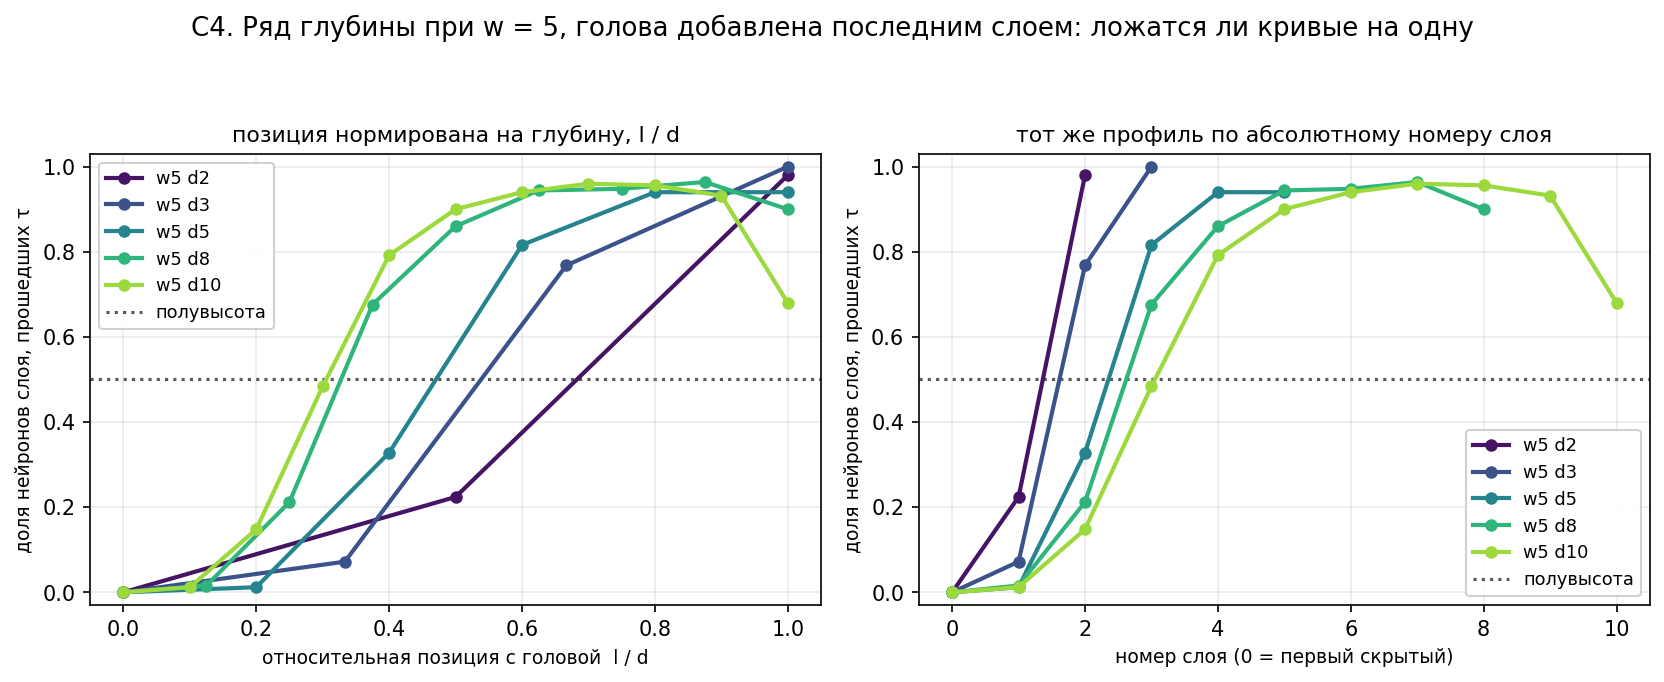

полувысота — где кривая пересекает 0.5:
  d = 2: слой 1.37, относительная позиция 0.68, слой / √d = 0.97
  d = 3: слой 1.61, относительная позиция 0.54, слой / √d = 0.93
  d = 5: слой 2.35, относительная позиция 0.47, слой / √d = 1.05
  d = 8: слой 2.62, относительная позиция 0.33, слой / √d = 0.93
  d = 10: слой 3.05, относительная позиция 0.31, слой / √d = 0.97

разброс между глубинами (обе координаты теперь с общими концами):
  по относительной позиции: 0.332
  по номеру слоя (0…2):     0.348


In [29]:
# Голова встаёт последним слоем ряда ГЛУБИНЫ при w = 5: позиция l / d, первый
# скрытый слой в 0, голова в 1. Ячейки ряда ширины сюда не входят — у них та же
# глубина 5, и на общей оси они дали бы несколько разных точек в одном x.
head_points = (heads_rel[heads_rel.width == 5]
               .groupby(["arch", "width", "depth"])
               .agg(fraction=("witness", "mean")).reset_index())
head_points["layer_id"] = head_points["depth"]
head_points["rel_pos_head"] = 1.0
COLS = ["arch", "width", "depth", "layer_id", "rel_pos_head", "fraction"]
with_head = pd.concat([prof_depth[COLS], head_points[COLS]],
                      ignore_index=True).sort_values(["depth", "layer_id"])
with_head.to_csv(AGG / "layer_profile_with_head.csv", index=False)

ap.plot_layer_profiles([
    dict(title="позиция нормирована на глубину, l / d", profile=with_head,
         x="rel_pos_head", by="depth", hline=(0.5, "полувысота"), hline_colour="0.35"),
    dict(title="тот же профиль по абсолютному номеру слоя", profile=with_head,
         x="layer_id", by="depth", hline=(0.5, "полувысота"), hline_colour="0.35"),
], suptitle="C4. Ряд глубины при w = 5, голова добавлена последним слоем: "
            "ложатся ли кривые на одну",
   save_path=FIG / "C4_profile_with_head.png")
show(FIG / "C4_profile_with_head.png")

print("полувысота — где кривая пересекает 0.5:")
half = []
for d, g in with_head.groupby("depth"):
    x, y = g.layer_id.to_numpy(float), g.fraction.to_numpy(float)
    lay = float(np.interp(0.5, y, x))
    rel = float(np.interp(0.5, y, g.rel_pos_head.to_numpy(float)))
    half.append({"depth": int(d), "half_rise_layer": lay, "half_rise_rel": rel,
                 "layer_over_sqrt_depth": lay / np.sqrt(d)})
    print(f"  d = {d}: слой {lay:.2f}, относительная позиция {rel:.2f}, "
          f"слой / √d = {lay / np.sqrt(d):.2f}")
pd.DataFrame(half).to_csv(AGG / "half_rise.csv", index=False)

grid = np.linspace(0, 1, 21)
rel_spread = np.array([np.interp(grid, g.rel_pos_head, g.fraction)
                       for _, g in with_head.groupby("depth")])
abs_common = np.array([[float(np.interp(k, g.layer_id, g.fraction)) for k in (0, 1, 2)]
                       for _, g in with_head.groupby("depth")])
print(f"\nразброс между глубинами (обе координаты теперь с общими концами):")
print(f"  по относительной позиции: {(rel_spread.max(0) - rel_spread.min(0)).mean():.3f}")
print(f"  по номеру слоя (0…2):     {(abs_common.max(0) - abs_common.min(0)).mean():.3f}")

### Что видно на C4

**Кривые на одну не ложатся — ни в одной координате.** Теперь это сравнение законное: у всех пяти
кривых общая область определения и общие концы. Разброс между глубинами: **0.332** по относительной
позиции и **0.348** по номеру слоя. Обе величины большие, и относительная выигрывает лишь чуть-чуть.

**Порядок кривых в двух координатах противоположный, и оба верны.** По номеру слоя мелкая сеть
впереди (на слое 1: 0.224 при `d = 2` против 0.012 при `d = 10`). По относительной позиции —
наоборот, глубокая (в точке 0.5: 0.900 при `d = 10` против 0.224 при `d = 2`). Противоречия нет: у
мелкой сети нет запаса и она обязана начать сразу, но к своей середине она успевает пройти всего
одно преобразование, а глубокая — пять.

**Полувысота — та величина, которая это мирит.** Точка, где профиль пересекает 0.5:

| глубина | 2 | 3 | 5 | 8 | 10 |
|---|---|---|---|---|---|
| номер слоя | 1.37 | 1.61 | 2.35 | 2.62 | **3.05** |
| относительная позиция | 0.68 | 0.54 | 0.47 | 0.33 | **0.31** |
| **слой / √d** | 0.97 | 0.93 | 1.05 | 0.93 | **0.97** |

Ни то, ни другое не постоянно: при пятикратном росте глубины абсолютная полувысота растёт в 2.2 раза,
а относительная падает в 2.2 раза — симметрично, то есть истина ровно посередине. Посередине между
«постоянный слой» и «постоянная доля» лежит **корень**, и пять измерений с ним согласуются:
`слой / √d` держится в пределах 0.93–1.05.

**Правило проверено вне того диапазона, на котором замечено.** Если оценивать его по четырём
глубинам до восьмой, то `d = 10` предсказывает полувысоту на слое `√10 ≈ 3.16`; наблюдается **3.05**,
и новая точка ложится внутрь прежнего разброса, ничего не расширив. Пяти точек всё ещё мало, чтобы
называть это законом, но подгонкой к имеющимся данным оно уже не является.

**Практическое следствие для всего эксперимента.** Утверждения вида «на слое 2 доля такая-то»
переносятся только внутри одной глубины. Профиль эксперимента 1, снятый при `d = 5`, к сетям другой
глубины не применим — и это ровно та проверка, ради которой существовал отдельный пункт E.

---

### C5. Сколько нейронов одного слоя свидетельствуют окружность

Вопрос, перенесённый из B, где он стоял как «один нейрон на всю сеть» и в такой форме противоречив:
если свидетель единственный и сидит на слое `l`, то глубже признака нет и голова им не пользуется.
Здесь он поставлен шире и без гипотезы: **как устроено число свидетелей внутри слоя и что с ним
происходит при переходе к следующему слою.**

Датасет — **`simple_relevant`**; на `simple_irrelevant` считать нечего, там свидетелей четыре на весь
пул и все четыре разобраны в A. Слой 0 и ширины ≤ 2 исключены: замкнутая линия уровня там невозможна
по теореме, и ноль был бы тождеством, а не измерением.

**Что на картинке, построчно.** Одна панель — одна архитектура. **Строка — слой. Столбец — сколько
нейронов этого слоя прошли `τ`**, от нуля слева до всего слоя справа. **Цвет клетки — доля моделей**
(из пятидесяти), у которых в этом слое оказалось ровно столько свидетелей; в клетках подписаны
проценты, где панель это позволяет. Каждая строка суммируется в единицу, поэтому строки сравнимы
между собой, хотя слои свидетельствуют по-разному часто.

**Почему построчно, а не одной гистограммой на архитектуру.** Сложенные вместе слои дают бимодальную
кашу, у которой моды принадлежат **разным строкам**; по такой картинке нельзя сказать ничего, кроме
того, что бывает и пусто, и полно. Разложение по строкам показывает, какая мода откуда и что стоит
между ними.

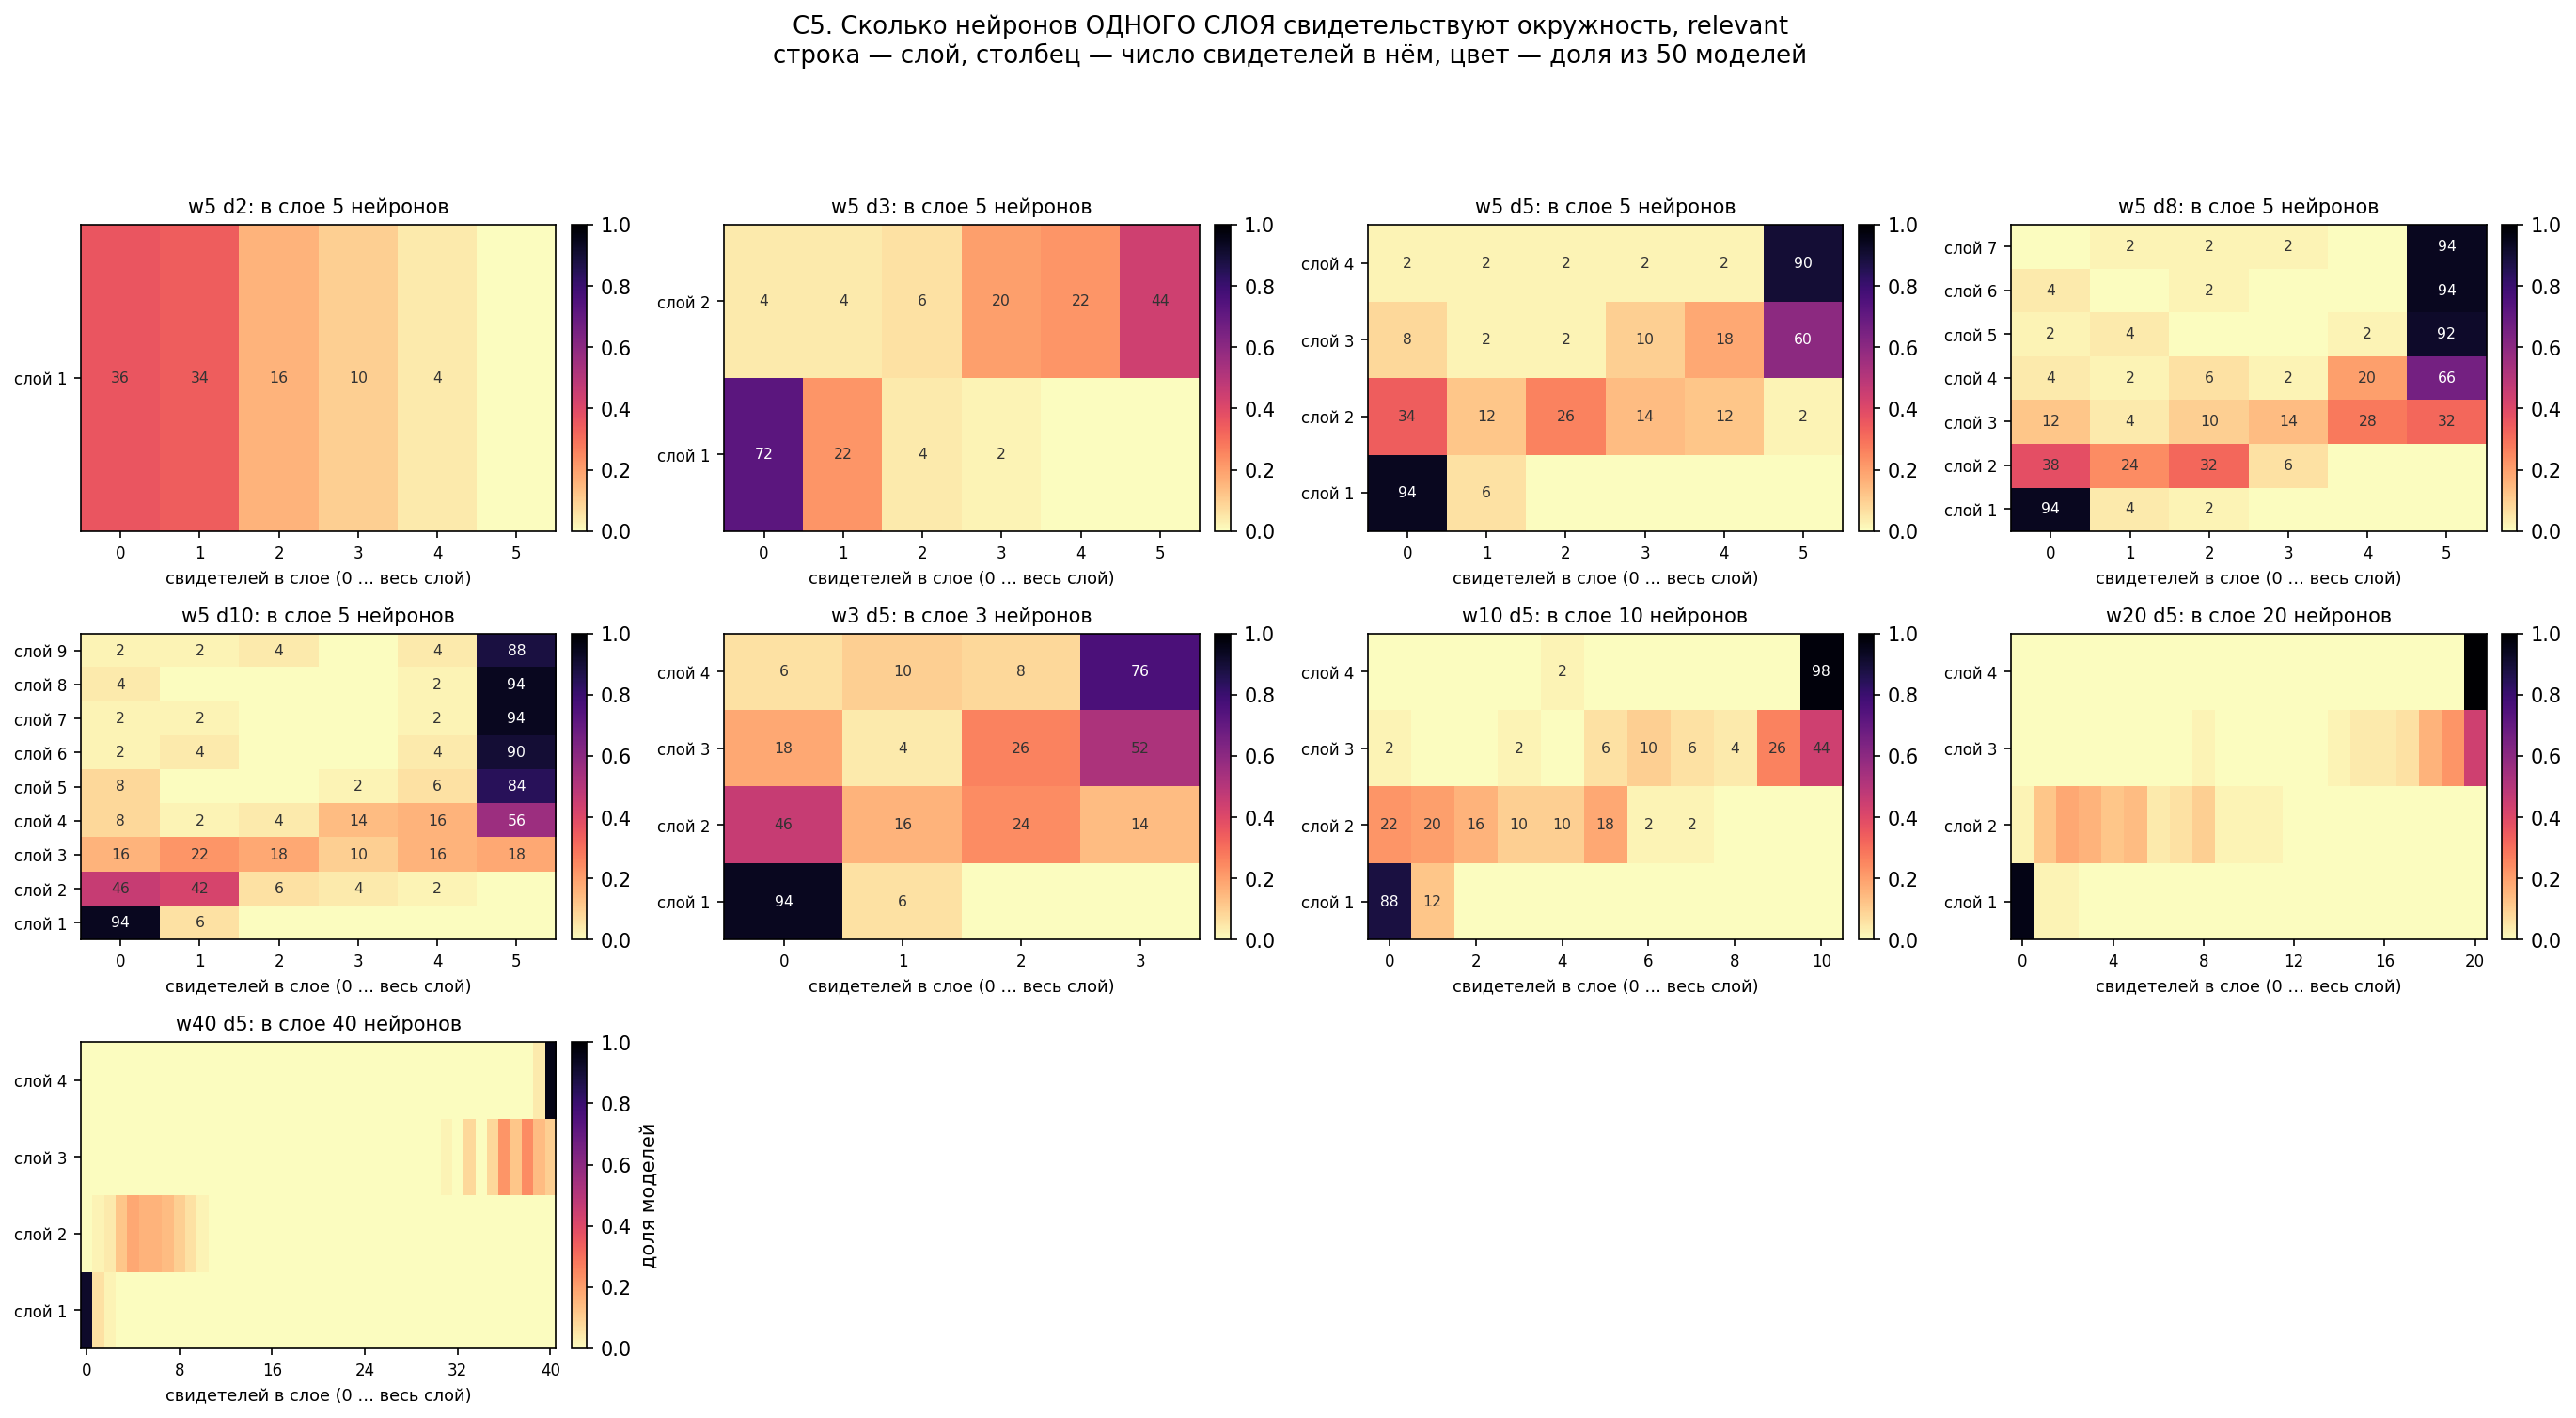

ряд глубины при w = 5, доля моделей с ПУСТЫМ слоем → с ПОЛНЫМ слоем, по слоям:
  w5 d2:  пусто 0.36
          полон 0.00
  w5 d3:  пусто 0.72 0.04
          полон 0.00 0.44
  w5 d5:  пусто 0.94 0.34 0.08 0.02
          полон 0.00 0.02 0.60 0.90
  w5 d8:  пусто 0.94 0.38 0.12 0.04 0.02 0.04 0.00
          полон 0.00 0.00 0.32 0.66 0.92 0.94 0.94
  w5 d10:  пусто 0.94 0.46 0.16 0.08 0.08 0.02 0.02 0.04 0.02
          полон 0.00 0.00 0.18 0.56 0.84 0.90 0.94 0.94 0.88

доля пар (модель, слой) с РОВНО ОДНИМ свидетелем:
  w5 d2  : 0.340
  w5 d3  : 0.130
  w5 d5  : 0.055
  w5 d8  : 0.057
  w5 d10 : 0.089
  w3 d5  : 0.090
  w10 d5 : 0.080
  w20 d5 : 0.035
  w40 d5 : 0.020

медиана числа свидетелей в слое, по архитектурам:
  w5 d2   (ширина  5): 1
  w5 d3   (ширина  5): 0 4
  w5 d5   (ширина  5): 0 2 5 5
  w5 d8   (ширина  5): 0 1 4 5 5 5 5
  w5 d10  (ширина  5): 0 1 2 5 5 5 5 5 5
  w3 d5   (ширина  3): 0 1 3 3
  w10 d5  (ширина 10): 0 2 9 10
  w20 d5  (ширина 20): 0 4 19 20
  w40 d5  (ширина 

In [30]:
# Датасет здесь и до конца пункта — simple_relevant. На simple_irrelevant считать
# нечего: свидетелей там четыре на весь пул, и все четыре разобраны в A.
lc = aw.layer_counts(df, REL, ALL_C)
lc.to_csv(AGG / "layer_witness_counts.csv", index=False)

ap.plot_layer_multiplicity(lc, [f"w{w} d{d}" for w, d in ALL_C], ncols=4,
    title="C5. Сколько нейронов ОДНОГО СЛОЯ свидетельствуют окружность, relevant\n"
          "строка — слой, столбец — число свидетелей в нём, цвет — доля из 50 моделей",
    save_path=FIG / "C5_layer_multiplicity.png")
show(FIG / "C5_layer_multiplicity.png")

print("ряд глубины при w = 5, доля моделей с ПУСТЫМ слоем → с ПОЛНЫМ слоем, по слоям:")
for w, d in D_ROW_C:
    b = lc[lc.arch == f"w{w} d{d}"]
    empty = [f"{(g['count'] == 0).mean():.2f}" for _, g in b.groupby("layer_id")]
    full = [f"{(g['count'] == w).mean():.2f}" for _, g in b.groupby("layer_id")]
    print(f"  w{w} d{d}:  пусто {' '.join(empty)}\n"
          f"          полон {' '.join(full)}")

print("\nдоля пар (модель, слой) с РОВНО ОДНИМ свидетелем:")
for arch in [f"w{w} d{d}" for w, d in ALL_C]:
    b = lc[lc.arch == arch]
    print(f"  {arch:7s}: {(b['count'] == 1).mean():.3f}")

print("\nмедиана числа свидетелей в слое, по архитектурам:")
for arch in [f"w{w} d{d}" for w, d in ALL_C]:
    b = lc[lc.arch == arch]
    med = [f"{g['count'].median():.0f}" for _, g in b.groupby("layer_id")]
    print(f"  {arch:7s} (ширина {int(b.width.iat[0]):2d}): {' '.join(med)}")

### Что видно на C5

**От слоя к слою распределение перетекает слева направо.** Ранний слой пуст почти у всех моделей,
поздний почти у всех полон, а между ними стоит слой с широко размазанным числом свидетелей. У
`w40 d5` это видно лучше всего: слой 1 пуст почти у всех моделей, в слое 2 медиана 5 из сорока, слой
3 даёт медиану 37, слой 4 — **все сорок**. Внутри каждой отдельной строки мода одна; бимодальным
выглядит только результат сложения строк, и именно поэтому пулированная гистограмма здесь бесполезна.

**Перетекание имеет собственную длину, и у глубоких сетей оно кончается на середине.** Доля моделей,
у которых слой полон, по слоям:

| | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| `w5 d5` | 0.00 | 0.02 | 0.60 | 0.90 | | | | | |
| `w5 d8` | 0.00 | 0.00 | 0.32 | 0.66 | **0.92** | **0.94** | **0.94** | | |
| `w5 d10` | 0.00 | 0.00 | 0.18 | 0.56 | 0.84 | 0.90 | **0.94** | **0.94** | **0.88** |

У `d = 5` процесс идёт до самого последнего скрытого слоя. У `d = 8` он заканчивается на слое 5, у
`d = 10` — на слое 6–7, и дальше не просто останавливается, а **разворачивается**: на последнем слое
полных моделей становится меньше (0.94 → 0.88).

**Это не потолок измерения.** Доля «слой полон» упирается в единицу и могла бы замереть просто
поэтому — но беспороговая величина из C2 ведёт себя так же: медианный скор нейрона слоя у `w5 d10`
идёт 0.108 → 0.057 → 0.049 → 0.047 → 0.048 → **0.052 → 0.057**, то есть перестаёт улучшаться после
пятого слоя и на двух последних портится. Замирает не линейка, а сам процесс.

**Что это говорит о задаче.** Построение окружности стоит сети примерно **четыре преобразования** —
и это свойство задачи, а не глубины сети. Если слоёв ровно столько, признак собирается до последнего
слоя; если больше, он собирается за те же четыре, а оставшиеся слои его **переносят и понемногу
портят**. Лишняя глубина на этот признак не тратится и его не улучшает: качество лучшего нейрона идёт
0.0349 → 0.0410 → 0.0424 при `d = 5, 8, 10`, а голова сети — 94 % → 90 % → **68 %**.

Отсюда же **уточнение к выводу B о глубине**, и оно нетривиальное. Доля свидетелей по всей сети —
это по определению среднее послойных долей: у `d = 5` среднее от `0, 0.012, 0.328, 0.816, 0.940`
равно 0.419, у `d = 8` — 0.578, у `d = 10` — 0.612, и все три совпадают с числами пункта B. Но раз
послойная кривая выходит на полку, у глубокой сети **больше слоёв стоит после того, как построение
закончилось**, и все они входят в среднее близкими к единице. Значит глубина поднимает долю не
потому, что признак выделяется лучше, а потому, что дольше держится. Утверждение B «глубина сильнее
ширины» остаётся верным как измерение и меняет смысл: это утверждение о **протяжённости** признака в
сети, а не о его качестве.

**Кратность у выхода читать как «сорок независимых кодировщиков» нельзя.** У `simple_relevant`
граница решения и есть окружность, а последний скрытый слой обязан быть почти линейно разделим, то
есть каждый его нейрон близок к самой решающей функции — а её линия уровня и есть цель. Полнота
последнего слоя поэтому почти вынуждена задачей. Содержательная кратность — та, что на переломе, где
такого принуждения нет.

---

### C6. Монотонность внутри модели и непрерывность как фильтр ложных срабатываний

Два вопроса одной природы: оба спрашивают не «сколько свидетелей на слое `l`», а **что происходит с
признаком при переходе к следующему слою**, и оба считаются по одной модели за раз.

**Первый — монотонность.** Все кривые выше усреднены по ансамблю, а средняя кривая может расти и в
том случае, когда у половины моделей есть провал. Поэтому печатается доля моделей, у которых число
свидетелей не падает **ни разу** при переходе к следующему слою, и худший провал.

**Второй — фильтр.** Выход сети собирается из **последнего** скрытого слоя. Если признак выделен на
слое `l`, а ни один более глубокий слой его не несёт, то голова читать его там не может — значит эта
роль сети не понадобилась, и такое срабатывание есть **кандидат в ложные**, по основанию, никак не
связанному с `τ`.

**Две версии определения, и обе стоит посчитать.**

* **Без головы.** Свидетель помечается, если в той же модели нет свидетеля ни на одном более глубоком
  скрытом слое **и** он сам не в последнем скрытом слое. Второе условие вынужденное: у свидетеля
  последнего слоя «глубже» ничего нет по построению, и метить его за это было бы ошибкой — но из-за
  этого 41 % свидетелей выпадают из-под фильтра целиком.
* **С головой.** Голова (C3) — тоже слой, и тогда оговорка не нужна: «есть ли свидетель глубже»
  определено для всех слоёв одинаково.

**Как проверяем, что фильтр вообще что-то ловит.** У нас есть множество заведомо сомнительных
срабатываний — четыре нейрона, перешедшие `τ` на **нерелевантной** окружности (пункт A), — и
множество, считать ложным которое оснований нет: свидетели релевантной окружности. Хороший фильтр
должен их разделять.

In [31]:
# Сначала монотонность: растёт ли профиль ВНУТРИ модели, а не только в среднем.
mono = aw.profile_monotonicity(df, REL, ALL_C)
mono.to_csv(AGG / "profile_monotonicity.csv", index=False)
print("число свидетелей ни разу не падает при переходе к следующему слою:")
for r in mono.itertuples():
    print(f"  {r.arch:7s}: {r.monotone_share:5.0%} моделей, худший провал {r.worst_drop}")

# Дальше фильтр. Обе версии считаются на ОДНОМ множестве ячеек — тех, где измерена
# голова. Иначе версия «с головой» пометила бы всё, чего просто не посчитали.
scope = {REL: [f"w{w} d{d}" for w, d in ALL_C],
         IRR: [f"w{w} d{d}" for w, d in IRR_HEAD_CELLS]}

parts = []
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    f = aw.continuity_filter(df, ds)
    f = f[f.arch.isin(scope[ds])]
    if len(f):
        parts.append(f.assign(dataset=name))
filt = pd.concat(parts, ignore_index=True)

# С головой у последнего скрытого слоя «глубже» наконец определено.
head_witness = heads.set_index("model_path")["witness"]
filt["head_witnesses"] = filt["model_path"].map(head_witness)
assert filt["head_witnesses"].notna().all(), "голова посчитана не для всех моделей области"
filt["flagged_with_head"] = np.where(filt["is_last_layer"],
                                     ~filt["head_witnesses"], filt["flagged"])
filt.to_csv(AGG / "continuity_filter.csv", index=False)

summary = (filt.groupby(["dataset", "arch"])
           .agg(свидетелей=("flagged", "size"), помечено=("flagged", "sum"),
                доля=("flagged", "mean"),
                с_головой=("flagged_with_head", "sum"),
                доля_с_головой=("flagged_with_head", "mean"))
           .reset_index())
summary.to_csv(AGG / "continuity_filter_rates.csv", index=False)
print()
for name, g in filt.groupby("dataset"):
    print(f"{name:11s}: свидетелей {len(g):5d} в {g.arch.nunique()} ячейках; "
          f"помечено без головы {int(g.flagged.sum()):3d} ({g.flagged.mean():.2%}), "
          f"с головой {int(g.flagged_with_head.sum()):3d} "
          f"({g.flagged_with_head.mean():.2%}); "
          f"в последнем скрытом слое {g.is_last_layer.mean():.1%}")
print()
display(summary[summary["помечено"] + summary["с_головой"] > 0])

print("все помеченные (версия без головы) поимённо:")
flagged = filt[filt.flagged].copy()
flagged["модель"] = flagged.model_path.str.split("_").str[-1]
display(flagged[["dataset", "arch", "модель", "layer_id", "coord_id", "score",
                 "deepest_witness_layer", "head_witnesses"]]
        .sort_values(["dataset", "arch", "layer_id"]))

число свидетелей ни разу не падает при переходе к следующему слою:
  w5 d2  :  100% моделей, худший провал 0
  w5 d3  :  100% моделей, худший провал 0
  w5 d5  :  100% моделей, худший провал 0
  w5 d8  :   96% моделей, худший провал 1
  w5 d10 :   82% моделей, худший провал 3
  w3 d5  :   98% моделей, худший провал 3
  w10 d5 :  100% моделей, худший провал 0
  w20 d5 :  100% моделей, худший провал 0
  w40 d5 :  100% моделей, худший провал 0

irrelevant : свидетелей     7 в 2 ячейках; помечено без головы   7 (100.00%), с головой   7 (100.00%); в последнем скрытом слое 0.0%
relevant   : свидетелей 11073 в 9 ячейках; помечено без головы   4 (0.04%), с головой 100 (0.90%); в последнем скрытом слое 41.3%



,dataset,arch,свидетелей,помечено,доля,с_головой,доля_с_головой
0,irrelevant,w20 d5,4,4,1.000000,4,1.000000
1,irrelevant,w40 d5,3,3,1.000000,3,1.000000
4,relevant,w3 d5,289,3,0.010381,13,0.044983
6,relevant,w5 d10,1531,1,0.000653,64,0.041803
7,relevant,w5 d2,56,0,0.000000,1,0.017857
9,relevant,w5 d5,524,0,0.000000,4,0.007634
10,relevant,w5 d8,1155,0,0.000000,18,0.015584


все помеченные (версия без головы) поимённо:


,dataset,arch,модель,layer_id,coord_id,score,deepest_witness_layer,head_witnesses
11074,irrelevant,w20 d5,model18,1,13,0.091127,1,False
11075,irrelevant,w20 d5,model40,1,11,0.091215,1,False
11076,irrelevant,w20 d5,model42,1,12,0.078018,1,False
11073,irrelevant,w20 d5,model17,2,14,0.093922,2,False
11077,irrelevant,w40 d5,model1,1,38,0.098821,1,False
11078,irrelevant,w40 d5,model20,1,28,0.082603,1,False
11079,irrelevant,w40 d5,model24,1,31,0.082174,1,False
3400,relevant,w3 d5,model43,3,0,0.085992,3,False
3401,relevant,w3 d5,model43,3,1,0.091961,3,False
3402,relevant,w3 d5,model43,3,2,0.092259,3,False


### Что видно на C6

**Профиль растёт не только в среднем, но и внутри модели — кроме самой глубокой сети.** Число
свидетелей не падает ни разу при переходе к следующему слою у **100 %** моделей при `d = 2, 3, 5` и
при `w = 10, 20, 40`. Исключения: 98 % при `w3 d5` (худший провал три нейрона), 96 % при `w5 d8`
(провал один) и **82 % при `w5 d10`** (провал три). То есть у каждой шестой десятислойной модели
признак где-то отступает — и это та же ячейка, чья кривая в C5 к последнему слою разворачивается
вниз. Два независимых способа увидеть одно и то же.

Дальше фильтр. Обе версии считаются на одном множестве — девяти ячейках `relevant` и пяти
`irrelevant`, где измерена голова.

| | свидетелей | помечено без головы | помечено с головой |
|---|---|---|---|
| relevant | 11 073 | **4 (0.04 %)** | 100 (0.90 %) |
| irrelevant (`w20 d5` и `w40 d5`) | 7 | **7 (100 %)** | 7 (100 %) |

**Все семь нерелевантных срабатываний помечены обеими версиями** — включая три новых, которые
добавила `w40 d5`. Все они на первых двух слоях; ни в одной из этих моделей нет свидетеля ни на одном
более глубоком скрытом слое, и голова не свидетельствует ни у одной из ста моделей двух этих ячеек. То есть окружность
выделяется на раннем слое и **дальше никуда не идёт**: сеть её не переносит, потому что для её задачи
она не нужна.

Это третье, независимое основание считать эти четыре срабатывания сомнительными — к тем двум, что
были в A: три компоненты из семи обрезаны боксом, а лучший НУЛЕВОЙ нейрон всего датасета набирает
0.0667 — меньше любого из семи.

**Четыре помеченных на relevant — это два случая на одиннадцать тысяч свидетелей.** Три из них суть
все нейроны слоя 3 модели `w3 d5 model43` со скорами 0.086, 0.092, 0.092: у неё слой 4 не
свидетельствует вовсе, и голова тоже не дотягивает до `τ` (0.106). Четвёртый — одиночный нейрон слоя
6 модели `w5 d10 model12`. Оба случая — модели, которые **выделили окружность и потеряли её**, и оба
стоят там же, где живут остальные аномалии: на минимальной ширине и на максимальной глубине. Ни одной
пометки при ширине пять и выше и глубине до восьми версия без головы не даёт.

**Версия с головой строже, но метит другое.** Она поднимает число с 4 до 100, и **64 из этих ста
приходятся на одну ячейку `w5 d10`** — просто потому, что там голова свидетельствует лишь у 68 %
моделей, и свидетели последнего скрытого слоя у остальных 32 % оказываются помеченными. А из C3
известно, что все такие промахи пограничные: 0.101–0.180 против порога 0.1. То есть версия с головой
в основном отвечает на вопрос «протиснулся ли выход под порог», а не «переносится ли признак дальше».
Разделять наши два множества это ей не мешает — 100 % против 0.9 %, — но как фильтр она смешивает два
разных основания, и дальше стоит пользоваться версией без головы.

**Три оговорки, без которых фильтр нельзя брать в работу.**

1. **Это необходимое условие, а не достаточное.** Признак может быть линейно декодируем из
   последнего слоя, не будучи там ничьей линией уровня. Непомеченный свидетель поэтому не
   «подтверждён» — он лишь не опровергнут этим способом.
2. **Разделение частично тавтологично.** На `simple_irrelevant` голова не свидетельствует ни у одной
   модели — по построению датасета, где граница решения проходит в другом месте. Настоящая проверка
   требует случая, где нерелевантная фича всё-таки получает свидетеля глубоко или у головы; в этом
   пуле такого нет — даже при двухстах нейронах, где срабатывания есть, все они на первых двух слоях.
3. **Тестовое множество — четыре элемента.** Разделение чистое, но объём выборки не позволяет
   говорить о частоте ошибок фильтра.

## Итог по C

Напомню, что здесь называется **профилем**: зависимость характеристики свидетельства от номера
скрытого слоя при фиксированной архитектуре и фиксированной фиче. Характеристик было три — доля
нейронов слоя, прошедших `τ`; медианный скор нейрона слоя; доля нейронов с гомологическим вердиктом.

**1. Признак строится постепенно, от входа к выходу.** Профиль растёт у всех глубин и ширин — кроме
`d = 10`, где на двух последних слоях он идёт вниз (0.960 → 0.956 → 0.932). И это не
артефакт усреднения: внутри модели число свидетелей не падает ни разу у 96–100 % моделей — кроме
`w5 d10`, где таких 82 %. Растёт при этом не хвост, а вся популяция слоя: медианный скор падает на
порядок и уходит ниже `τ` раньше, чем доля достигает половины. У пола и на нерелевантной окружности
профиля нет вовсе (максимум 0.0040 и 0.0030), так что это не общее свойство «глубже — кривее».

**2. Мелкая сеть обязана начать раньше, широкая может отложить.** На первом скрытом слое доля тем
выше, чем меньше глубина (0.224 при `d = 2` против 0.012 при `d = 10`), и там же скор заметно лучше.
По ширине то же самое зеркально: на слое 2 доля падает с ростом ширины (0.353 → 0.136 от `w3` к
`w40`), на последнем растёт до единицы. Общее объяснение одно — **запас**: у сети без запаса нет
выбора, когда выделять признак, у сети с запасом он есть. Это интерпретация, а не измерение;
различить «не стала» и «не смогла» этими данными нельзя.

**3. Замкнутая линия уровня появляется раньше, чем она становится окружностью.** Гомологический
критерий устойчиво опережает структурный, и разрыв максимален ровно на переломе: при `d = 5` на слое
2 петля есть у 66 % нейронов, а обводит цель — у 33 %. Два критерия здесь не дублируют друг друга, а
разделяют два разных события.

**3b. На последних слоях два критерия расходятся.** У `d = 10` структурная доля к концу падает
(0.960 → 0.956 → 0.932), а гомологическая растёт до единицы (0.976 → 0.996 → 1.000); ни при одной
глубине гомологическая кривая не спадает нигде. Значит замкнутые линии уровня на глубоких слоях не
исчезают — их становится больше, — а меняется их **геометрия**: они перестают походить на нашу
окружность, продолжая решать задачу. Чем именно они становятся, здесь не измеряется.

**4. Выход сети свидетельствует окружность на релевантном датасете и не свидетельствует на
нерелевантном** — 68–100 % моделей против нуля из двухсот пятидесяти, и разделение не пограничное:
худший релевантный выход 0.180, лучший нерелевантный 0.387. Все тридцать четыре промаха лежат в
0.101–0.180 при медиане попавших 0.047. Слабые ячейки — `w5 d10` (68 %) и `w3 d5` (82 %), то есть
максимальная глубина и минимальная ширина. Выбор шкалы выхода — сигмоида против сырого логита —
меняет долю не более чем на три модели из пятидесяти.

**5. Перелом профиля стоит примерно на слое √d.** Ни абсолютный номер слоя, ни доля глубины профиль
не описывают: при пятикратном росте глубины полувысота растёт в 2.2 раза по номеру слоя и падает в
2.2 раза по относительной позиции, а `слой / √d` держится в 0.93–1.05 на всех пяти глубинах. Правило
замечено на глубинах до восьми и подтверждено на десятой (предсказание 3.16, наблюдение 3.05), то
есть подгонкой к имеющимся точкам оно уже не является. **Правило переноса отсюда следует прямо:
утверждения о конкретном слое действительны только внутри той глубины, на которой измерены**, и
профиль эксперимента 1 (`d = 5`) на другие глубины не распространяется.

**6. Число свидетелей в слое перетекает от нуля к полному слою, у построения есть своя длина, и после
неё оно разворачивается.** Ранний слой пуст почти у всех моделей, поздний почти у всех полон, между
ними — слой с широко размазанным числом. Перетекание
занимает примерно **четыре преобразования**: у `w5 d5` оно идёт до последнего слоя, у `w5 d8`
заканчивается на пятом, у `w5 d10` — на шестом-седьмом, и дальше доля полных слоёв **падает**
(0.94 → 0.88), а медианный скор растёт. Отсюда **уточнение к пункту B**: доля свидетелей по всей сети
есть по определению среднее послойных долей, поэтому у глубокой сети она выше не потому, что признак
выделяется лучше, а потому, что больше слоёв стоит после насыщения. Глубина увеличивает
**протяжённость** признака в сети, а не его качество — что согласуется и с худшим лучшим нейроном при
`d = 8, 10` в B, и с худшей головой при `d = 10`.

**7. Непрерывность по слоям работает как фильтр ложных срабатываний.** Свидетель, у которого в той же
модели нет свидетеля глубже и который сам не в последнем слое, помечается как кандидат в ложные.
Фильтр помечает **все семь** срабатываний на нерелевантной окружности — включая три новых, которые
добавила `w40 d5`, — и **четыре из 11 073** на
релевантной, причём эти четыре — два случая: все нейроны одного слоя модели минимальной ширины и один
нейрон модели максимальной глубины, обе выделили окружность и потеряли её. Фильтр не требует ни
нового счёта, ни порога, и не зависит от `τ`.

---

### Чего C не показывает

* **Ничего про необходимость.** «Весь последний слой свидетельствует» — наблюдаемая кратность, а не
  утверждение, что все эти нейроны нужны. Причинный вопрос требует абляции.
* **Высокая доля у выхода — слабое свидетельство кодирования.** Последний скрытый слой обязан быть
  почти линейно разделим, а граница решения здесь и есть цель, так что свидетельство там близко к
  вынужденному задачей. Информативны средние слои.
* **«Длина построения ≈ 4 слоя» стоит на трёх глубинах при одной ширине.** Насыщение видно только
  там, где глубина превышает эту длину, а таких ячеек в пуле две — `w5 d8` и `w5 d10`.
* **Фильтр из C6 проверен на одном тестовом множестве из четырёх элементов** и в условиях, где
  разделение частично тавтологично.
* **Правило `√d` стоит на пяти глубинах** и на одной задаче.

---

# D. Ширина против глубины при равном бюджете нейронов

Ряд `w24 d1`, `w12 d2`, `w8 d3`, `w5 d5`, `w3 d8` — **24–25 нейронов в каждой ячейке**, меняется
только форма сети. Это единственное место в эксперименте, где число нейронов постоянно, поэтому
любое различие внутри ряда — эффект расположения, а не размера.

**Что здесь не повторяется.** Доля свидетелей вдоль этого ряда уже показана в B5, где она стоит как
контроль к выводу B о глубине: 0.000 → 0.067 → 0.228 → 0.419 → 0.554. Второй раз эта фигура не
рисуется. D спрашивает другое — **что именно покупает форма**, и покупает ли она одно и то же по всем
величинам.

**Почему у ряда есть отдельное методологическое преимущество.** Гейт останавливает обучение при
первом устойчивом 100 % accuracy, поэтому вдоль любой оси архитектур меняется и длительность
обучения: в ряду ширины задачи B она идёт 124 → 13 эпох, в 9.5 раза. В ряду равного бюджета она
почти постоянна — 59 / 38 / 38 / 41 эпохи при `d ≤ 5`. Единственное исключение, `w3 d8` со 125.5,
разбирается отдельно в D2, и разбирается всерьёз, потому что именно на этой ячейке лежит самое
интересное число пункта.

---

### D1. Доля и качество вдоль оси формы

**Что рисуем.** Две панели против глубины (число нейронов при этом постоянно). Слева — доля нейронов,
прошедших `τ`. Справа — медиана лучшего нейрона на модель и **пол той же ячейки**; шкала
логарифмическая, красный пунктир — `τ`.

**Зачем.** Доля и качество — разные вопросы: «сколько нейронов подхватили признак» и «насколько точно
это делает лучший из них». Ряд равного бюджета — единственное место, где на них можно смотреть, не
поправляясь на множественность: число попыток фиксировано, и пол это подтверждает или опровергает
прямо на той же панели.

Серая полоса на `w24 d1` — ячейка, где свидетель невозможен по теореме (вся сеть есть слой 0).

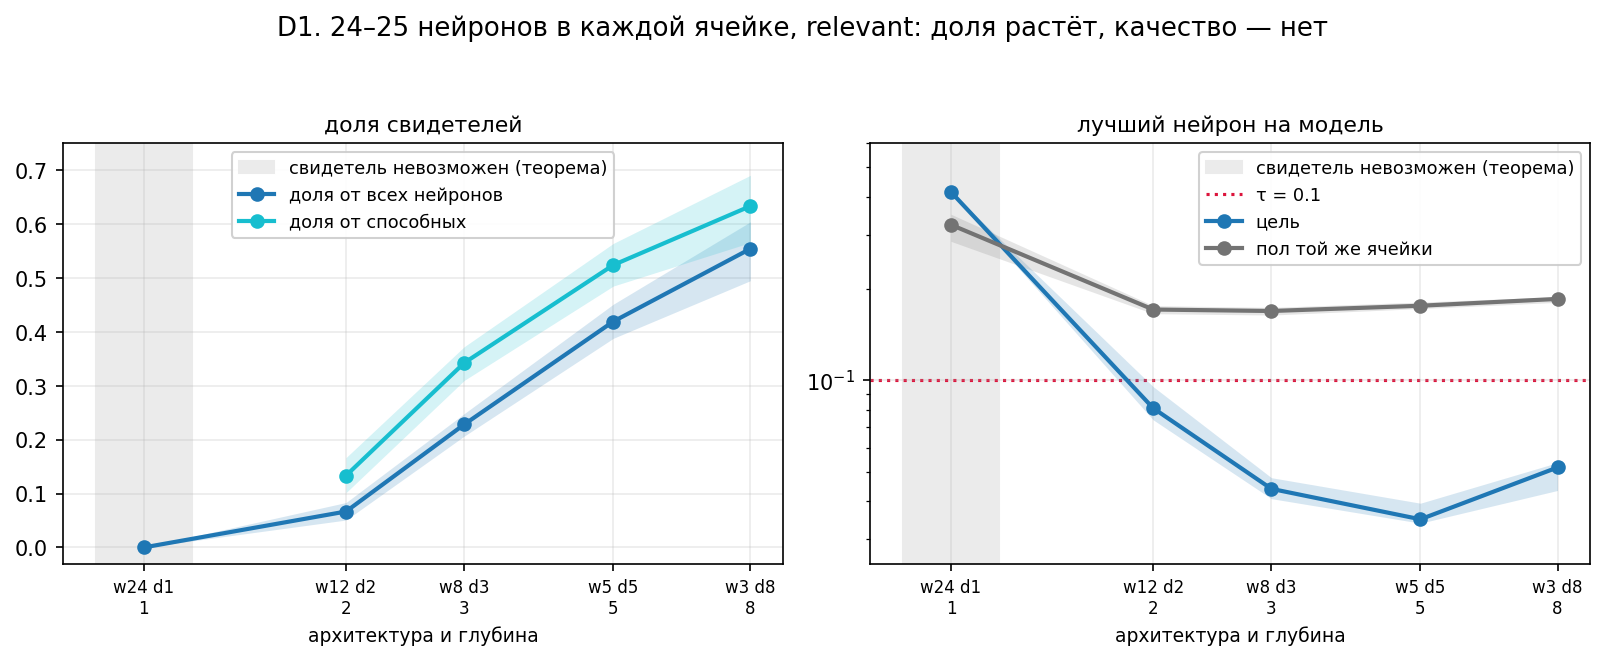

relevant, ряд равного бюджета:
  w24 d1  доля 0.0000  лучший 0.4150 [0.4142, 0.4154]  пол 0.3239  P(есть свидетель) 0.00
  w12 d2  доля 0.0667  лучший 0.0810 [0.0741, 0.0953]  пол 0.1707  P(есть свидетель) 0.66
  w8 d3   доля 0.2283  лучший 0.0440 [0.0408, 0.0479]  пол 0.1688  P(есть свидетель) 1.00
  w5 d5   доля 0.4192  лучший 0.0349 [0.0339, 0.0395]  пол 0.1756  P(есть свидетель) 0.98
  w3 d8   доля 0.5542  лучший 0.0517 [0.0435, 0.0536]  пол 0.1849  P(есть свидетель) 0.94


In [32]:
BUDGET_ROW = [(24, 1), (12, 2), (8, 3), (5, 5), (3, 8)]
BUDGET_CAP = [(12, 2), (8, 3), (5, 5), (3, 8)]      # без d1: нет способных нейронов

ap.plot_axis_panels(cells, [
    dict(title="доля свидетелей", dataset_type=REL, cells=BUDGET_ROW, x="depth",
         series=[("witness_fraction", "доля от всех нейронов", "tab:blue"),
                 ("witness_fraction_capable", "доля от способных", "tab:cyan")],
         ylim=(-0.03, 0.75)),
    dict(title="лучший нейрон на модель", dataset_type=REL, cells=BUDGET_ROW, x="depth",
         series=[("median_best", "цель", "tab:blue"),
                 ("median_best_null", "пол той же ячейки", "0.45")],
         log_y=True, ylim=(0.025, 0.6), hline=(aw.TAU, "τ = 0.1")),
], suptitle="D1. 24–25 нейронов в каждой ячейке, relevant: доля растёт, качество — нет",
   save_path=FIG / "D1_budget_fraction_quality.png")
show(FIG / "D1_budget_fraction_quality.png")

b = (cells[cells.dataset_type == REL].set_index("arch")
     .loc[[f"w{w} d{d}" for w, d in BUDGET_ROW]])
print("relevant, ряд равного бюджета:")
for arch, r in b.iterrows():
    print(f"  {arch:7s} доля {r.witness_fraction:.4f}  "
          f"лучший {r.median_best:.4f} [{r.median_best_lo:.4f}, {r.median_best_hi:.4f}]  "
          f"пол {r.median_best_null:.4f}  P(есть свидетель) {r.p_has_witness:.2f}")

### Что видно на D1

**Доля растёт монотонно, качество — нет.** Доля свидетелей идёт 0.000 → 0.067 → 0.228 → 0.419 →
0.554, а медиана лучшего нейрона улучшается только до `d = 5` (0.0810 → 0.0440 → **0.0349**) и при
`d = 8` портится до 0.0517. Интервалы `w5 d5` [0.0339, 0.0395] и `w3 d8` [0.0435, 0.0536] не
пересекаются, так что провал не шум. Смена знака повторяется и по третьей величине: `P(в модели есть
хоть один свидетель)` тоже проходит через максимум — 0.66 → **1.00** → 0.98 → 0.94.

**Множественность действительно зафиксирована.** Пол при `d ≥ 2` почти плоский: 0.1707, 0.1688,
0.1756, 0.1849. Он и есть проверка того, что число попыток вдоль ряда не гуляет, — иначе разговор про
«эффект формы» пришлось бы вести с поправкой.

**Ноль при `w24 d1` — теорема, а его пол — нет.** Свидетеля там быть не может: вся сеть есть слой 0,
и линии уровня её нейронов — прямые. Зато пол в этой ячейке сразу 0.3239 против 0.17–0.18 у
остальных, потому что он тоже считается по НЕспособным нейронам. Это не «трудная задача», это другая
популяция, и сравнивать её с полами соседних ячеек нельзя.

**И тут же вопрос, без ответа на который D1 читать нельзя.** Ячейка `w3 d8` — единственная в ряду,
чья длительность обучения выбивается: медиана 125.5 эпох против 38–59 у остальных, а максимум 2346.
То есть провал качества на `d = 8` объясняется и глубиной, и втрое более долгим обучением, и по
самой D1 различить их нечем.

---

### D2. Тот же ряд при согласованной длительности обучения

**Что делаем.** Каждая ячейка берётся дважды: целиком и только по тем моделям, чей гейт сработал не
позже **62 эпох** — окна, в которое целиком укладываются четыре из пяти ячеек. Внутри окна различия
в длительности между ячейками нет, и если порядок сохраняется, он не про длительность.

**Что рисуем.** Медиана лучшего нейрона против глубины, две кривые: по всем моделям и по окну.
Полосы — бутстрап по моделям; у `w3 d8` в окно попадают 15 моделей из 50, поэтому его полоса шире, и
это видно.

**Чего эта проверка НЕ даёт.** Это согласованная подвыборка, а не вмешательство: отбирая модели по
эпохе гейта, мы отбираем и по удачности инициализации — медленный прогон это прогон, которому
инициализация досталась неудачная. Поэтому здесь получается **граница** на величину конфаунда, а не
его разложение. Разводит их задача E, где длительность меняется внутри одного прогона.

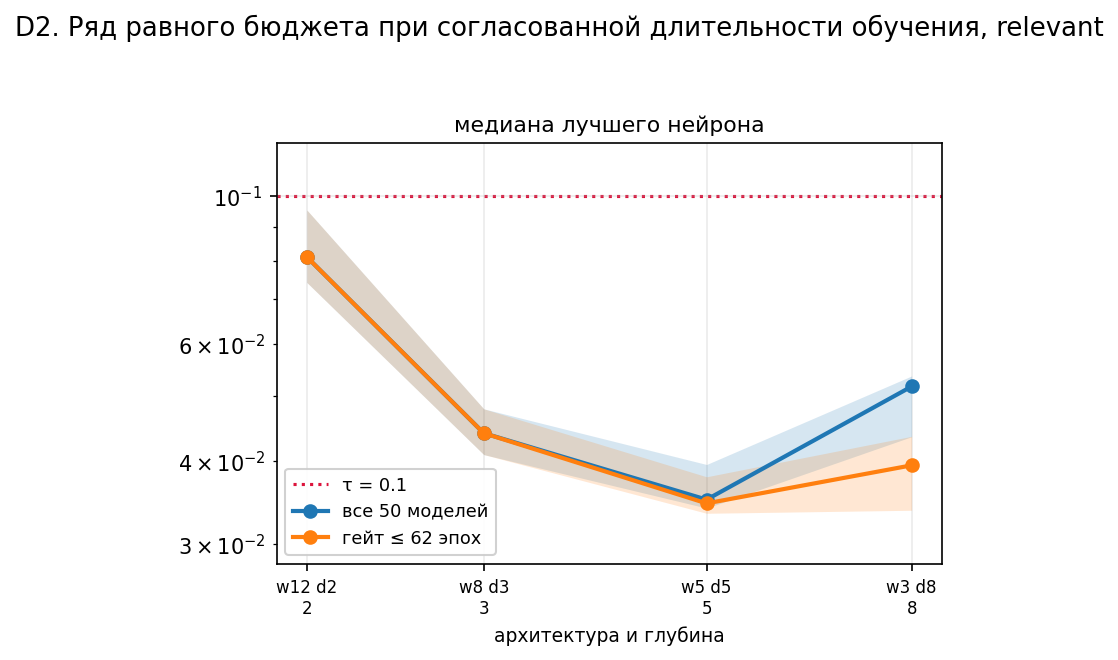

длительность обучения и результат в окне:
  w24 d1  медиана   59.0 эпох (размах 32-113)
  w12 d2  медиана   38.0 эпох (размах 25-61)  |  в окне n=50, лучший 0.0810 [0.0741, 0.0953], доля 0.0667
  w8 d3   медиана   38.0 эпох (размах 27-47)  |  в окне n=50, лучший 0.0440 [0.0408, 0.0479], доля 0.2283
  w5 d5   медиана   41.0 эпох (размах 25-219)  |  в окне n=39, лучший 0.0345 [0.0333, 0.0378], доля 0.4615
  w3 d8   медиана  125.5 эпох (размах 29-2346)  |  в окне n=15, лучший 0.0394 [0.0337, 0.0435], доля 0.6861


In [33]:
dm = aw.duration_matched(df, REL, BUDGET_CAP, max_epochs=62, n_boot=2000)
dm.to_csv(AGG / "duration_matched_budget.csv", index=False)

ap.plot_axis_panels(dm, [
    dict(title="медиана лучшего нейрона", dataset_type=REL, cells=BUDGET_CAP, x="depth",
         series=[("median_best_all", "все 50 моделей", "tab:blue"),
                 ("median_best_window", "гейт ≤ 62 эпох", "tab:orange")],
         log_y=True, ylim=(0.028, 0.12), hline=(aw.TAU, "τ = 0.1")),
], suptitle="D2. Ряд равного бюджета при согласованной длительности обучения, relevant",
   save_path=FIG / "D2_duration_matched.png")
show(FIG / "D2_duration_matched.png")

dur = aw.duration_table(df, REL, BUDGET_ROW)
dur.to_csv(AGG / "budget_row_duration.csv", index=False)
print("длительность обучения и результат в окне:")
for r in dur.itertuples():
    w = dm[dm.arch == r.arch]
    tail = ("" if not len(w) else
            f"  |  в окне n={int(w.n_window.iat[0]):2d}, лучший "
            f"{w.median_best_window.iat[0]:.4f} "
            f"[{w.median_best_window_lo.iat[0]:.4f}, {w.median_best_window_hi.iat[0]:.4f}], "
            f"доля {w.fraction_window.iat[0]:.4f}")
    print(f"  {r.arch:7s} медиана {r.median_epochs:6.1f} эпох "
          f"(размах {r.min_epochs}-{r.max_epochs}){tail}")

### Что видно на D2

**Провал на `d = 8` согласования не переживает.** В окне до 62 эпох медиана лучшего у `w3 d8` падает
с 0.0517 до **0.0394 [0.0337, 0.0435]**, а у `w5 d5` она равна 0.0345 [0.0333, 0.0378] — интервалы
**пересекаются**. То есть при сопоставимой длительности обучения самая глубокая ячейка ряда и эталон
неразличимы, и «качество портится после `d = 5`» сказать нельзя.

**А рост до `d = 5` переживает.** `w12 d2` (0.0810) и `w8 d3` (0.0440) в окно попадают целиком, их
числа не меняются вовсе, и обе остаются заметно хуже `w5 d5`. Значит подъём качества от двух слоёв к
пяти — не эффект длительности.

**Доля в окне растёт так же и даже сильнее:** 0.067 → 0.228 → 0.462 → **0.686**. Отбор коротко
обучавшихся моделей поднимает её у обеих глубоких ячеек, то есть длительное обучение работает против
свидетельствования — но насколько именно, эта проверка не говорит.

**Итоговая формулировка D1 после D2.** При равном бюджете глубина улучшает и долю, и качество —
монотонно до `d = 5`. Дальше **доля продолжает расти, а качество выходит на полку**. Это ровно то,
что предсказывает механизм насыщения из C6: построение признака занимает около четырёх
преобразований, после чего лишние слои его переносят, а не улучшают, — и поэтому добавляют охват, но
не резкость.

---

### D3. Профиль по слоям вне тех ячеек, на которых он строился

**Что рисуем.** Профиль доли свидетелей по слоям для ряда равного бюджета (слева) и для ряда глубины
при `w = 5` из пункта C (справа). Одна и та же глубина в двух рядах — это разные ширины: при `d = 2`
бюджетная ячейка **шире** эталонной (12 против 5), при `d = 8` — **уже** (3 против 5).

**Зачем.** Пункт C построил профиль на ряду глубины при `w = 5` и на ряду ширины при `d = 5`. Ряд
равного бюджета — четыре ячейки, которых в C не было ни одной. Если механизм C верен, он должен
предсказать их профиль: узкая сеть начинает раньше, широкая заканчивает выше. Это проверка вне
выборки, и она бесплатна.

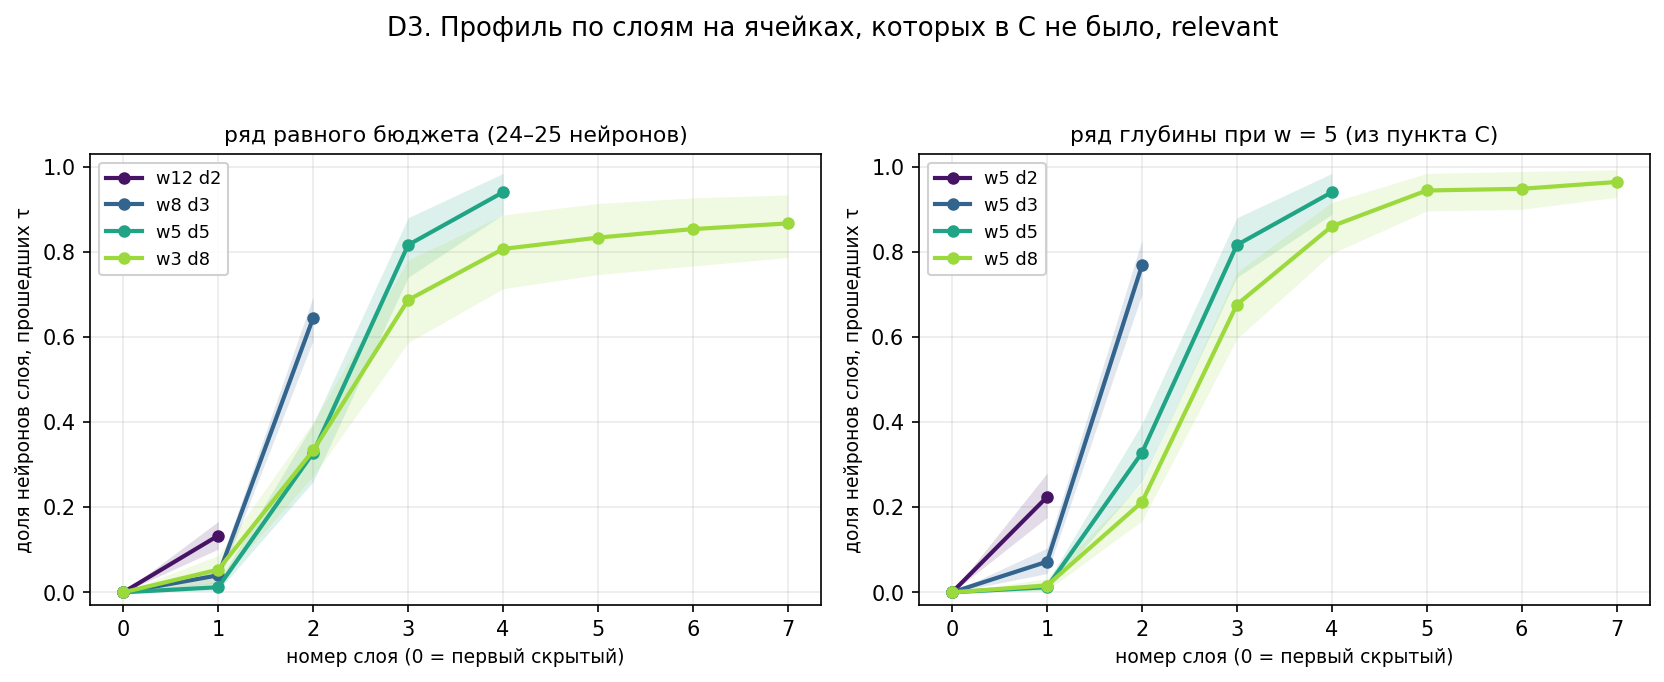

доля свидетелей по слоям (бюджет  |  w = 5 той же глубины):
  d=2  w12 d2  0.000 0.133
         w5 d2  0.000 0.224
  d=3  w8 d3   0.000 0.040 0.645
         w5 d3  0.000 0.072 0.768
  d=5  w5 d5   0.000 0.012 0.328 0.816 0.940
         w5 d5  0.000 0.012 0.328 0.816 0.940
  d=8  w3 d8   0.000 0.053 0.333 0.687 0.807 0.833 0.853 0.867
         w5 d8  0.000 0.016 0.212 0.676 0.860 0.944 0.948 0.964


In [34]:
prof_budget = aw.layer_profile(df, REL, BUDGET_CAP, n_boot=2000)
prof_w5 = aw.layer_profile(df, REL, [(5, 2), (5, 3), (5, 5), (5, 8)], n_boot=2000)
prof_budget.assign(row="budget").to_csv(AGG / "layer_profiles_budget.csv", index=False)

ap.plot_layer_profiles([
    dict(title="ряд равного бюджета (24–25 нейронов)", profile=prof_budget,
         floor=None, x="layer_id", by="depth"),
    dict(title="ряд глубины при w = 5 (из пункта C)", profile=prof_w5,
         floor=None, x="layer_id", by="depth"),
], suptitle="D3. Профиль по слоям на ячейках, которых в C не было, relevant",
   save_path=FIG / "D3_budget_layer_profile.png")
show(FIG / "D3_budget_layer_profile.png")

print("доля свидетелей по слоям (бюджет  |  w = 5 той же глубины):")
for depth in (2, 3, 5, 8):
    a = prof_budget[prof_budget.depth == depth].sort_values("layer_id")
    c = prof_w5[prof_w5.depth == depth].sort_values("layer_id")
    print(f"  d={depth}  {a.arch.iat[0]:7s} " + " ".join(f"{v:.3f}" for v in a.fraction)
          + f"\n         w5 d{depth}  " + " ".join(f"{v:.3f}" for v in c.fraction))

### Что видно на D3

**Механизм C предсказывает эти четыре профиля, не будучи на них построенным.**

При `d = 2` бюджетная ячейка **шире** эталонной (12 против 5) — и её единственный способный слой
свидетельствует **реже**: 0.133 против 0.224. При `d = 8` бюджетная ячейка **уже** (3 против 5) — и
на ранних слоях она свидетельствует **чаще** (0.053 против 0.016 на слое 1, 0.333 против 0.212 на
слое 2), а на поздних **реже** (0.867 против 0.964 на последнем). Это в точности правило C1: у сети
без запаса нет выбора, когда выделять признак, и она начинает раньше; сеть с запасом откладывает, но
заканчивает выше.

**И насыщение видно здесь тоже.** У `w3 d8` профиль после слоя 4 почти не меняется: 0.807, 0.833,
0.853, 0.867 — прирост в сотые. У `w5 d8` из C было то же самое начиная со слоя 5. Длина построения
не зависит от ширины, а полка, на которую оно выходит, зависит: узкая сеть встаёт на 0.87, широкая на
0.96.

**Агрегат при этом почти не отличает форму.** Средние профиля (они же доли пункта B): бюджет 0.067 /
0.228 / 0.419 / 0.554 против 0.112 / 0.280 / 0.419 / 0.578 у ряда `w = 5`. При одинаковой глубине
разница не превышает 0.05, хотя ширина отличается втрое в обе стороны. **Доля свидетелей есть почти
чистая функция глубины**, и ширина двигает её лишь настолько, насколько двигает высоту полки.

---

### D4. Выход сети вдоль ряда равного бюджета

**Что рисуем.** Те же полосы, что в C3: точка — одна модель, значение — скор выхода `sigmoid(model(x))`,
красный пунктир — `τ`. Пять форм на relevant, пять на irrelevant.

**Зачем именно здесь.** В ряду есть ячейка `w24 d1`, у которой **ни один нейрон не может**
свидетельствовать по теореме. Если при этом выход свидетельствует, то ноль в D1 — это утверждение о
нейронах, а не о сети и не о критерии. Проверить это стоит прямо, а не рассуждением.

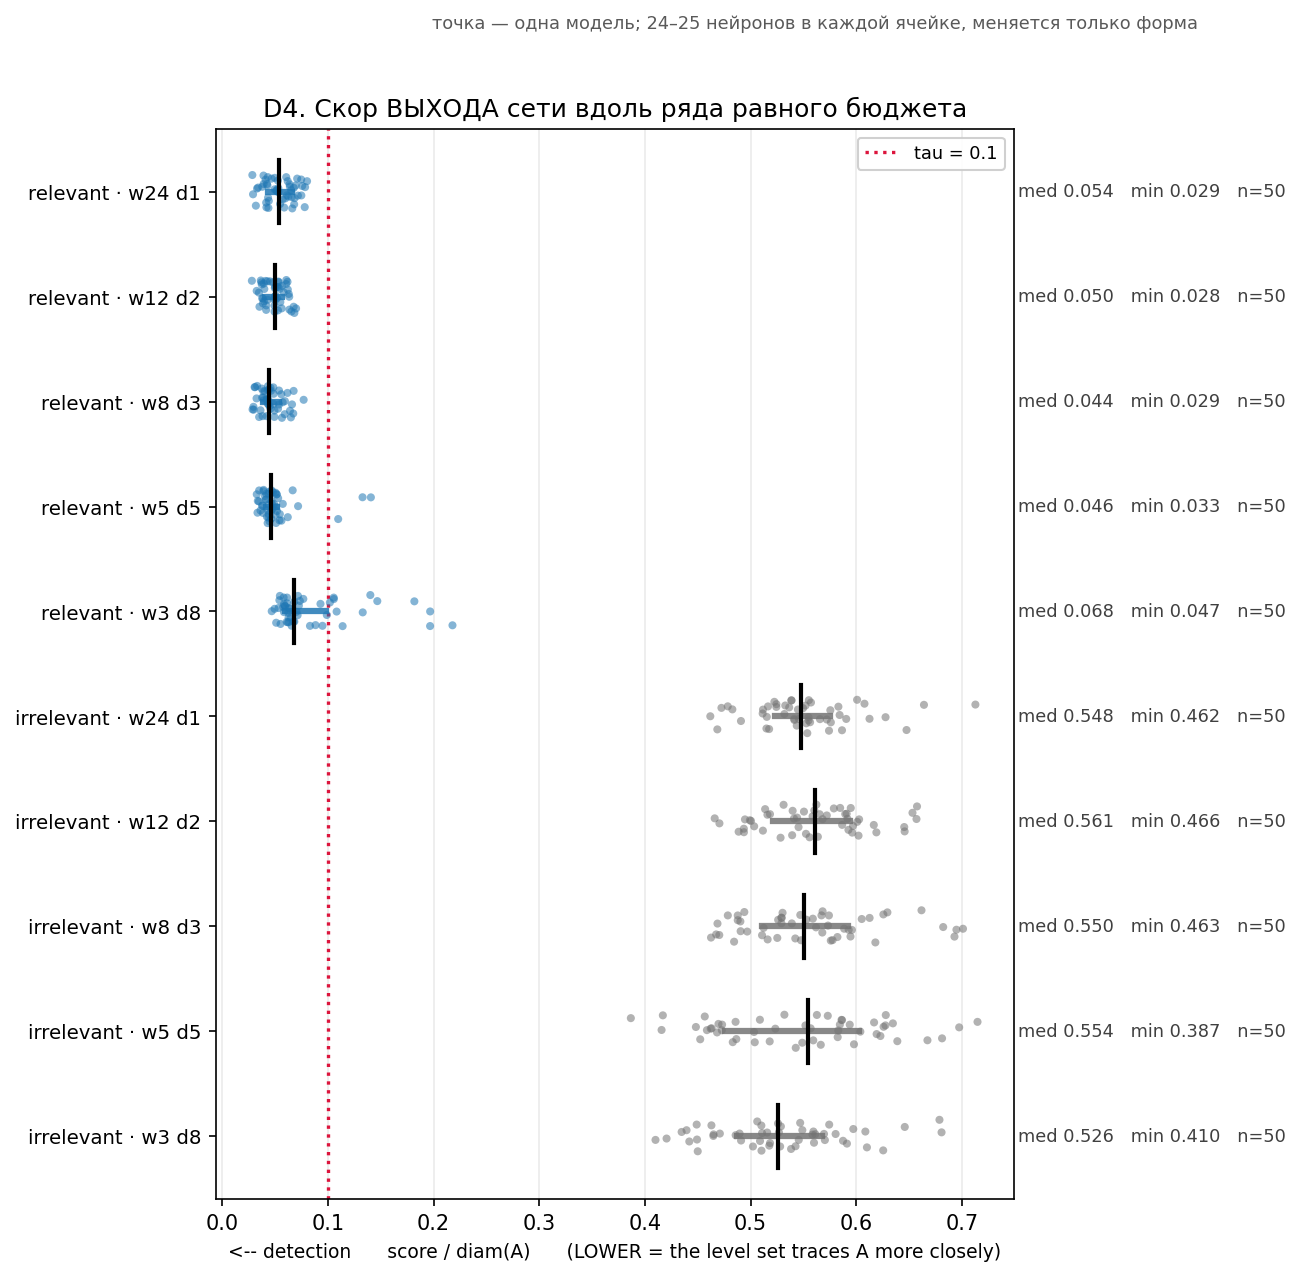

доля моделей, у которых голова свидетельствует окружность:
  relevant    w24 d1: 100.0%   медиана скора 0.0539
  relevant    w12 d2: 100.0%   медиана скора 0.0500
  relevant    w8 d3: 100.0%   медиана скора 0.0441
  relevant    w5 d5:  94.0%   медиана скора 0.0463
  relevant    w3 d8:  76.0%   медиана скора 0.0677
  irrelevant  w24 d1:   0.0%   медиана скора 0.5476
  irrelevant  w12 d2:   0.0%   медиана скора 0.5612
  irrelevant  w8 d3:   0.0%   медиана скора 0.5501
  irrelevant  w5 d5:   0.0%   медиана скора 0.5543
  irrelevant  w3 d8:   0.0%   медиана скора 0.5263


In [35]:
heads_b = pd.concat([
    aw.head_scores(df, ds, BUDGET_ROW, ES, cache=AGG / "head_scores.csv",
                   output="prob", verbose=False)
    for ds in (REL, IRR)], ignore_index=True)

units_b = heads_b.assign(criterion="structural", feature="head",
                         dataset=heads_b.dataset_type)
groups_b = ([(f"relevant · {a}", {"dataset": REL, "arch": a}, "tab:blue")
             for a in [f"w{w} d{d}" for w, d in BUDGET_ROW]]
            + [(f"irrelevant · {a}", {"dataset": IRR, "arch": a}, "0.45")
               for a in [f"w{w} d{d}" for w, d in BUDGET_ROW]])
plot_unit_strips(units_b, "structural", groups_b, threshold=aw.TAU,
                 title="D4. Скор ВЫХОДА сети вдоль ряда равного бюджета",
                 caption="точка — одна модель; 24–25 нейронов в каждой ячейке, "
                         "меняется только форма",
                 save_path=FIG / "D4_budget_head.png")
show(FIG / "D4_budget_head.png")

print("доля моделей, у которых голова свидетельствует окружность:")
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for w, d in BUDGET_ROW:
        g = heads_b[(heads_b.dataset_type == ds) & (heads_b.arch == f"w{w} d{d}")]
        print(f"  {name:11s} w{w} d{d}: {g.witness.mean():6.1%}   "
              f"медиана скора {g.score.median():.4f}")

### Что видно на D4

**При глубине 1 признак закодирован распределённо — и это измерено, а не выведено.** У `w24 d1` ни
один из 24 нейронов не может свидетельствовать по теореме, и D1 показал ровно ноль. Но выход той же
сети свидетельствует окружность у **всех пятидесяти моделей** (медиана скора 0.0539). Значит ноль в
D1 — утверждение о нейронах, а не о сети и не о критерии: сеть окружность обводит, просто ни один
её нейрон не обводит поодиночке.

**Голова портится с глубиной, а доля нейронов растёт.** Вдоль ряда: 100 % → 100 % → 100 % → 94 % →
**76 %**, при том что доля свидетелей среди нейронов идёт 0.00 → 0.07 → 0.23 → 0.42 → 0.55. Две
величины движутся в противоположные стороны. `w3 d8` даёт худший выход во всём эксперименте (76 %,
медиана 0.0677) — и это та же ячейка, у которой самое долгое обучение, так что оговорка D2
распространяется и сюда.

**На irrelevant — ноль из двухсот пятидесяти**, медианы 0.526–0.561 при пороге 0.1. Форма сети
нерелевантную окружность на выход не выводит ни в каком виде.

---

## Итог по D

**1. При равном бюджете форма покупает охват, а не резкость.** Доля свидетелей растёт с глубиной
монотонно (0.00 → 0.07 → 0.23 → 0.42 → 0.55), качество лучшего нейрона улучшается только до `d = 5`,
а дальше выходит на полку. Пол при `d ≥ 2` плоский (0.169–0.185), так что множественность
зафиксирована и различие внутри ряда — эффект расположения.

**2. Провал качества на `d = 8` — эффект длительности обучения, а не глубины.** `w3 d8` —
единственная ячейка ряда, выбивающаяся по обучению (медиана 125.5 эпох против 38–59, максимум 2346).
В окне до 62 эпох её лучший нейрон идёт 0.0517 → 0.0394 [0.0337, 0.0435] и становится неотличим от
`w5 d5` (0.0345 [0.0333, 0.0378]). Подъём же от `d = 2` к `d = 5` окно переживает целиком. Это
согласованная подвыборка, а не вмешательство: разводит длительность и инициализацию задача E.

**3. Ряд равного бюджета — наименее конфаундированное сравнение эксперимента.** Длительность обучения
вдоль него почти постоянна (59 / 38 / 38 / 41 эпохи при `d ≤ 5`), тогда как в ряду ширины задачи B
она меняется в 9.5 раза. Поэтому вывод B «глубина сильнее ширины» именно здесь и стоит на твёрдом.

**4. Механизм пункта C предсказывает четыре ячейки, на которых не строился.** Более широкая
бюджетная ячейка при `d = 2` свидетельствует реже (0.133 против 0.224), более узкая при `d = 8` —
чаще на ранних слоях и реже на поздних. Длина построения от ширины не зависит, высота полки зависит.
Агрегатная доля при равной глубине отличается не больше чем на 0.05 при трёхкратной разнице ширины:
**доля есть почти чистая функция глубины**.

**5. При глубине 1 кодирование обязано быть распределённым.** Выход `w24 d1` свидетельствует
окружность у 100 % моделей, при нуле нейронов-свидетелей. Ноль по теореме — это про нейроны, а сеть
задачу решает и границу обводит.

**6. На нерелевантной окружности форма не даёт ничего.** Ни одного свидетеля среди нейронов, ни
одного среди двухсот пятидесяти выходов. Рост `p_superior` вдоль ряда (0.033 → 0.142) — движение
**пола**, а не цели: медиана цели стоит на месте (0.4126 → 0.4080), а нулевые размещения с глубиной
становятся труднее.

---

### Чего D не показывает

* **Ничего про причинность длительности.** D2 — согласованная подвыборка; отбор по эпохе гейта
  отбирает и по удачности инициализации. Это граница на конфаунд, а не его разложение.
* **Ряд один и короткий** — пять форм при одном бюджете 24–25 нейронов. Переносить «глубина покупает
  охват» на другие бюджеты без проверки нельзя.
* **Пол ячейки `w24 d1` не сравним с соседними**: он считается по неспособным нейронам и потому
  вдвое выше.

---

# E. Переобучение

Гейт останавливает обучение в тот момент, когда сеть впервые удерживает 100 % accuracy пять эпох
подряд. На линейно разделимой задаче это происходит тем раньше, чем сеть шире, и разница огромна:
на `simple_relevant` при глубине 5 медиана остановки идёт **124 эпохи при ширине 3 против 9 при
ширине 40**. Значит **ось ширины в задачах A и B — это одновременно ось длительности обучения**,
идущая в обратную сторону и в четырнадцать раз, и любую кривую там можно прочесть как кривую
«скор против того, сколько сеть училась».

**Наблюдением это не разрешается.** Внутри ячейки корреляция Спирмена между эпохой остановки и
лучшим скором **меняет знак**: +0.70 при `w3 d5`, +0.71 при `w5 d8`, но −0.50 при `w5 d2` и −0.44
при `w12 d2`. Модель, которой понадобилось 1861 эпоха, — это модель с неудачной инициализацией,
поэтому положительная корреляция читается двумя несовместимыми способами: «учился дольше — вышло
хуже» и «плохие прогоны учатся дольше». Различить их можно только вмешательством.

## Как устроен эксперимент

Обучение **не сеет seed**: повторный прогон той же архитектуры даёт другую траекторию, а не более
длинную. Поэтому ранняя и поздняя точка берутся из **одного прогона**: каждая сеть учится до 3000
эпох, а её состояние сохраняется в нескольких промежуточных точках. Сравнение получается
внутримодельным: та же инициализация, та же траектория, дисперсия по сидам уходит из разности целиком.

**Что дальше называется лестницей.** Лестница — это набор моментов, в которые снимается состояние
прогона, заданный **кратными его собственного гейта**: `×1` — сам гейт, `×10` — вдесятеро больше эпох,
и `конец` — три тысячи эпох, общий предел для всех. Кратные, а не абсолютные эпохи, потому что гейты
ячеек различаются на порядок: одна и та же абсолютная эпоха у одной сети приходится до гейта, у другой
далеко после. Каждая ступень хранится обычным ансамблем и оценивается как любая другая, поэтому
«ступень» и «ячейка пула» — объекты одного типа.

| ячейка | роль |
|---|---|
| `w3 d2` | абсолютный минимум: наименьшая сеть, надёжно решающая задачу и имеющая способный нейрон |
| `w3 d5` | минимальная ширина среди изученных; там же живут все аномалии пунктов B–D |
| `w5 d5` | эталон, он же независимая репликация пула |
| `w3 d8` | узкая глубокая |
| `w24 d1` | **контроль инструмента**: свидетель невозможен по теореме, поэтому любое движение скора там — движение базовой линии критерия, а не представления |

Три вопроса, по убыванию важности: **(1)** объясняется ли тренд по ширине длительностью;
**(2)** причинность это или отбор; **(3)** вырезает ли сеть ненужную ей окружность сильнее, если
продолжать учить после 100 % accuracy.

**Оговорка про ступень `×10`.** У прогона с поздним гейтом она не влезает в 3000 эпох, поэтому на
`relevant` её имеют не все прогоны (37 из 56 при `w3 d2`). Всё сравнение ведётся **на прогонах,
присутствующих на всех трёх ступенях** — иначе верхние ступени сравнивали бы другую популяцию,
отобранную по скорости сходимости, и разницу приписали бы длительности.

---

### E1. Что дообучение делает с релевантной окружностью

**Что рисуем.** Три панели вдоль лестницы. Слева доля свидетелей среди нейронов, в середине медиана
лучшего нейрона на модель (логарифмическая шкала, красный пунктир — `τ`), справа **парная разность**:
медиана по прогонам от «скор этой ступени минус скор гейта у того же прогона». Ниже нуля — дообучение
улучшило. Серым пунктиром всюду `w24 d1` — контрольная ячейка, где свидетеля быть не может.

**Что хотим увидеть.** Если бы конфаунд объяснял тренд по ширине, дообучение должно было бы **портить**
скор: широкие сети учатся мало, и их преимущество тогда объяснялось бы именно этим. Если же
дообучение улучшает, то конфаунд действует **против** вывода B, а не за него, и вывод от него только
крепнет. Контрольная линия говорит, сколько из любого движения приходится на саму линейку.

In [36]:
# Ступени лежат отдельными ансамблями, но сравнение обязано быть ВНУТРИ прогона,
# иначе разность двух ступеней — это разность инициализаций, а не длительностей.
# load_overtraining восстанавливает номер прогона (id моделей между ступенями НЕ
# совпадают: у прогона с поздним гейтом верхней ступени нет, и нумерация съезжает).
ot = aw.load_overtraining(EXPERIMENTS["exp2_extended"].results_dir)
BASES = ["tanh_w3_d2", "tanh_w3_d5", "tanh_w5_d5", "tanh_w3_d8", "tanh_w24_d1"]
RUNGS = ("x1", "x10", "end")

ladder = pd.concat([aw.paired_rungs(ot, ds, b, rungs=RUNGS, n_boot=2000)
                    for ds in (REL, IRR) for b in BASES], ignore_index=True)
ladder.to_csv(AGG / "overtrain_ladder.csv", index=False)

print(f"прогонов всего {ot.run.nunique()}, строк {len(ot)}")
print("общих прогонов на ячейку (ступень ×10 есть не у всех — у медленных "
      "прогонов она не влезла в 3000 эпох):")
piv = ladder.pivot_table(index=["dataset_type", "base"], values="n_runs", aggfunc="first")
print(piv.to_string())
print("\nмедианная эпоха ступени:")
print(ladder.pivot_table(index="base", columns="rung", values="median_epoch",
                         aggfunc="median").loc[BASES, list(RUNGS)].round(0).to_string())

/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/serdabel/.local/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: R

прогонов всего 539, строк 88179
общих прогонов на ячейку (ступень ×10 есть не у всех — у медленных прогонов она не влезла в 3000 эпох):
                               n_runs
dataset_type      base               
simple_irrelevant tanh_w24_d1      50
                  tanh_w3_d2       56
                  tanh_w3_d5       56
                  tanh_w3_d8       63
                  tanh_w5_d5       50
simple_relevant   tanh_w24_d1      50
                  tanh_w3_d2       37
                  tanh_w3_d5       38
                  tanh_w3_d8       40
                  tanh_w5_d5       49

медианная эпоха ступени:
rung           x1    x10     end
base                            
tanh_w3_d2   92.0  929.0  2999.0
tanh_w3_d5   57.0  579.0  2999.0
tanh_w5_d5   28.0  289.0  2999.0
tanh_w3_d8   54.0  552.0  2999.0
tanh_w24_d1  39.0  396.0  2999.0


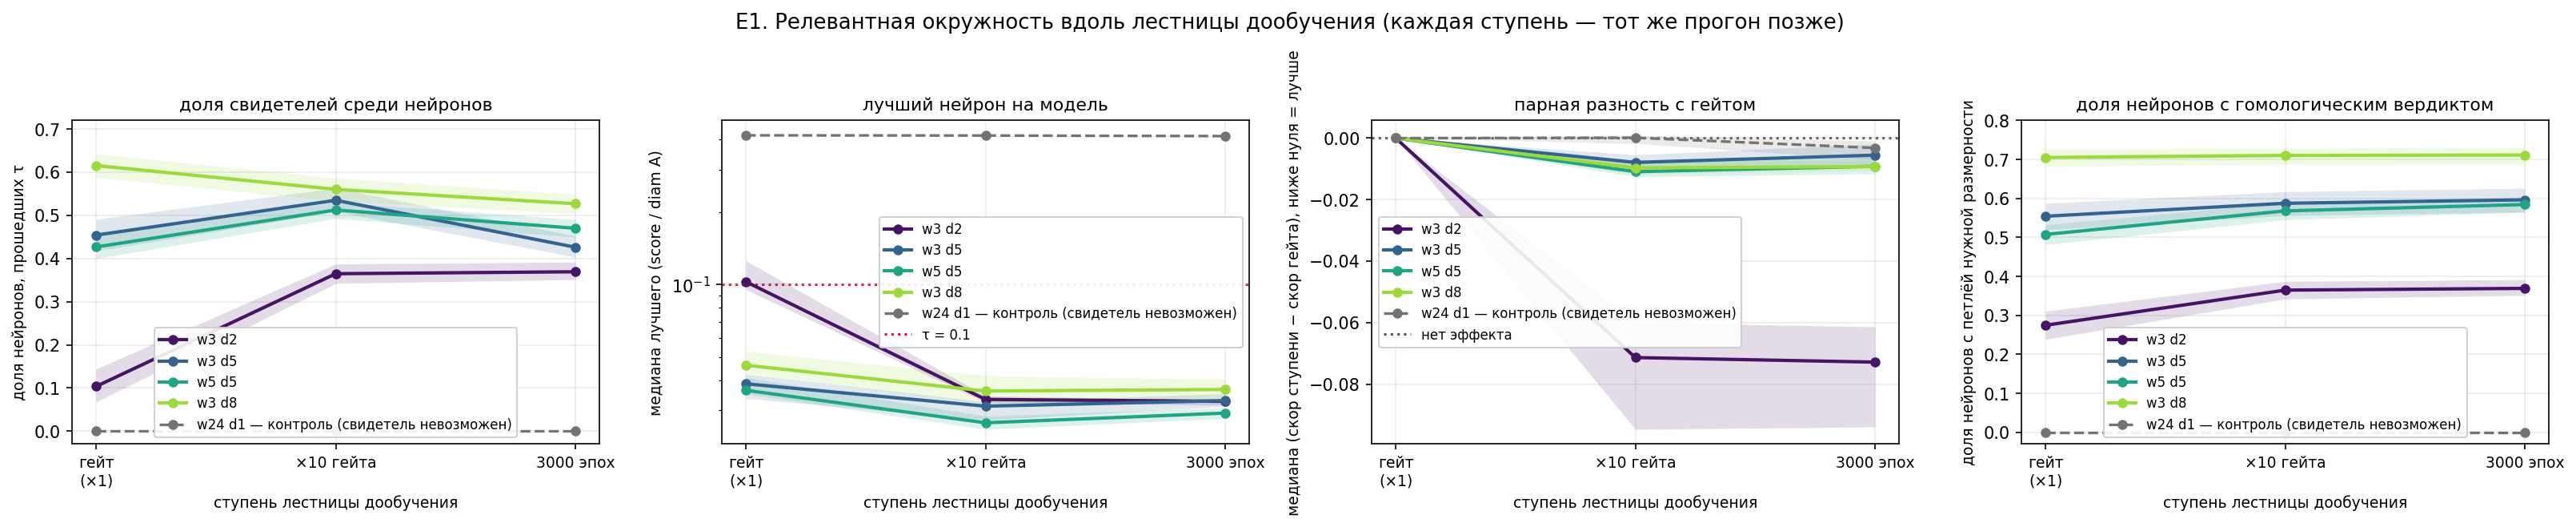

парная разность лучшего нейрона относительно гейта (отрицательная = дообучение улучшило):
  tanh_w3_d2   n=37  гейт 0.1025 → ×10 0.0333 → конец 0.0327   разность ×10 -0.0713 [-0.0947, -0.0600], конец -0.0728 [-0.0939, -0.0613]
  tanh_w3_d5   n=38  гейт 0.0386 → ×10 0.0312 → конец 0.0329   разность ×10 -0.0079 [-0.0097, -0.0054], конец -0.0055 [-0.0091, -0.0019]
  tanh_w5_d5   n=49  гейт 0.0363 → ×10 0.0266 → конец 0.0292   разность ×10 -0.0109 [-0.0125, -0.0081], конец -0.0091 [-0.0115, -0.0062]
  tanh_w3_d8   n=40  гейт 0.0461 → ×10 0.0361 → конец 0.0366   разность ×10 -0.0097 [-0.0118, -0.0075], конец -0.0092 [-0.0104, -0.0072]
  tanh_w24_d1  n=50  гейт 0.4157 → ×10 0.4149 → конец 0.4127   разность ×10 +0.0001 [-0.0017, +0.0010], конец -0.0032 [-0.0070, -0.0009]

доля моделей, у которых есть хоть один свидетель:
  tanh_w3_d2  : 0.41 → 1.00 → 1.00
  tanh_w3_d5  : 1.00 → 1.00 → 1.00
  tanh_w5_d5  : 1.00 → 1.00 → 1.00
  tanh_w3_d8  : 1.00 → 1.00 → 1.00
  tanh_w24_d1 : 0.00 → 0.00 → 0.00

In [37]:
rel = ladder[ladder.dataset_type == REL]
ap.plot_rung_ladder([
    dict(title="доля свидетелей среди нейронов", table=rel, value="fraction",
         ylabel="доля нейронов, прошедших τ", ylim=(-0.03, 0.72),
         highlight="tanh_w24_d1"),
    dict(title="лучший нейрон на модель", table=rel, value="median_best",
         ylabel="медиана лучшего (score / diam A)", log_y=True,
         hline=(aw.TAU, "τ = 0.1"), highlight="tanh_w24_d1"),
    dict(title="парная разность с гейтом", table=rel, value="paired_delta",
         ylabel="медиана (скор ступени − скор гейта), ниже нуля = лучше",
         hline=(0.0, "нет эффекта"), hline_colour="0.35",
         highlight="tanh_w24_d1"),
    dict(title="доля нейронов с гомологическим вердиктом", table=rel,
         value="hom_fraction", ylabel="доля нейронов с петлёй нужной размерности",
         ylim=(-0.03, 0.80), highlight="tanh_w24_d1"),
], suptitle="E1. Релевантная окружность вдоль лестницы дообучения "
            "(каждая ступень — тот же прогон позже)",
   save_path=FIG / "E1_overtrain_relevant.png")
show(FIG / "E1_overtrain_relevant.png")

print("парная разность лучшего нейрона относительно гейта "
      "(отрицательная = дообучение улучшило):")
for b in BASES:
    r = rel[(rel.base == b) & (rel.rung == "end")].iloc[0]
    x10 = rel[(rel.base == b) & (rel.rung == "x10")].iloc[0]
    g = rel[(rel.base == b) & (rel.rung == "x1")].iloc[0]
    print(f"  {b:12s} n={int(r.n_runs):2d}  гейт {g.median_best:.4f} → "
          f"×10 {x10.median_best:.4f} → конец {r.median_best:.4f}   "
          f"разность ×10 {x10.paired_delta:+.4f} [{x10.paired_delta_lo:+.4f}, "
          f"{x10.paired_delta_hi:+.4f}], конец {r.paired_delta:+.4f} "
          f"[{r.paired_delta_lo:+.4f}, {r.paired_delta_hi:+.4f}]")
print("\nдоля моделей, у которых есть хоть один свидетель:")
for b in BASES:
    vals = [rel[(rel.base == b) & (rel.rung == k)].p_has_witness.iat[0] for k in RUNGS]
    print(f"  {b:12s}: " + " → ".join(f"{v:.2f}" for v in vals))
print("\nвторой критерий: доля нейронов с вердиктом и лучший на модель margin:")
for b in BASES:
    fr = [rel[(rel.base == b) & (rel.rung == k)].hom_fraction.iat[0] for k in RUNGS]
    mg = [rel[(rel.base == b) & (rel.rung == k)].median_hom_best.iat[0] for k in RUNGS]
    print(f"  {b:12s}: доля " + " → ".join(f"{v:.3f}" for v in fr)
          + "   margin " + " → ".join(f"{v:+.3f}" for v in mg))

### Что видно на E1

**Дообучение улучшает скор, и на каждой способной ячейке.** Парная разность с гейтом отрицательна
везде, и ни один интервал не накрывает ноль:

| ячейка | гейт | ×10 | конец | парная разность в конце |
|---|---|---|---|---|
| `w3 d2` | 0.1025 | 0.0333 | 0.0327 | **−0.0728 [−0.0939, −0.0613]** |
| `w3 d5` | 0.0386 | 0.0312 | 0.0329 | −0.0055 [−0.0091, −0.0019] |
| `w5 d5` | 0.0363 | 0.0266 | 0.0292 | −0.0091 [−0.0115, −0.0062] |
| `w3 d8` | 0.0461 | 0.0361 | 0.0366 | −0.0092 [−0.0104, −0.0072] |
| `w24 d1` (контроль) | 0.4157 | 0.4149 | 0.4127 | −0.0032 [−0.0070, −0.0009] |

**Вопрос 2 решён, и ответ — отбор, а не причинность.** Наблюдаемая корреляция внутри `w3 d5` была
**+0.70**: чем дольше прогон учился, тем хуже был его лучший нейрон. Парный эффект на тех же ячейках
имеет **противоположный знак**: −0.0079 при `×10`. То есть медленно сходящиеся прогоны
действительно хуже — но не оттого, что долго учились, а оттого, что им досталась неудачная
инициализация. Заставить конкретный прогон учиться дольше — значит его улучшить.

**Вопрос 1 решён, и конфаунд действует против вывода B, а не за него.** Широкие сети останавливаются
раньше (9 эпох при `w40` против 124 при `w3`), а дообучение улучшает скор. Значит широкие ячейки в
задачах A и B измерены **в невыгодных для себя условиях**, и настоящее преимущество ширины не меньше
измеренного, а больше. Вывод «ширина покупает не только попытки» от снятия конфаунда может только
укрепиться.

**Минимальная сети не хватает не ёмкости, а времени.** У `w3 d2` на гейте свидетель есть лишь у
**41 %** моделей при медиане лучшего 0.1025 — то есть чуть хуже порога. После дообучения свидетель
есть у **100 %**, а медиана падает до 0.0327, вровень с эталонной `w5 d5`. Шестью нейронами
окружность выделяется прекрасно; на гейте она просто ещё не выделена.

**Оптимум стоит не в конце, а на `×10`.** У трёх ячеек из четырёх ступень `×10` лучше конца:
−0.0079 против −0.0055, −0.0109 против −0.0091, −0.0097 против −0.0092. Доля ведёт себя так же
(например, 0.513 → 0.470 у `w5 d5`). Слишком долгое обучение начинает понемногу вредить — это тот же
эффект, что виден в X3 на хвосте глубоких сетей.

**Второй критерий согласен, и на четвёртой панели это видно прямо.** Доля нейронов с гомологическим
вердиктом растёт вдоль лестницы монотонно на всех способных ячейках: 0.275 → 0.365 → 0.369 у `w3 d2`,
0.508 → 0.568 → 0.584 у `w5 d5`, 0.705 → 0.710 → 0.711 у `w3 d8`. Обратите внимание, что здесь нет
отката к концу — в отличие от структурной доли, которая на `×10` выше, чем на трёх тысячах эпох. Это
тот же контраст, что в C2: замкнутых линий уровня становится только больше, а вот их геометрия к концу
обучения от окружности отходит. Лучший на модель margin ведёт себя так же: у `w3 d2` он растёт с
+0.563 до +1.485, у остальных идёт с +1.62–1.73 до +1.80 и там встаёт — это потолок самой величины, а
не результат.

**Контроль уже на этой фигуре.** `w24 d1` за три тысячи эпох сдвигается на −0.0032 — впятеро меньше,
чем `w5 d5`, и в двадцать три раза меньше, чем `w3 d2`. Насколько при этом изменилось само поле,
проверяется отдельно в E3.

---

### E2. Та же лестница на нерелевантной окружности

**Что рисуем.** Три панели: медиана лучшего нейрона, парная разность с гейтом и доля нейронов с
гомологическим вердиктом — всё на `simple_irrelevant`. Структурную долю рисовать нечего: она везде
ноль, и это само по себе результат.

**Что хотим увидеть.** Это исходный вопрос PLAN'а в его временнóй форме: пункт A показал, что
избыточная **ёмкость** свидетеля ненужной окружности не порождает; порождает ли его избыточное
**время**? Если да, incidental-эффект окажется функцией длительности обучения, а не только размера,
и все выводы A придётся читать с оговоркой «при такой-то длительности».

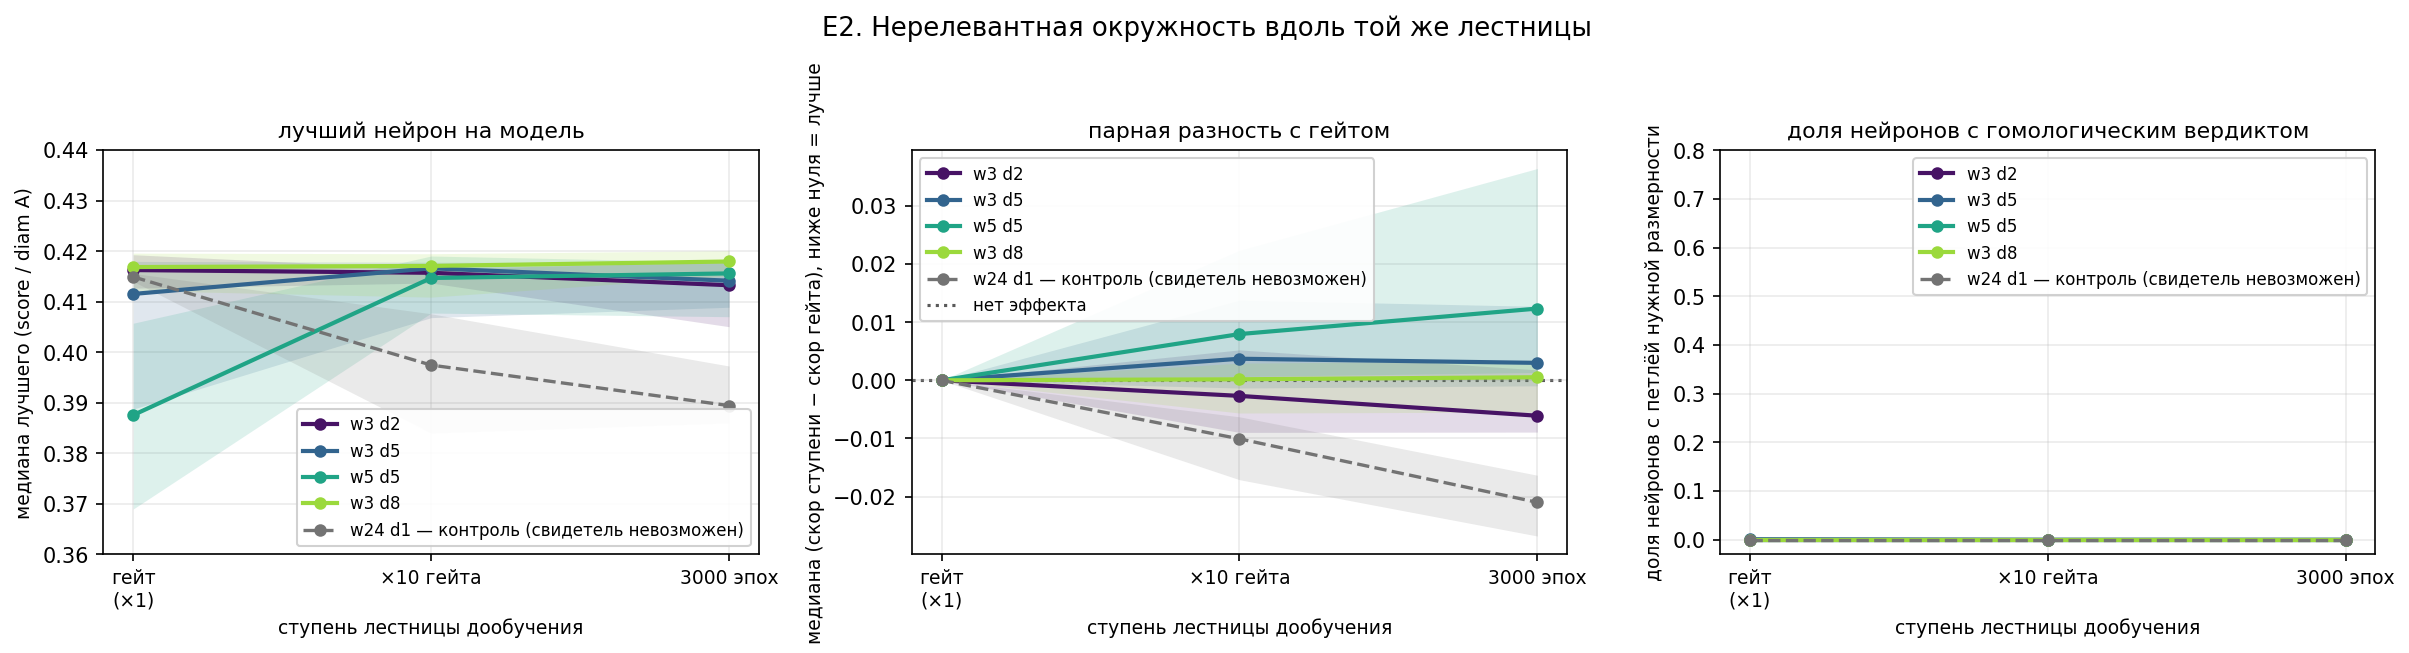

свидетелей нерелевантной окружности на всех ступенях и во всех ячейках: 0 ячеек с ненулевой долей из 15

парная разность лучшего нейрона (положительная = дообучение УХУДШИЛО):
  tanh_w3_d2   n=56  гейт 0.4163 → конец 0.4133   разность -0.0061 [-0.0089, +0.0018]
  tanh_w3_d5   n=56  гейт 0.4115 → конец 0.4142   разность +0.0030 [-0.0009, +0.0127]
  tanh_w5_d5   n=50  гейт 0.3876 → конец 0.4156   разность +0.0123 [+0.0014, +0.0364]
  tanh_w3_d8   n=63  гейт 0.4169 → конец 0.4180   разность +0.0005 [-0.0055, +0.0035]
  tanh_w24_d1  n=50  гейт 0.4149 → конец 0.3894   разность -0.0210 [-0.0268, -0.0163]

лучший гомологический margin (отрицательный = вердикта нет):
  tanh_w3_d2  : -0.079 → -0.018 →   нет бара
  tanh_w3_d5  : -0.036 → -0.073 → -0.058
  tanh_w5_d5  : -0.060 → -0.059 → -0.049
  tanh_w3_d8  : -0.042 → -0.064 → -0.060
  tanh_w24_d1 :   нет бара →   нет бара →   нет бара


In [38]:
irr = ladder[ladder.dataset_type == IRR]
ap.plot_rung_ladder([
    dict(title="лучший нейрон на модель", table=irr, value="median_best",
         ylabel="медиана лучшего (score / diam A)", ylim=(0.36, 0.44),
         highlight="tanh_w24_d1"),
    dict(title="парная разность с гейтом", table=irr, value="paired_delta",
         ylabel="медиана (скор ступени − скор гейта), ниже нуля = лучше",
         hline=(0.0, "нет эффекта"), hline_colour="0.35",
         highlight="tanh_w24_d1"),
    dict(title="доля нейронов с гомологическим вердиктом", table=irr,
         value="hom_fraction", ylabel="доля нейронов с петлёй нужной размерности",
         ylim=(-0.03, 0.80), highlight="tanh_w24_d1"),
], suptitle="E2. Нерелевантная окружность вдоль той же лестницы",
   save_path=FIG / "E2_overtrain_irrelevant.png")
show(FIG / "E2_overtrain_irrelevant.png")

print(f"свидетелей нерелевантной окружности на всех ступенях и во всех ячейках: "
      f"{int(irr.fraction.sum() * 0 + (irr.fraction > 0).sum())} ячеек с ненулевой долей "
      f"из {len(irr)}")
print("\nпарная разность лучшего нейрона (положительная = дообучение УХУДШИЛО):")
for b in BASES:
    r = irr[(irr.base == b) & (irr.rung == "end")].iloc[0]
    g = irr[(irr.base == b) & (irr.rung == "x1")].iloc[0]
    print(f"  {b:12s} n={int(r.n_runs):2d}  гейт {g.median_best:.4f} → конец "
          f"{r.median_best:.4f}   разность {r.paired_delta:+.4f} "
          f"[{r.paired_delta_lo:+.4f}, {r.paired_delta_hi:+.4f}]")
print("\nлучший гомологический margin (отрицательный = вердикта нет):")
for b in BASES:
    vals = [irr[(irr.base == b) & (irr.rung == k)].median_hom_best.iat[0] for k in RUNGS]
    print(f"  {b:12s}: " + " → ".join(f"{v:+.3f}" if v == v else "  нет бара" for v in vals))

### Что видно на E2

**Ни одного свидетеля ни на одной ступени ни в одной ячейке.** Пятнадцать пар (ячейка, ступень) —
пятнадцать нулей. Три тысячи эпох, то есть до двухсот тридцати гейтов, ничего не создают.

**Скор при этом либо стоит, либо ухудшается.** Единственная ячейка со значимым сдвигом — `w5 d5`,
и сдвиг **положительный**: +0.0123 [+0.0014, +0.0364], то есть цель отдаляется от окружности.
У `w3 d5`, `w3 d8` и `w3 d2` интервалы накрывают ноль. Гомологическая доля на правой панели —
**ноль в четырнадцати парах (ячейка, ступень) из пятнадцати**; в пятнадцатой, на гейте `w3 d5`, это
один нейрон из восьмисот сорока. Лучший на модель margin остаётся отрицательным на всех ступенях
(−0.018…−0.079). Второй критерий вердикта не даёт практически нигде и ни в какой момент обучения, и —
что здесь важнее — **дообучение его долю не поднимает**: она не растёт ни в одной ячейке.

**Но здесь надо остановиться и не сказать лишнего.** Контрольная ячейка `w24 d1` на этом датасете
сдвигается на **−0.0210 [−0.0268, −0.0163]** — больше, чем любая целевая. То есть на
`simple_irrelevant` базовая линия критерия за три тысячи эпох гуляет сильнее, чем гуляют сами цели.
**Значит движения скора здесь не интерпретируемы вовсе.** Интерпретируем только счёт — и он равен
нулю на всех ступенях.

**Ответ на вопрос 3: нет.** Дообучение не вырезает ненужную задаче окружность. Вместе с пунктом A и
доборной ячейкой `w40 d5` это закрывает incidental-вопрос с трёх сторон: ни избыточная ёмкость, ни
удвоенная ширина, ни двухсоткратное время не порождают свидетеля нерелевантной топологии.

**И это ровно тот контраст, ради которого пара датасетов и построена.** Одно и то же вмешательство —
учить дольше — на релевантной окружности улучшает скор в двадцать три раза сильнее контроля, а на
побитово той же окружности в нерелевантном датасете не даёт ничего. Разделяет их только нужность
задаче.

---

### E3. Насколько сдвинулось само поле

**Что рисуем.** Две панели по той же лестнице: норма весов (логарифмическая шкала) и доля нейронов,
у которых `|tanh|` на данных не меньше 0.99, то есть насыщенных. Обе величины — медианы по прогонам.

**Зачем это нужно.** Критерий сканирует 101 уровень, разложенный по **наблюдённому размаху** поля, а
дообучение этот размах меняет: на разделимой задаче веса продолжают расти, `tanh` уходит в
насыщение. Поэтому сдвиг скора в принципе мог бы сообщать о сдвинувшемся размахе, а не о сдвинувшейся
линии уровня. Здесь измеряется, насколько размах вообще уехал, и это читается вместе с контрольной
ячейкой: в `w24 d1` свидетеля нет по теореме, значит там скор двигает **только** линейка.

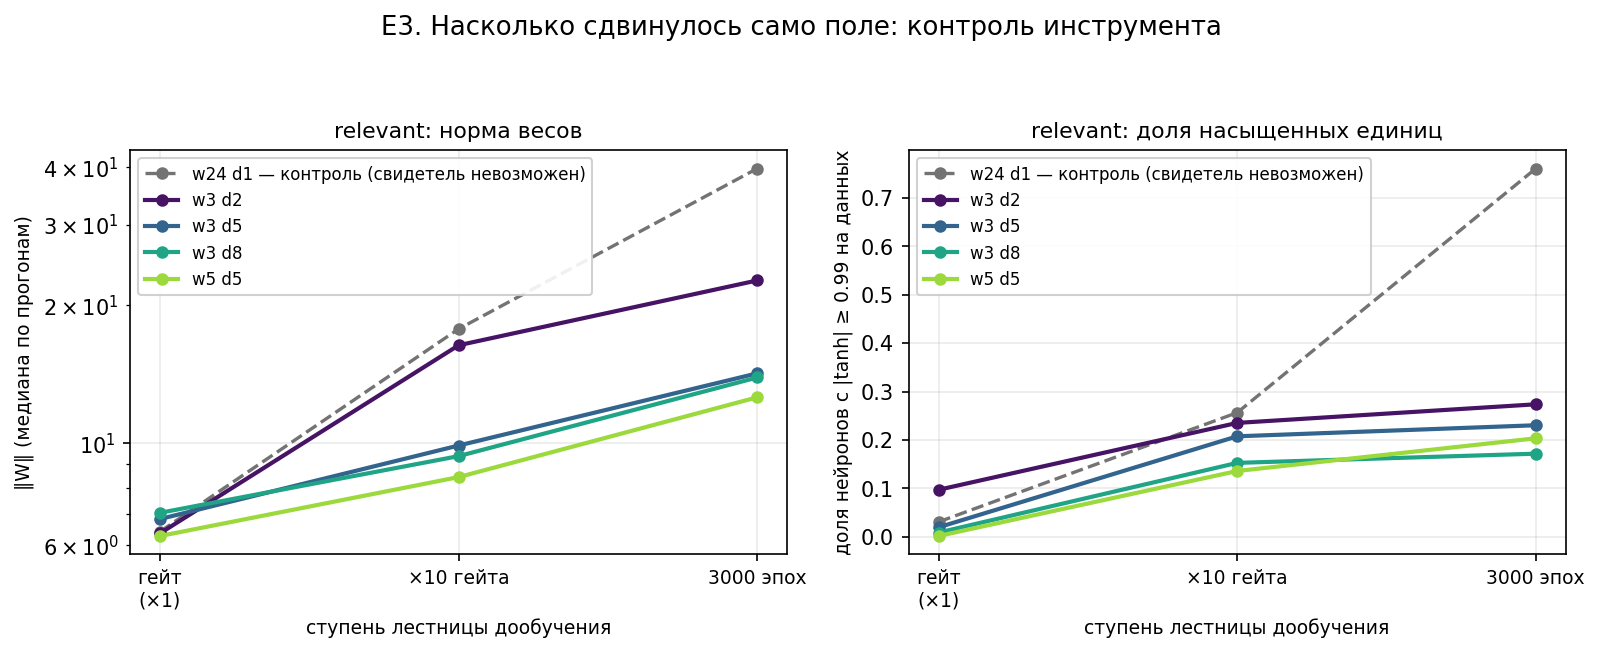

медианы по прогонам, ‖W‖ / доля насыщенных / средний |логит|:
  relevant:
    tanh_w3_d2    ‖W‖   6.36 →  16.36 →  22.65   насыщ 0.097 → 0.235 → 0.274   |логит|   1.86 →  14.64 →  22.52
    tanh_w3_d5    ‖W‖   6.84 →   9.89 →  14.21   насыщ 0.020 → 0.208 → 0.230   |логит|   3.13 →  10.58 →  19.67
    tanh_w5_d5    ‖W‖   6.28 →   8.44 →  12.60   насыщ 0.002 → 0.136 → 0.203   |логит|   2.75 →   8.19 →  20.74
    tanh_w3_d8    ‖W‖   7.05 →   9.38 →  13.92   насыщ 0.009 → 0.153 → 0.172   |логит|   3.38 →  10.32 →  19.66
    tanh_w24_d1   ‖W‖   6.42 →  17.76 →  39.74   насыщ 0.031 → 0.256 → 0.760   |логит|   0.66 →   6.77 →  22.52
  irrelevant:
    tanh_w3_d2    ‖W‖   2.28 →   4.88 →  12.59   насыщ 0.012 → 0.137 → 0.515   |логит|   0.90 →   5.02 →  19.24
    tanh_w3_d5    ‖W‖   3.48 →   5.52 →  12.80   насыщ 0.005 → 0.034 → 0.220   |логит|   0.75 →   4.39 →  19.26
    tanh_w5_d5    ‖W‖   4.17 →   5.71 →  11.16   насыщ 0.017 → 0.047 → 0.231   |логит|   1.36 →   5.10 →  20.31
    tanh_w3_d8  

In [39]:
sat = aw.saturation_table(ot)
sat.to_csv(AGG / "overtrain_saturation.csv", index=False)

ap.plot_rung_ladder([
    dict(title="relevant: норма весов", table=sat[sat.dataset_type == REL],
         value="weight_norm", ylabel="‖W‖ (медиана по прогонам)", log_y=True,
         highlight="tanh_w24_d1"),
    dict(title="relevant: доля насыщенных единиц", table=sat[sat.dataset_type == REL],
         value="saturated_fraction", ylabel="доля нейронов с |tanh| ≥ 0.99 на данных",
         highlight="tanh_w24_d1"),
], suptitle="E3. Насколько сдвинулось само поле: контроль инструмента",
   save_path=FIG / "E3_overtrain_saturation.png")
show(FIG / "E3_overtrain_saturation.png")

print("медианы по прогонам, ‖W‖ / доля насыщенных / средний |логит|:")
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    print(f"  {name}:")
    for b in BASES:
        vals = [sat[(sat.dataset_type == ds) & (sat.base == b) & (sat.rung == k)].iloc[0]
                for k in RUNGS]
        print(f"    {b:12s}  ‖W‖ " + " → ".join(f"{v.weight_norm:6.2f}" for v in vals)
              + "   насыщ " + " → ".join(f"{v.saturated_fraction:.3f}" for v in vals)
              + "   |логит| " + " → ".join(f"{v.logit_abs_mean:6.2f}" for v in vals))

### Что видно на E3

**Поле уезжает очень сильно.** На `relevant` норма весов растёт вдвое-вшестеро, доля насыщенных
единиц — с сотых долей до 0.14–0.27, средний модуль логита — с 2–3 до 20. Это не тонкая поправка:
за три тысячи эпох сеть переходит в качественно другой режим.

**И самое сильное движение поля происходит там, где скор двигается меньше всего.** Рекорд по
насыщению — контрольная `w24 d1` на relevant: норма весов **6.4 → 39.7**, доля насыщенных
**0.031 → 0.760**, то есть к концу три четверти её нейронов стоят в насыщении. Скор при этом
сдвигается на −0.0032 — в двадцать три раза меньше, чем у `w3 d2`, где поле уехало **слабее**
(0.097 → 0.274).

Отсюда прямой вывод: **эффект E1 — не артефакт съехавшей шкалы.** Если бы скор двигала перестройка
размаха, сильнее всего он двигался бы в самой насыщенной ячейке; наблюдается обратное.

**Одна честная граница.** На `simple_irrelevant` контроль сдвигается на −0.021 при том, что поле там
уехало слабее, чем на relevant. Значит базовая линия критерия зависит не только от насыщения, и
объяснения этому у нас нет. Практическое следствие уже записано в E2: на нерелевантном датасете
движения скора порядка 0.01–0.02 читать нельзя, читать можно только счёт свидетелей.

---

## Итог по E

**1. Дообучение улучшает выделение релевантной окружности — на всех способных ячейках.** Парная
разность с гейтом отрицательна везде и нигде не накрывает ноль: от −0.0055 при `w3 d5` до **−0.0728**
при `w3 d2`. Сравнение внутримодельное, поэтому дисперсия по инициализациям из него исключена
полностью.

**2. Наблюдаемая корреляция «дольше учился — хуже» была отбором, а не причинностью.** Внутри `w3 d5`
она равнялась +0.70; парный эффект имеет противоположный знак. Медленные прогоны действительно хуже —
но потому, что им досталась плохая инициализация, а не потому, что они долго учились. Это ровно тот
вопрос, ради которого пункт E и делался, и наблюдением он не решался в принципе.

**3. Конфаунд «ширина против длительности» действует ПРОТИВ вывода B, а не за него.** Широкие сети
останавливаются в четырнадцать раз раньше узких, а раннее прекращение обучения скор ухудшает. Значит
измеренное преимущество ширины — оценка **снизу**, и снятие конфаунда его только усилит. Выводы A и B
по оси ширины после E можно читать без оговорки.

**4. Минимальной сети не хватает времени, а не ёмкости.** У `w3 d2` — шести нейронов — на гейте
свидетель есть у 41 % моделей, после дообучения у **100 %**, а лучший скор падает с 0.1025 до 0.0327,
вровень с эталоном. Ёмкости шести нейронов достаточно; гейт просто останавливает сеть раньше, чем она
успевает окружность выделить.

**5. Слишком долгое обучение начинает вредить — но только по структурному критерию.** Оптимум стоит
на ступени `×10` (примерно десять гейтов), а к трём тысячам эпох часть выигрыша теряется: −0.0109
против −0.0091 у `w5 d5`. Гомологическая доля при этом растёт монотонно до самого конца. Это тот же
контраст, что в C2 на хвосте глубоких сетей: замкнутых линий уровня становится больше, а похожими на
нашу окружность они быть перестают.

**6. Нерелевантную окружность дообучение не создаёт.** Ноль свидетелей во всех пятнадцати парах
(ячейка, ступень), гомологический margin отрицателен везде. Вместе с A и `w40 d5` incidental-вопрос
закрыт с трёх сторон: ни ёмкость, ни ширина, ни время.

**7. Эффект не является артефактом инструмента.** За три тысячи эпох поле уезжает радикально (норма
весов до шести раз, доля насыщенных до 0.76), но **самое сильное движение поля происходит в
контрольной ячейке, где скор двигается меньше всего**. Контроль на relevant сдвигается на −0.0032
против −0.0728 у `w3 d2`.

### Чего E не показывает

* **На нерелевантном датасете движения скора не интерпретируемы**: контрольная ячейка гуляет там
  сильнее целевых (−0.021). Интерпретируем только счёт свидетелей, и он нулевой.
* **Лестница построена от гейта каждого прогона**, поэтому «ступень ×10» — это разные абсолютные
  эпохи в разных ячейках. Сравнивать ячейки между собой по ступеням нельзя; сравнивается каждая
  ячейка сама с собой.
* **Ступень `×10` есть не у всех прогонов** (37 из 56 при `w3 d2`), и всё сравнение ведётся на общем
  подмножестве. Числа на полном множестве прогонов от этих отличаются.
* **Почему базовая линия критерия дрейфует на `simple_irrelevant`**, эти данные не объясняют.

---

# F. Другие функции активации

Весь эксперимент — и весь проект — построен на `tanh`: морсовская рамка требует гладкости, и все
пятнадцать архитектур пула сделаны на ней. Значит любой вывод по умолчанию сопровождается молчаливой
оговоркой «при этой активации». Здесь оговорка проверяется на эталонной ячейке `w5 d5`, по 50 попыток
на каждом датасете.

**Две активации взяты с разными ролями, и путать их нельзя.**

**Sigmoid — это контроль инструмента, а не проверка обобщения.** `σ(z) = (tanh(z/2) + 1) / 2`, то
есть сеть на сигмоидах и сеть на `tanh` пробегают **один и тот же класс функций**: любая сигмоидная
сеть получается из tanh-сети переписыванием весов. Поэтому ответ обязан совпасть, а расхождение будет
свидетельством о критерии, а не о сетях.

**ReLU — настоящая проверка обобщения.** Класс другой: поле кусочно-линейно и негладко, морсовская
рамка на него не распространяется, линии уровня — ломаные. Здесь любой исход содержателен.

**Одна методологическая оговорка, объявленная заранее.** Спека фиксирует `activation=None`, то есть
101 уровень раскладывается равномерно по **наблюдённому размаху** поля. Для ReLU поле неотрицательно
и тяжелохвосто, и в `criterions.make_candidate_levels` для такого случая есть экспоненциальная сетка.
Линейная выбрана **сознательно, ради сравнимости** со всем остальным пулом; если результат упрётся в
сетку, это будет видно по тому, что ReLU проиграет всюду сразу.

---

### F1. Тот же вердикт или другой

**Что рисуем.** Знакомые полосы: точка — пара (модель, фича) по её лучшему нейрону, красный пунктир —
`τ`, детекция это лево. Шесть пар строк: три активации × два датасета, у каждой цель и пол её же
ячейки.

**Что хотим увидеть.** Главный вопрос — переносится ли **вердикт**: релевантная окружность
детектируется, нерелевантная нет. Это утверждение про сторону порога, и оно должно быть одинаковым у
всех трёх активаций, иначе весь эксперимент оказывается утверждением про `tanh`.

**И сразу второй вопрос, который эта фигура делает видимым.** Серые облака — полы — у трёх активаций
стоят в разных местах. Если это так, то сравнивать между активациями сырые скоры нельзя: пол и есть
масштаб, свой у каждой активации.

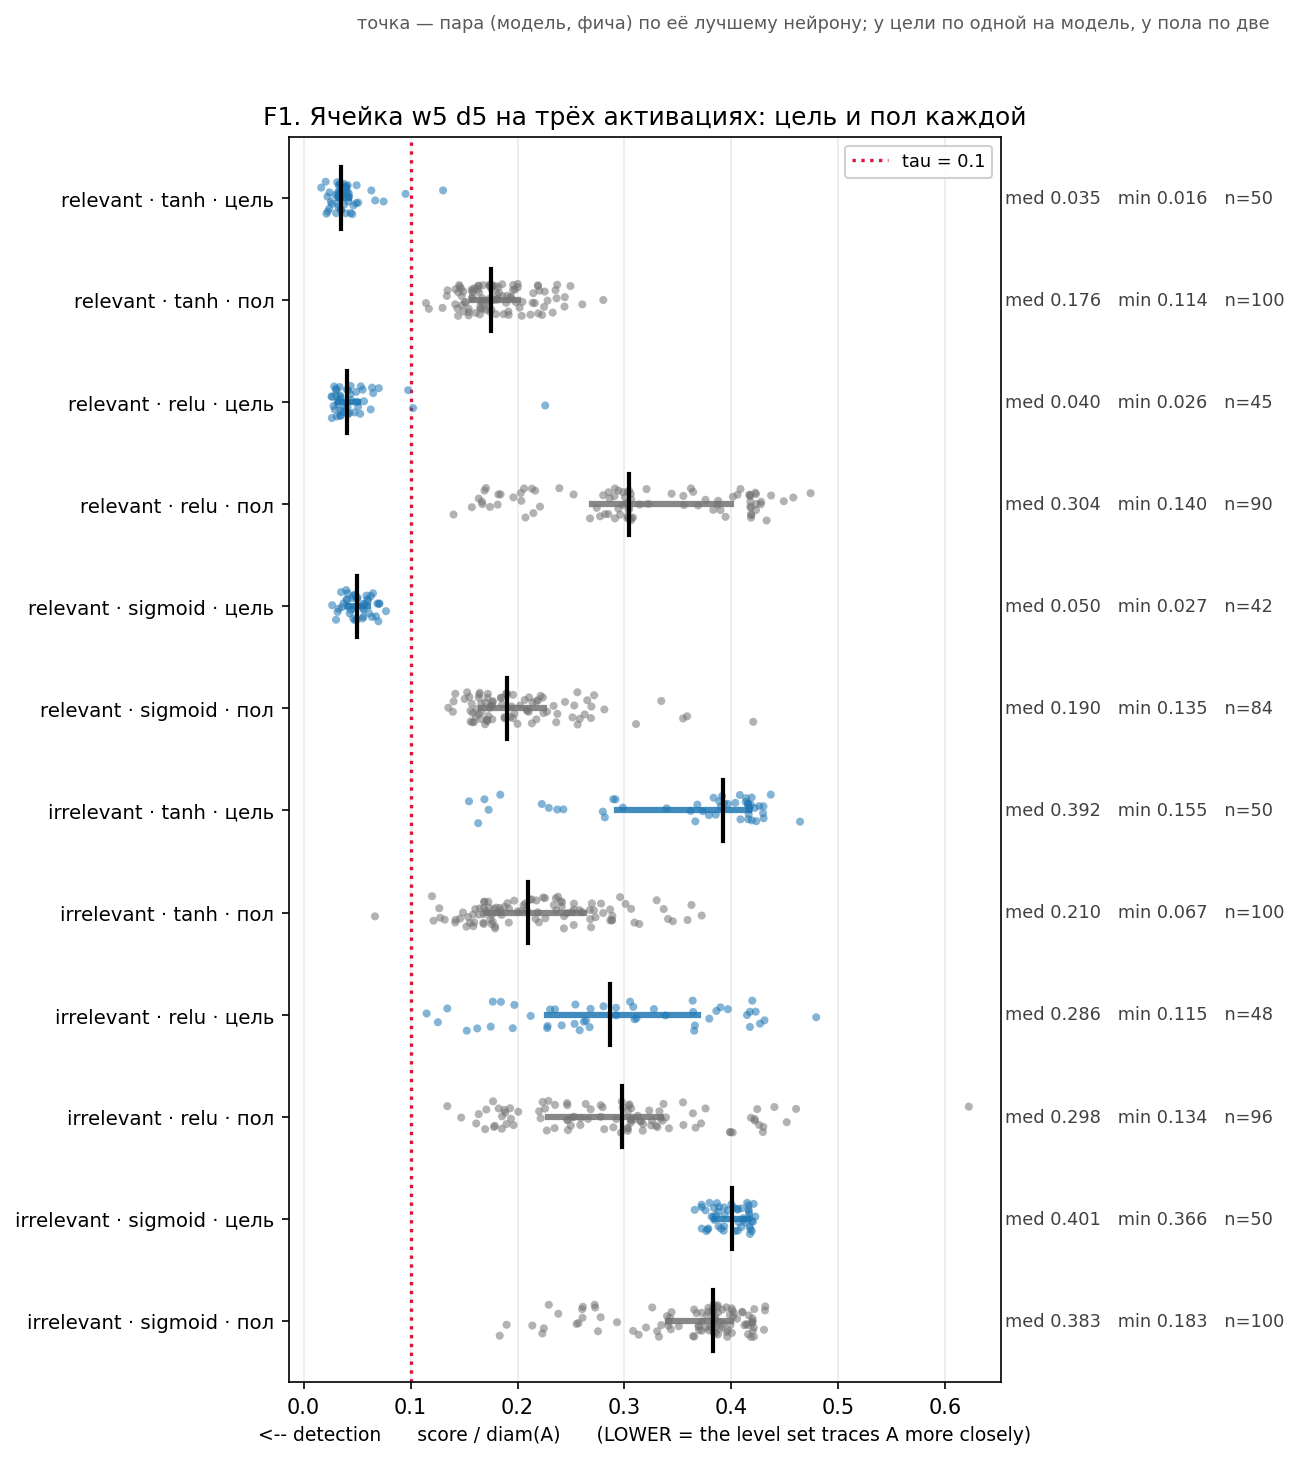

,датасет,активация,моделей,доля свид.,цель,пол,цель/пол,p_superior,эпох
0,relevant,tanh,50,0.4192,0.0349,0.1756,0.1990,0.9994,41.0
1,relevant,relu,45,0.3902,0.0405,0.3041,0.1332,0.9951,47.0
2,relevant,sigmoid,42,0.7410,0.0499,0.1899,0.2627,1.0000,262.5
3,irrelevant,tanh,50,0.0000,0.3923,0.2101,1.8668,0.1232,12.0
4,irrelevant,relu,48,0.0000,0.2862,0.2979,0.9608,0.4961,17.5
5,irrelevant,sigmoid,50,0.0000,0.4010,0.3828,1.0474,0.2960,48.0


In [40]:
EXT = EXPERIMENTS["exp2_extended"]
ext_all = aw.load_neuron_stats(EXT.results_dir)
ACT_TAGS = ["tanh_w5_d5_mass-train", "relu_w5_d5", "sigmoid_w5_d5"]
NAMES = {"tanh_w5_d5_mass-train": "tanh", "relu_w5_d5": "relu",
         "sigmoid_w5_d5": "sigmoid"}

df_act = pd.concat([df[df.arch == "w5 d5"],
                    ext_all[ext_all.tag.isin(["relu_w5_d5", "sigmoid_w5_d5"])]],
                   ignore_index=True)
scores_act = aw.to_scores(df_act)

groups = []
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for tag in ACT_TAGS:
        groups.append((f"{name} · {NAMES[tag]} · цель",
                       {"dataset": ds, "tag": tag, "role": "target"}, "tab:blue"))
        groups.append((f"{name} · {NAMES[tag]} · пол",
                       {"dataset": ds, "tag": tag, "role": "null"}, "0.45"))
plot_unit_strips(scores_act, "structural", groups, threshold=aw.TAU,
                 title="F1. Ячейка w5 d5 на трёх активациях: цель и пол каждой",
                 caption="точка — пара (модель, фича) по её лучшему нейрону; "
                         "у цели по одной на модель, у пола по две",
                 save_path=FIG / "F1_activations_strips.png")
show(FIG / "F1_activations_strips.png")

from analysis.calibration import superiority_probability
rows = []
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for tag in ACT_TAGS:
        b = df_act[(df_act.dataset_type == ds) & (df_act.tag == tag)]
        t = b[b.feature_role == "target"].groupby("model_path").score.min()
        n = b[b.feature_role == "null"].groupby(["model_path", "feature_name"]).score.min()
        rows.append({"датасет": name, "активация": NAMES[tag], "моделей": len(t),
                     "доля свид.": b[b.feature_role == "target"].witness.mean(),
                     "цель": t.median(), "пол": n.median(),
                     "цель/пол": t.median() / n.median(),
                     "p_superior": superiority_probability(t.to_numpy(), n.to_numpy()),
                     "эпох": b.groupby("model_path").train_stopped_epoch.first().median()})
act_table = pd.DataFrame(rows)
act_table.to_csv(AGG / "activation_comparison.csv", index=False)
display(act_table.round(4))

### Что видно на F1

**Вердикт переносится полностью.** На `simple_relevant` все три активации детектируют окружность:
доля моделей со свидетелем 0.98 / 0.96 / 1.00, `p_superior` против собственного пола 0.9994 / 0.9951
/ 1.0000. На `simple_irrelevant` **ни одна не детектирует ничего**: ноль свидетелей из 25 нейронов ×
(42…50) моделей у каждой, и ноль же на нулевых размещениях. Главный результат эксперимента — что
детектируется признак, нужный задаче, и не детектируется побитово такой же ненужный — **от активации
не зависит**.

**А вот числа зависят, и сильно — причём пол ездит не меньше цели.**

| датасет | активация | доля | цель | пол | **цель/пол** | эпох |
|---|---|---|---|---|---|---|
| relevant | tanh | 0.419 | 0.0349 | 0.176 | 0.199 | 41 |
| relevant | relu | 0.390 | 0.0405 | **0.304** | **0.133** | 47 |
| relevant | sigmoid | **0.741** | 0.0499 | 0.190 | 0.263 | **262** |
| irrelevant | tanh | 0.000 | 0.392 | 0.210 | 1.867 | 12 |
| irrelevant | relu | 0.000 | 0.286 | 0.298 | **0.961** | 18 |
| irrelevant | sigmoid | 0.000 | 0.401 | 0.383 | 1.047 | 48 |

**Порядок по сырому скору и порядок по отношению к полу — противоположны.** По медиане лучшего лучшей
выглядит `tanh` (0.0349), худшей `sigmoid` (0.0499). По отношению цели к собственному полу — то есть
по единственной величине, которая не зависит от того, насколько «богата» линиями уровня данная
активация вообще, — лучшей оказывается **`relu` (0.133)**, а худшей `sigmoid` (0.263). Причина видна
в столбце пола: у `relu` он в 1.7 раза выше tanh-овского, то есть на кусочно-линейных полях случайно
попасть в произвольную окружность **труднее**, и потому попадание в нужную стоит дороже.

**Практическое следствие, которое надо унести:** сравнивать скоры между активациями нельзя. Пол и
есть масштаб, и он свой у каждой. Это то же правило переноса, что уже работало по ширине, только
теперь по ещё одной оси.

**И одна оговорка, которую надо сделать прямо.** На нерелевантном датасете у `tanh` цель набирает
заметно хуже собственного пола (отношение 1.87), а у `relu` они неразличимы (0.961). Читать это как
свойство активаций нельзя: **нуль-фичи подбирались под `tanh`** — из нескольких размещений оставлены
те, что дают на tanh-сетях самый низкий скор, именно чтобы получить оценку снизу. Для `relu` и
`sigmoid` оценкой снизу были бы, вообще говоря, другие окружности, и их никто не искал. Поэтому
сравнивать отношение цель/пол **между активациями** на нерелевантном датасете некорректно; сравнивать
его внутри одной активации — можно, и на relevant это и делается. Вывод пункта от этого не зависит:
свидетелей ноль у всех трёх.

**Обучаемость тоже различается, и это результат.** Из пятидесяти попыток задачу решают: `tanh` — все
50, `relu` — 45, `sigmoid` — 42, причём `sigmoid` тратит на это в шесть раз больше эпох (262 против
41). На нерелевантном датасете, который проще, — 50, 48 и 50.

---

### F2. Почему у sigmoid доля свидетелей вдвое выше, чем у tanh

Одно число из таблицы F1 требует объяснения отдельно. У `sigmoid` **доля свидетелей 0.741** против
0.419 у `tanh` — почти вдвое больше, — но лучший нейрон при этом **хуже**: 0.0499 против 0.0349. Обе
величины считаются на одном и том же ансамбле одним и тем же критерием, и вместе они выглядят
противоречиво: как может быть больше нейронов, обводящих окружность, и при этом ни одного, обводящего
её хорошо?

Ответов ровно три, и они различимы.

1. **Распределение сдвинуто влево целиком** — тогда `sigmoid` действительно лучше, а лучший нейрон
   портит какая-то мелочь.
2. **Распределение сжато у порога** — многие нейроны проходят `τ` едва-едва, но ни один не подходит
   к окружности близко. Тогда 0.741 — свойство того, где стоит порог, а не сети.
3. **Дело в длительности обучения.** `sigmoid` учится в шесть раз дольше (262 эпохи против 41), а
   пункт E показал, что дообучение долю поднимает.

**Что рисуем.** Первая фигура — распределения скора по **всем** нейронам на `simple_relevant`, по
одному облаку на активацию: бледная гистограмма — все нейроны, вертикаль — медиана лучшего на модель,
красный пунктир — `τ`. Она различает исходы 1 и 2 напрямую, по форме облака.

Вторая фигура — то же вторым критерием: `persistence_margin` по всем нейронам, ноль — граница
вердикта. Гомологический критерий не знает ни про `τ`, ни про то, где стоит `A`, поэтому он говорит
независимо, действительно ли у sigmoid-нейронов чаще есть замкнутая линия уровня.

Исход 3 проверяется под фигурами числами: `sigmoid` на его 262 эпохах сравнивается не с гейтом
`tanh`, а с **лестницей E** — с состоянием тех же tanh-сетей на сопоставимой длительности.

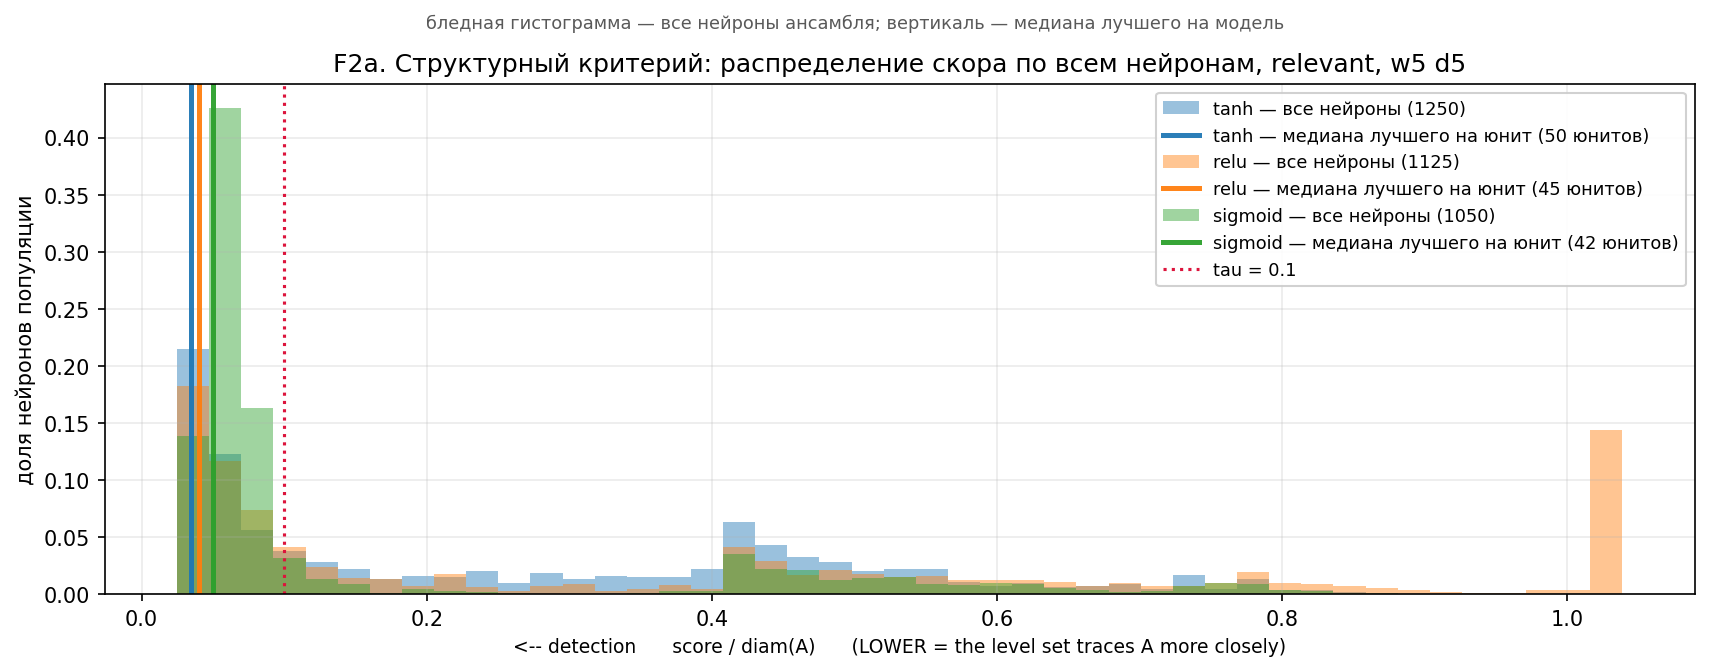

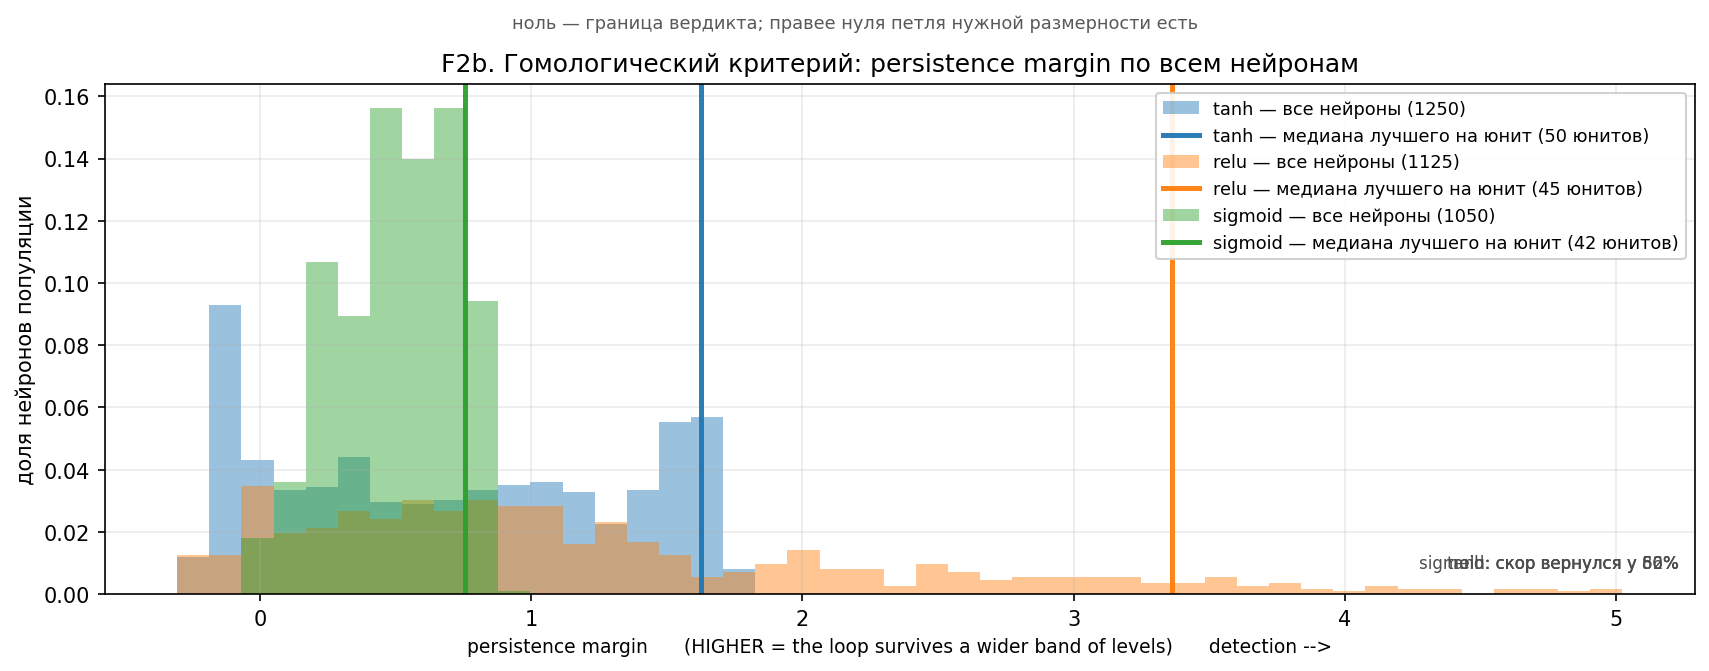

чувствительность доли к порогу, relevant:
  τ = 0.05:  tanh 0.254  relu 0.197  sigmoid 0.226
  τ = 0.10:  tanh 0.419  relu 0.390  sigmoid 0.741
  τ = 0.15:  tanh 0.485  relu 0.445  sigmoid 0.776

форма распределения: где стоят нейроны относительно порога
  tanh    : скор < 0.05 у 0.254; в [0.05, 0.10] у 0.166
  relu    : скор < 0.05 у 0.197; в [0.05, 0.10] у 0.193
  sigmoid : скор < 0.05 у 0.226; в [0.05, 0.10] у 0.515

sigmoid против лестницы дообучения tanh (та же ячейка, разная длительность):
  tanh, ступень x1  , эпоха    43:  доля 0.4269  лучший 0.0363
  tanh, ступень x10 , эпоха   439:  доля 0.5127  лучший 0.0266
  tanh, ступень end , эпоха  2999:  доля 0.4702  лучший 0.0292
  sigmoid, гейт,       эпоха   262:  доля 0.7410  лучший 0.0499
  relu   , гейт,       эпоха    47:  доля 0.3902  лучший 0.0405

мёртвые нейроны и доля свидетелей среди живых:
  relevant    tanh    : поле постоянно на фиче у 0.000; доля свидетелей от всех 0.419, среди живых 0.419; гомологическая доля 0.5280
 

In [41]:
from visualization.calibration_plots import plot_populations

POP = [(NAMES[t], {"dataset": REL, "tag": t, "role": "target"}, c)
       for t, c in zip(ACT_TAGS, ("tab:blue", "tab:orange", "tab:green"))]
plot_populations(scores_act, "structural", POP, threshold=aw.TAU,
                 title="F2a. Структурный критерий: распределение скора по всем нейронам, "
                       "relevant, w5 d5",
                 caption="бледная гистограмма — все нейроны ансамбля; "
                         "вертикаль — медиана лучшего на модель",
                 save_path=FIG / "F2a_activation_populations.png")
show(FIG / "F2a_activation_populations.png")

# Тот же срез вторым критерием. Направление у него обратное (больше = лучше),
# plot_populations берёт его из calibration.DIRECTIONS сам.
plot_populations(scores_act, "homological", POP,
                 title="F2b. Гомологический критерий: persistence margin по всем нейронам",
                 caption="ноль — граница вердикта; правее нуля петля нужной размерности есть",
                 save_path=FIG / "F2b_activation_homological.png")
show(FIG / "F2b_activation_homological.png")

print("чувствительность доли к порогу, relevant:")
for tau in (0.05, 0.10, 0.15):
    line = "  ".join(
        f"{NAMES[t]} "
        f"{(df_act[(df_act.dataset_type == REL) & (df_act.tag == t) & (df_act.feature_role == 'target')].score <= tau).mean():.3f}"
        for t in ACT_TAGS)
    print(f"  τ = {tau:.2f}:  {line}")

print("\nформа распределения: где стоят нейроны относительно порога")
for tag in ACT_TAGS:
    b = df_act[(df_act.dataset_type == REL) & (df_act.tag == tag)
               & (df_act.feature_role == "target")]
    print(f"  {NAMES[tag]:8s}: скор < 0.05 у {(b.score < 0.05).mean():.3f}; "
          f"в [0.05, 0.10] у {b.score.between(0.05, 0.10).mean():.3f}")

print("\nsigmoid против лестницы дообучения tanh (та же ячейка, разная длительность):")
ot_f = aw.load_overtraining(EXT.results_dir)
for r in aw.paired_rungs(ot_f, REL, "tanh_w5_d5", n_boot=500).itertuples():
    print(f"  tanh, ступень {r.rung:4s}, эпоха {r.median_epoch:5.0f}:  "
          f"доля {r.fraction:.4f}  лучший {r.median_best:.4f}")
for tag in ("sigmoid_w5_d5", "relu_w5_d5"):
    t = df_act[(df_act.dataset_type == REL) & (df_act.tag == tag)
               & (df_act.feature_role == "target")]
    print(f"  {NAMES[tag]:7s}, гейт,       эпоха "
          f"{t.groupby('model_path').train_stopped_epoch.first().median():5.0f}:  "
          f"доля {t.witness.mean():.4f}  лучший {t.groupby('model_path').score.min().median():.4f}")

print("\nмёртвые нейроны и доля свидетелей среди живых:")
for ds, name in ((REL, "relevant"), (IRR, "irrelevant")):
    for tag in ACT_TAGS:
        b = df_act[(df_act.dataset_type == ds) & (df_act.tag == tag)
                   & (df_act.feature_role == "target")]
        dead = (b.field_grad_norm_on_feature < 1e-9).mean()
        print(f"  {name:11s} {NAMES[tag]:8s}: поле постоянно на фиче у {dead:.3f}; "
              f"доля свидетелей от всех {b.witness.mean():.3f}, "
              f"среди живых {b.witness.mean() / max(1e-9, 1 - dead):.3f}; "
              f"гомологическая доля {b.hom_witness.fillna(False).mean():.4f}")


### Что видно на F2

**Исход 2 подтверждается: распределение `sigmoid` не сдвинуто влево, а прижато к порогу.** Больше
половины его нейронов — **51.5 %** — попадают в узкую полосу [0.05, 0.10], то есть проходят `τ` совсем
чуть-чуть; у `tanh` в той же полосе 16.6 %. А в области действительно хороших значений, ниже 0.05,
`sigmoid` уже **не выигрывает**: 22.6 % против 25.4 % у `tanh`.

Прямая проверка этого — сдвинуть порог. Если доля 0.741 держится на скоплении у самого порога, при
более строгом пороге она обязана рассыпаться:

| порог | tanh | relu | sigmoid |
|---|---|---|---|
| τ = 0.15 | 0.485 | 0.445 | **0.776** |
| τ = 0.10 | 0.419 | 0.390 | **0.741** |
| τ = 0.05 | **0.254** | 0.197 | 0.226 |

При `τ = 0.05` порядок **переворачивается**: `sigmoid` из лучшего становится хуже `tanh`.

**Исход 3 отпадает.** Лестница E даёт для `tanh` в той же ячейке: гейт (43 эпохи) — доля 0.427,
лучший 0.0363; `×10` (439 эпох) — 0.513 и 0.0266. То есть шестикратное дообучение поднимает долю
`tanh` с 0.427 до 0.513, а `sigmoid` на своих 262 эпохах даёт 0.741 — вчетверо больше, чем даёт
длительность. И главное: у `tanh` дообучение лучший нейрон **улучшает** (0.0363 → 0.0266), а
`sigmoid` на сопоставимой длительности стоит на 0.0499. Разница по лучшему нейрону временем не
объясняется.

**А вот исход 1 отпадает не целиком, и это уточняет вывод.** Вторая фигура показывает, что
гомологический критерий — который не знает ни про `τ`, ни про то, где стоит `A`, — тоже ставит
`sigmoid` выше: доля нейронов с петлёй нужной размерности равна **0.786** против 0.528 у `tanh` и
0.466 у `relu`. То есть у sigmoid-нейронов **действительно чаще есть замкнутая линия уровня**, и это
не артефакт порога.

Складывая две фигуры, получаем точную формулировку: **у `sigmoid` замкнутых линий уровня больше, но
лежат они вокруг окружности свободнее.** Много петель, проходящих мимо `A` на расстоянии чуть меньше
`τ`, и ни одной, облегающей её плотно. Ни «лучше», ни «хуже» — другое распределение, и порог `τ`
разрезает его в неудачном месте.

**У `relu` обнаружилась своя особенность, и она про знаменатель.** У **25.6 %** его нейронов норма
градиента поля на целевой фиче равна нулю машинно — это мёртвые ReLU, на этой области они не
активируются вовсе. Они дают пик у скора ≈ 1.0 на первой фигуре и не могут свидетельствовать в
принципе, ровно как нейроны слоя 0. Если считать долю от **живых** нейронов, `relu` даёт **0.524**
против 0.419 у `tanh` — то есть по-настоящему он не хуже, а лучше. На нерелевантном датасете мёртвых
ещё больше, 29.7 %.

**Одно предупреждение про гомологический критерий на ReLU.** На нерелевантном датасете доля его
срабатываний равна 0.0150 у `relu` против 0.0016 у `tanh` — на порядок больше. Кусочно-линейное поле
даёт замкнутые ломаные там, где гладкое ничего не даёт. Структурного вердикта это не меняет
(свидетелей ноль), но при переносе гомологического критерия на негладкие активации порог придётся
перекалибровать.

---

## Итог по F

**1. Главный результат эксперимента от активации не зависит.** Релевантная окружность детектируется
всеми тремя (`p_superior` 0.995–1.000 против собственного пола, свидетель есть у 96–100 % моделей),
нерелевантная — **ни одной**: ноль свидетелей у всех трёх, и на цели, и на нулевых размещениях. Это
и есть та проверка, ради которой пункт делался, и `tanh` в нём ничем не выделен.

**2. Сравнивать сырые скоры между активациями нельзя — пол и есть масштаб.** По медиане лучшего
нейрона порядок `tanh` < `relu` < `sigmoid` (0.0349 / 0.0405 / 0.0499), а по отношению цели к
собственному полу порядок **обратный**: `relu` 0.133 < `tanh` 0.199 < `sigmoid` 0.263. У `relu` пол
в 1.7 раза выше, то есть случайно попасть в произвольную окружность кусочно-линейным полем труднее, и
попадание в нужную стоит дороже. Это то же правило переноса, что уже работало по ширине.

**3. У `sigmoid` замкнутых линий уровня больше, но лежат они свободнее.** Его доля свидетелей 0.741
против 0.419 у `tanh`, и гомологический критерий подтверждает независимо (0.786 против 0.528) — то
есть петель у него действительно больше. Но лучший нейрон при этом хуже (0.0499 против 0.0349),
половина нейронов стоит в полосе [0.05, 0.10] сразу под `τ`, и при `τ = 0.05` порядок между
активациями переворачивается. Длительностью обучения это не объясняется: лестница E поднимает долю
`tanh` лишь до 0.513 и при этом лучший нейрон улучшает.

**4. У `relu` четверть нейронов мертва на целевой фиче** (`|∇f| = 0` у 25.6 % на relevant, 29.7 % на
irrelevant). Они не могут свидетельствовать по той же причине, что нейроны слоя 0, и должны
выпадать из знаменателя. С поправкой `relu` даёт долю **0.524** против 0.419 у `tanh` — то есть по
обеим честным величинам, доле среди живых и отношению к полу, ReLU оказывается **сильнее** гладкой
активации, а не слабее. Гомологический критерий, впрочем, на нём даёт на порядок больше ложных петель.

**5. Обучаемость различается, и это тоже результат.** Из пятидесяти попыток задачу решают 50 (`tanh`),
45 (`relu`) и 42 (`sigmoid`), причём `sigmoid` тратит в шесть раз больше эпох. Отчитываться надо по
фактическому N, что здесь и сделано.

### Чего F не показывает

* **Одна ячейка, одна ширина, одна глубина.** Всё выше — про `w5 d5`. Переносить на другие
  архитектуры без проверки нельзя, тем более что доля у `relu` зависит от доли мёртвых нейронов, а та
  от ширины наверняка зависит.
* **Нуль-фичи подобраны под `tanh`.** Они выбирались так, чтобы давать оценку снизу на tanh-сетях;
  для других активаций оценкой снизу были бы другие размещения. Поэтому отношение цель/пол сравнимо
  внутри активации, но не между активациями — особенно на нерелевантном датасете.
* **Сетка уровней для ReLU выбрана линейной ради сравнимости.** Для неотрицательного тяжелохвостого
  поля есть экспоненциальный вариант, и он не пробовался.
* **Гомологический порог на негладких активациях не откалиброван.**

---

# Итог эксперимента 2

Подробный разбор — **`reports/exp2_arch_sweep.md`**, а не этот ноутбук.

**Пул.** 30 ячеек, 1 500 моделей, 184 050 строк на общем боксе (`N_A = 44.222`), плюс отдельно
посчитанные ступени переобучения и две другие активации. Эталонная ячейка воспроизвела эксперимент 1
до шестого знака (0.034946), 49 моделей из 50 со свидетелем, 41.9 % свидетелей среди всех нейронов.
Теоремные контроли выполняются точно: **0 свидетелей из 45 450 строк на слое 0 и 0 из 2 250 при
ширине ≤ 2.**

---

## 1. Нерелевантную топологию не производит ни ёмкость, ни ширина, ни время

Окружность в двух датасетах побитово одна и та же; различается только её нужность задаче. На
нерелевантном датасете детекции нет **ни при каком избытке**: 0 свидетелей из 16 050 целевых строк в
четырнадцати ячейках из шестнадцати. Все семь срабатываний живут в двух самых широких ячейках
(`w20 d5` и `w40 d5`) и на первых двух слоях; три компоненты из семи обрезаны боксом.

Три независимые проверки говорят одно и то же.

* **Удвоение ширины сигнал не усиливает.** Ставка идёт 4/50 → 3/50, а нулевые размещения начинают
  срабатывать **чаще** цели: 8/100. Локальный наклон цели после −0.58 возвращается к −0.37 —
  «ускорения», из которого следовало бы пересечение `τ` за пределами пула, нет.
* **Лучшее срабатывание на этом датасете принадлежит нулю, а не цели.** 0.0667 против 0.0780, и его
  компонента целиком внутри бокса.
* **Дообучение до трёх тысяч эпох не создаёт ничего.** Ноль свидетелей во всех пятнадцати парах
  (ячейка, ступень), гомологическая доля тоже не растёт нигде.

Второй критерий приходит к тому же вердикту независимо: лучший `persistence_margin` на цели −0.017
против +1.74 на релевантной задаче.

**Пол — это оценка снизу, и говорить надо так.** Нуль-размещения выбраны вручную из соображений
покрытия задачи, и оставлены те, что дают низкий скор. Поэтому корректная формулировка — «скор на
нерелевантной окружности лежит **выше** этой нижней оценки»; утверждать, что распределения на нулевых
и нерелевантных фичах различаются, нельзя.

## 2. Релевантную топологию несёт вся сеть, а не выделенный нейрон

Доля свидетелей от ширины **не зависит** (0.385–0.428 при росте ширины в 13.3 раза, наклон
+0.021 [−0.009, +0.053]), а их число растёт пропорционально сети — с шести до восьмидесяти двух.
Каждый добавленный нейрон подхватывает окружность примерно с той же вероятностью, что и уже
имевшиеся; простаивающей ширины нет. Ширина при этом делает ансамбль и однороднее: разброс лучшего
скора падает в восемь раз (σ 0.024 → 0.003).

**Ширина покупает не только попытки.** Эталон множественности берётся из измеренного пола тех же
ячеек: цель падает как `N^(−0.315)`, пол — как `N^(−0.117)`, интервалы не пересекаются.

**Множественность считается шириной слоя, а не числом нейронов.** При одинаковом числе нейронов пол
ниже у той архитектуры, которая шире: 0.253 против 0.219 при `N = 15`, 0.177 против 0.206 при
`N = 50`, 0.198 → 0.246 вдоль диагонали равного бюджета. Правдоподобно потому, что нейроны одного
слоя — параллельные попытки, а нейроны следующего слоя суть функции от них.

**При глубине 1 кодирование обязано быть распределённым.** У `w24 d1` ни один из двадцати четырёх
нейронов не может свидетельствовать по теореме, и данные дают ровно ноль — но **выход той же сети
свидетельствует окружность у всех пятидесяти моделей**. Ноль — это утверждение о нейронах, а не о
сети.

## 3. Признак строится постепенно, и у построения есть длина

Доля свидетелей растёт от слоя к слою; внутри модели число свидетелей не падает ни разу у 96–100 %
моделей. Растёт при этом вся популяция слоя, а не её хвост. У пола и на нерелевантной окружности
такого роста нет вовсе.

**Кривая доли по слоям — не прямая, а ступенька, и её перелом стоит примерно на слое √d.** Доля
свидетелей идёт не плавно: два-три слоя почти ничего, затем резкий подъём, затем полка у единицы. При
`d = 5` это `0.000 → 0.012 → 0.328 → 0.816 → 0.940`, и **перелом — тот участок, где кривая проходит
от «почти ничего» к «почти всё»**. Численно его положение задаётся **полувысотой**: точкой, где кривая
пересекает 0.5 (при `d = 5` — слой 2.35).

Вопрос был такой: с ростом глубины перелом стоит на одном и том же **слое** (признак всегда
собирается за столько-то преобразований) или на одной и той же **доле глубины** (сеть растягивает
построение пропорционально размеру)? Ни то, ни другое:

| глубина | 2 | 3 | 5 | 8 | 10 |
|---|---|---|---|---|---|
| полувысота, номер слоя | 1.37 | 1.61 | 2.35 | 2.62 | 3.05 |
| полувысота, доля глубины | 0.68 | 0.54 | 0.47 | 0.33 | 0.31 |
| **слой / √d** | 0.97 | 0.93 | 1.05 | 0.93 | 0.97 |

При пятикратном росте глубины абсолютная полувысота растёт в 2.2 раза, а относительная во столько же
падает: обе гипотезы промахиваются одинаково и в разные стороны, а посередине между ними лежит
корень. Правило замечено на глубинах до восьмой и подтверждено на десятой (предсказание 3.16,
наблюдение 3.05), то есть подгонкой к имеющимся точкам уже не является.

Отсюда правило переноса: **утверждение о конкретном слое действительно только внутри той глубины, на
которой измерено.** «На слое 2 доля такая-то» — это про `d = 5`; при `d = 10` второй слой стоит ещё
до перелома.

**Построение занимает примерно четыре преобразования, и дальше не продолжается.** У `w5 d5` оно идёт
до последнего слоя, у `w5 d8` заканчивается на пятом, у `w5 d10` — на шестом-седьмом. Отсюда
уточнение к выводу о глубине: доля по всей сети есть по определению среднее послойных долей, поэтому
у глубокой сети она выше не потому, что признак выделяется лучше, а потому, что больше слоёв стоит
после насыщения. **Глубина увеличивает протяжённость признака, а не его качество** — что согласуется
и с худшим лучшим нейроном при `d = 8, 10`, и с худшей головой при `d = 10` (68 %).

**Два критерия расходятся на последних слоях, и это самое интересное наблюдение пункта C.** У
`d = 10` структурная доля к концу падает (0.960 → 0.956 → 0.932), а гомологическая растёт до единицы
(0.976 → 0.996 → 1.000); ни при одной глубине гомологическая кривая не спадает нигде. Замкнутые линии
уровня на глубоких слоях не исчезают — их становится больше, — а меняется их **геометрия**: они
перестают походить на нашу окружность, продолжая решать задачу.

## 4. Дообучение улучшает нужный признак и не создаёт ненужного

Ступени снимаются с **одного прогона**, поэтому сравнение внутримодельное и дисперсия по
инициализациям из него исключена.

* **Дообучение улучшает скор на всех способных ячейках**, парная разность нигде не накрывает ноль:
  от −0.0055 при `w3 d5` до **−0.0728** при `w3 d2`.
* **Наблюдаемая корреляция «дольше учился — хуже» была отбором, а не причинностью.** Внутри `w3 d5`
  она равнялась +0.70; парный эффект имеет противоположный знак. Медленные прогоны хуже потому, что
  им досталась плохая инициализация.
* **Конфаунд «ширина против длительности» действует ПРОТИВ выводов пункта B.** Широкие сети
  останавливаются в четырнадцать раз раньше узких, а раннее прекращение обучения скор ухудшает.
  Значит измеренное преимущество ширины — оценка снизу.
* **Минимальной сети не хватает времени, а не ёмкости.** У `w3 d2` — шести нейронов — на гейте
  свидетель есть у 41 % моделей, после дообучения у **100 %**, а лучший скор падает с 0.1025 до
  0.0327, вровень с эталоном.
* **Эффект не артефакт инструмента.** Поле уезжает радикально (норма весов до шести раз, доля
  насыщенных до 0.76), но самое сильное движение поля происходит в контрольной ячейке `w24 d1`, где
  скор двигается меньше всего.

## 5. Вердикт не зависит от функции активации

Релевантная окружность детектируется всеми тремя активациями (`p_superior` 0.995–1.000 против
собственного пола), нерелевантная — **ни одной**. Но числа сравнивать между активациями нельзя: по
медиане лучшего порядок `tanh` < `relu` < `sigmoid`, а по отношению к собственному полу —
**обратный** (`relu` 0.133 < `tanh` 0.199 < `sigmoid` 0.263).

У `sigmoid` замкнутых линий уровня действительно больше (гомологическая доля 0.786 против 0.528), но
лежат они вокруг окружности свободнее: половина нейронов стоит в полосе [0.05, 0.10] сразу под `τ`, и
при `τ = 0.05` порядок между активациями переворачивается. У `relu` четверть нейронов **мертва** на
целевой фиче; с поправкой на знаменатель он даёт 0.524 против 0.419 у `tanh`.

---

## Что переносится в следующие эксперименты

1. **Единица наблюдения и единица пересэмплирования** — пара (модель, фича) по её лучшему нейрону,
   бутстрап по моделям, никогда по нейронам.
2. **Множественность измеряется полом тех же ячеек, а не законом**, и считается **шириной слоя**, а
   не общим числом нейронов.
3. **Оба вырожденных класса нейронов держать в пуле** — слой 0 и ширина ≤ 2 суть единственная
   теоремная проверка валидности инструмента. К ним добавился третий: мёртвые ReLU.
4. **Утверждения о конкретном слое действительны только внутри своей глубины** (правило √d).
5. **Голову сети считать как `sigmoid(model(x))`**, а не как сырой логит.
6. **Вдоль любой оси архитектур отчитываться о длительности обучения** — она меняется вместе с
   архитектурой в разы.
7. **Скоры между активациями несравнимы**, и нуль-фичи, подобранные под одну активацию, для другой
   оценкой снизу быть не обязаны.

## Что не переносится

* **`N^(−0.28)` из эксперимента 1** — получен свипом по числу уровней на минимуме по нулевым
  нейронам; это не закон про число нейронов.
* **«Потолок инструмента» 0.0343** — в этом пуле ниже него 4 461 нейрон из 30 300, минимум 0.0147.
  Это накладные расходы конкретного зонда. Побочная находка, свипом по архитектурам не искомая.
* **Абсолютные значения долей и пола** — они привязаны к этой задаче, этому боксу и `N_A = 44.222`.
* **«Длина построения ≈ 4 слоя»** — измерена на трёх глубинах при одной ширине.

## Границы применимости

* **Ничего про необходимость.** Наблюдаемая кратность — не утверждение, что нейроны нужны. Причинный
  вопрос требует абляции, которой здесь нет.
* **Высокая доля у выхода — слабое свидетельство кодирования**, потому что граница решения на
  `simple_relevant` и есть цель. Информативны средние слои.
* **Фильтр непрерывности проверен на семи элементах** и в условиях, где разделение частично
  тавтологично.
* **На нерелевантном датасете движения скора не интерпретируемы** — контрольная ячейка гуляет там
  сильнее целевых. Интерпретируем только счёт свидетелей.
* **Одна форма фичи, одна задача, две дополнительные активации на одной ячейке.**

---

# Бюджет

> **Смета относится к основному прогону пула.** Позже к нему добавились ячейки `w40 d5` и
> `w5 d10` (а для пунктов E и F — ступени переобучения и другие активации): они считались
> отдельным прогоном на сервере, спекой `exp2_extended` с побитово той же конфигурацией оценки.
> С ними в пуле 30 ячеек и 184 050 строк.

26 ячеек (14 архитектур; ширина 1 и 2 существуют только на `simple_irrelevant`), по **50 моделей**
в каждой, 3 фичи на нейрон, оба критерия. Стоимость строки измерена на настоящем пути оценки при
R = 200 со структурным и гомологическим (delaunay, `max_sample_points = 7000`): **386 мс в один
поток** — тот режим, в котором работают шарды. В два потока та же строка стоит 327 мс: BLAS даёт
18 %, и мы от них отказываемся сознательно, потому что шард — это работа на одно ядро, а ускорение
даёт пул, а не потоки внутри шарда.

> **Поправка по факту прогона.** 386 мс — оценка с маленькой пробы, и она занижена примерно вшестеро. Фактически 109 050 строк заняли 5.2 часа на 20 ядрах, то есть около **3.4 с на строку в один поток**; сметы ниже надо читать с этим множителем.

| стадия | локально (14 ядер) | `c1.32` (32 vCPU) |
|---|---|---|
| предпроверка обучаемости | ~10 мин | ~10 мин |
| обучение (~1250 прогонов) | **~20–25 мин** | ~20–25 мин |
| оценка критериев (109 050 строк) | **~50 мин** | ~22 мин |
| **всего** | **~1 ч 25 мин** | **~55 мин** |

Оценка в один процесс — 11.7 ч; она и параллелится честно. Обучение почти везде дешёвое — гейт
срабатывает на 12–230 эпохах, это секунды на модель, — но две ячейки глубины 1 на `simple_relevant`
идут по ~1900 эпох на модель, то есть около **20 минут каждая одним процессом**. Ячейка — неделимая
единица параллелизма для обучения, поэтому именно эти две и задают время стадии, и добавлять воркеров
сверх 26 бессмысленно.

Самая дорогая ячейка оценки — `w20 d5`, 15 000 строк на датасет; шардинг режет её на куски по
~800 строк, поэтому она не задаёт время стадии.

**Про железо.** Замерено: время эпохи 12.1 мс при w5 d5 и 12.6 мс при w20 d5 — двадцатикратный рост
числа нейронов не меняет ничего, вся стоимость это диспетчеризация, а не арифметика. Поле нейрона —
1.2 % стоимости оценки; остальные 99 % это перебор уровней со связными компонентами и Чамфером,
работа по сетке. Поэтому **GPU-конфигурации бесполезны и для обучения, и для оценки**; берётся
`c1.32` (32 vCPU), а не `gt4.1` / `g1.1`.